## Customer Analytics

In [49]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Thiết lập thư mục và đọc dữ liệu
data_path = Path("data/raw/Dunnhumby/transaction_data.csv")
if not data_path.exists():
    data_path = Path("../data/raw/Dunnhumby/transaction_data.csv")

print(f"Đang đọc dữ liệu từ: {data_path}")
df_raw = pd.read_csv(data_path, usecols=["household_key", "BASKET_ID", "DAY", "SALES_VALUE"])
print(f"Tổng số dòng giao dịch thô: {len(df_raw):,}")

Đang đọc dữ liệu từ: ..\data\raw\Dunnhumby\transaction_data.csv
Tổng số dòng giao dịch thô: 2,595,732


In [50]:
# Lọc giao dịch hợp lệ (SALES_VALUE > 0) và trích xuất các ngày mua sắm duy nhất theo hộ gia đình
df_valid = (
    df_raw[df_raw["SALES_VALUE"] > 0][["household_key", "DAY"]]
    .drop_duplicates()
    .sort_values(["household_key", "DAY"])
)

# Tính khoảng cách số ngày giữa các lần ghé mua liên tiếp (Return Gap in Days)
df_valid["gap_days"] = df_valid.groupby("household_key")["DAY"].diff()
gaps = df_valid["gap_days"].dropna().astype(int)

print(f"Tổng số lượt quay lại mua sắm (Return events): {len(gaps):,}")
print(f"Số hộ gia đình phát sinh >= 2 lần mua: {df_valid['household_key'].nunique():,}")

Tổng số lượt quay lại mua sắm (Return events): 222,785
Số hộ gia đình phát sinh >= 2 lần mua: 2,500


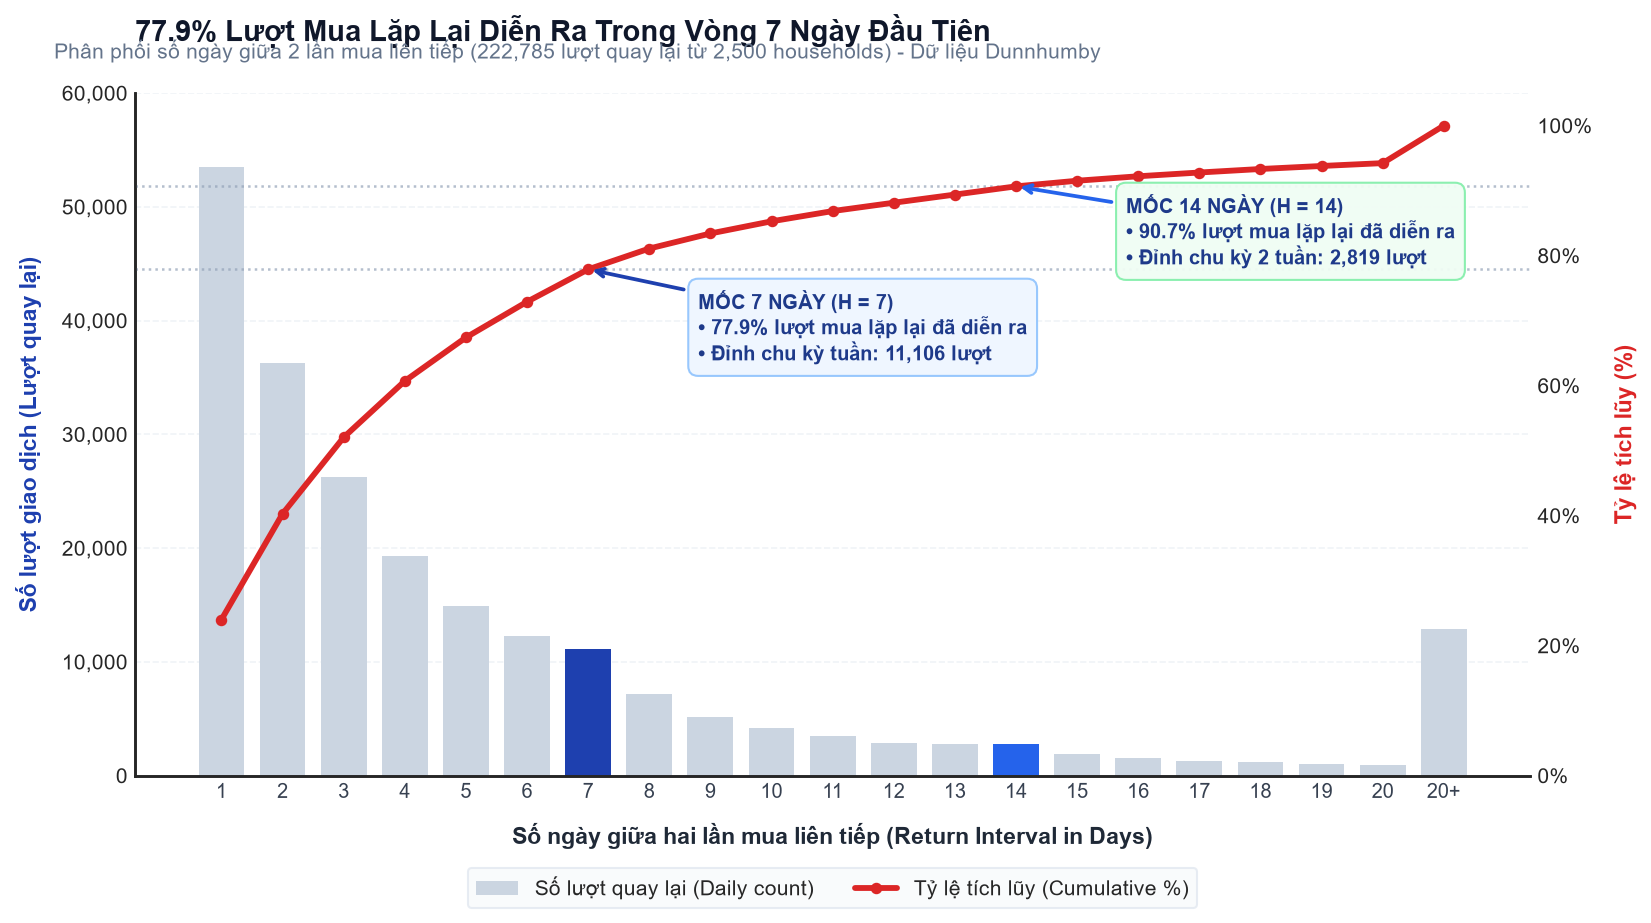

In [ ]:
# Gom nhóm phân phối từ 1 đến 20 ngày và nhóm '20+'
counts = {}
for i in range(1, 21):
    counts[str(i)] = (gaps == i).sum()

df_plot = pd.DataFrame(list(counts.items()), columns=["day", "count"])
total = len(gaps)
df_plot["pct"] = df_plot["count"] / total * 100
df_plot["cum_pct"] = df_plot["count"].cumsum() / total * 100

# VẼ BIỂU ĐỒ KẾT HỢP (COMBO BAR CHART + CUMULATIVE PERCENTAGE LINE)
plt.style.use("seaborn-v0_8-white" if "seaborn-v0_8-white" in plt.style.available else "default")
fig, ax1 = plt.subplots(figsize=(12, 6.5), dpi=150)

x = np.arange(len(df_plot))

# Màu sắc cột: Tô đậm nổi bật Ngày 7, Ngày 14
colors = []
for d in df_plot["day"]:
    if d == "7":
        colors.append("#1E40AF")  # Xanh navy đậm cho Ngày 7
    elif d == "14":
        colors.append("#2563EB")  # Xanh royal cho Ngày 14
    else:
        colors.append("#CBD5E1")  # Xám nhạt cho các ngày thường

# Trục trái: Cột tần suất số lượt quay lại từng ngày
bars = ax1.bar(x, df_plot["count"], color=colors, width=0.75, label="Số lượt quay lại (Daily count)", zorder=2)
ax1.set_xlabel("Số ngày giữa hai lần mua liên tiếp (Return Interval in Days)", fontsize=11, fontweight="bold", labelpad=10, color="#1F2937")
ax1.set_ylabel("Số lượt giao dịch (Lượt quay lại)", fontsize=11, fontweight="bold", color="#1E40AF", labelpad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(df_plot["day"], fontsize=9.5, color="#374151")
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax1.set_ylim(0, 60000)
ax1.grid(axis="y", linestyle="--", alpha=0.5, color="#E2E8F0", zorder=1)

# Trục phải: Đường cong tỷ lệ tích lũy %
ax2 = ax1.twinx()
line = ax2.plot(x, df_plot["cum_pct"], color="#DC2626", linewidth=2.8, marker="o", markersize=4.5,
                label="Tỷ lệ tích lũy (Cumulative %)", zorder=4)
ax2.set_ylabel("Tỷ lệ tích lũy (%)", fontsize=11, fontweight="bold", color="#DC2626", labelpad=10)
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter())
ax2.grid(False)

# Đường dóng ngang 77.9% và 90.7%
ax2.axhline(77.9, color="#94A3B8", linestyle=":", linewidth=1.2, alpha=0.7)
ax2.axhline(90.7, color="#94A3B8", linestyle=":", linewidth=1.2, alpha=0.7)

# Callout chú thích tại Ngày 7
idx_7 = 6
val_7 = df_plot.loc[idx_7, "cum_pct"]
count_7 = df_plot.loc[idx_7, "count"]
ax2.annotate(
    f"MỐC 7 NGÀY (H = 7)\n• 77.9% lượt mua lặp lại đã diễn ra\n• Đỉnh chu kỳ tuần: {count_7:,} lượt",
    xy=(idx_7, val_7),
    xytext=(idx_7 + 1.8, val_7 - 14),
    arrowprops=dict(arrowstyle="->", color="#1E40AF", lw=1.8),
    fontsize=9.5, fontweight="bold", color="#1E3A8A",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#EFF6FF", edgecolor="#93C5FD", alpha=0.95),
    zorder=5
)

# Callout chú thích tại Ngày 14
idx_14 = 13
val_14 = df_plot.loc[idx_14, "cum_pct"]
count_14 = df_plot.loc[idx_14, "count"]
ax2.annotate(
    f"MỐC 14 NGÀY (H = 14)\n• 90.7% lượt mua lặp lại đã diễn ra\n• Đỉnh chu kỳ 2 tuần: {count_14:,} lượt",
    xy=(idx_14, val_14),
    xytext=(idx_14 + 1.8, val_14 - 12),
    arrowprops=dict(arrowstyle="->", color="#2563EB", lw=1.8),
    fontsize=9.5, fontweight="bold", color="#1E3A8A",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F0FDF4", edgecolor="#86EFAC", alpha=0.95),
    zorder=5
)

# Tiêu đề biểu đồ
plt.title("77.9% Lượt Mua Lặp Lại Diễn Ra Trong Vòng 7 Ngày Đầu Tiên",
          fontsize=14, fontweight="bold", pad=25, loc="left", color="#0F172A")
plt.suptitle("Phân phối số ngày giữa 2 lần mua liên tiếp (222,785 lượt quay lại từ 2,500 households) - Dữ liệu Dunnhumby",
             fontsize=10, color="#64748B", x=0.08, y=0.935, ha="left")

# Ghép Legend ở phía dưới
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper center", bbox_to_anchor=(0.5, -0.12),
           ncol=2, frameon=True, facecolor="#F8FAFC", edgecolor="#E2E8F0", fontsize=10)

plt.subplots_adjust(top=0.88, bottom=0.18)
plt.show()

- Dữ liệu: Bảng marketing của Dunnhumby (causal_data) vốn chạy theo chu kỳ tuần (WEEK_NO).

- Khách hàng: 78% khách quay lại trong tuần; ngày 7 là đỉnh đi siêu thị cuối tuần.

- Marketing: Khuyến mãi siêu thị đổi mới mỗi tuần một lần; dự đoán 7 ngày cho phép can thiệp kịp thời trước khi khách bước sang tuần thứ 2 (nguy cơ mất khách).

### Customer Overview

In [53]:
# Biểu đồ phân bổ mức độ tập trung doanh thu và tần suất (Lorenz & Pareto)
fig_lorenz = plot_customer_lorenz_curves(df_summary)
plt.show()


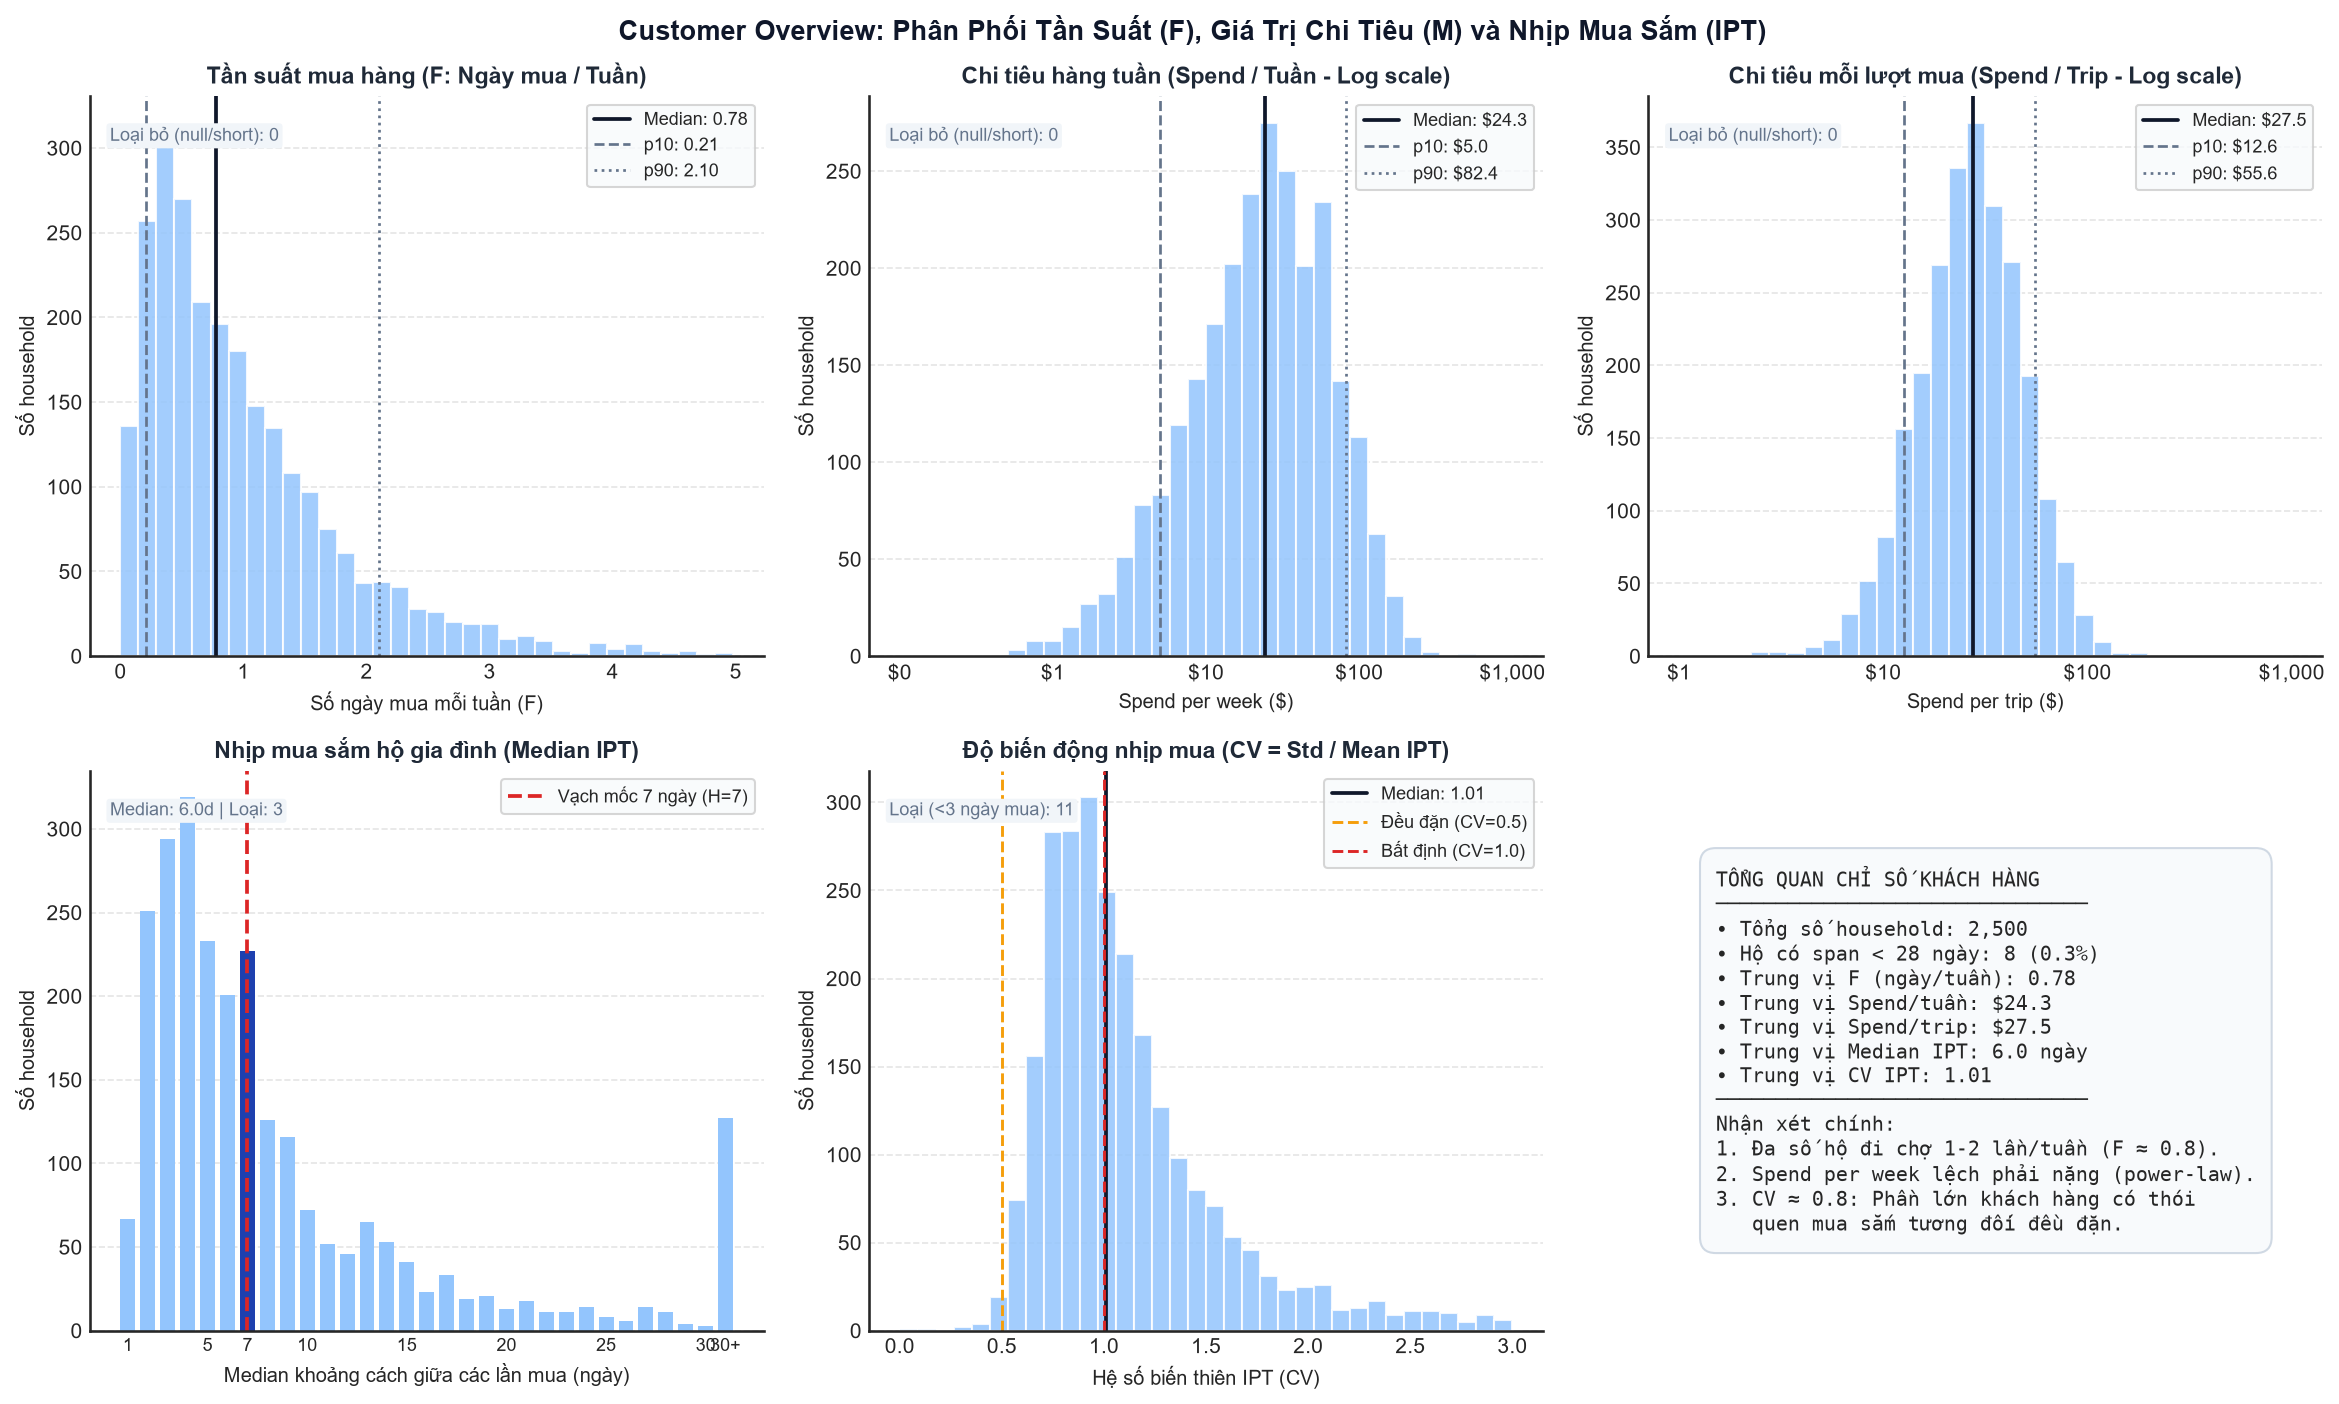

In [55]:
# 3. Biểu đồ lưới 5 phân phối (F, Spend/tuần, Spend/trip, Median IPT, CV IPT) và thẻ Executive Scorecard
fig_hist = plot_customer_overview_histograms(df_summary)
plt.show()

,metric,gini_coefficient,pct_households_for_50pct_total,pct_households_for_80pct_total,pct_total_held_by_top_20pct_households
0,total_spend,0.503,18.2,44.0,53.0
1,n_purchase_days,0.436,22.0,49.4,47.1


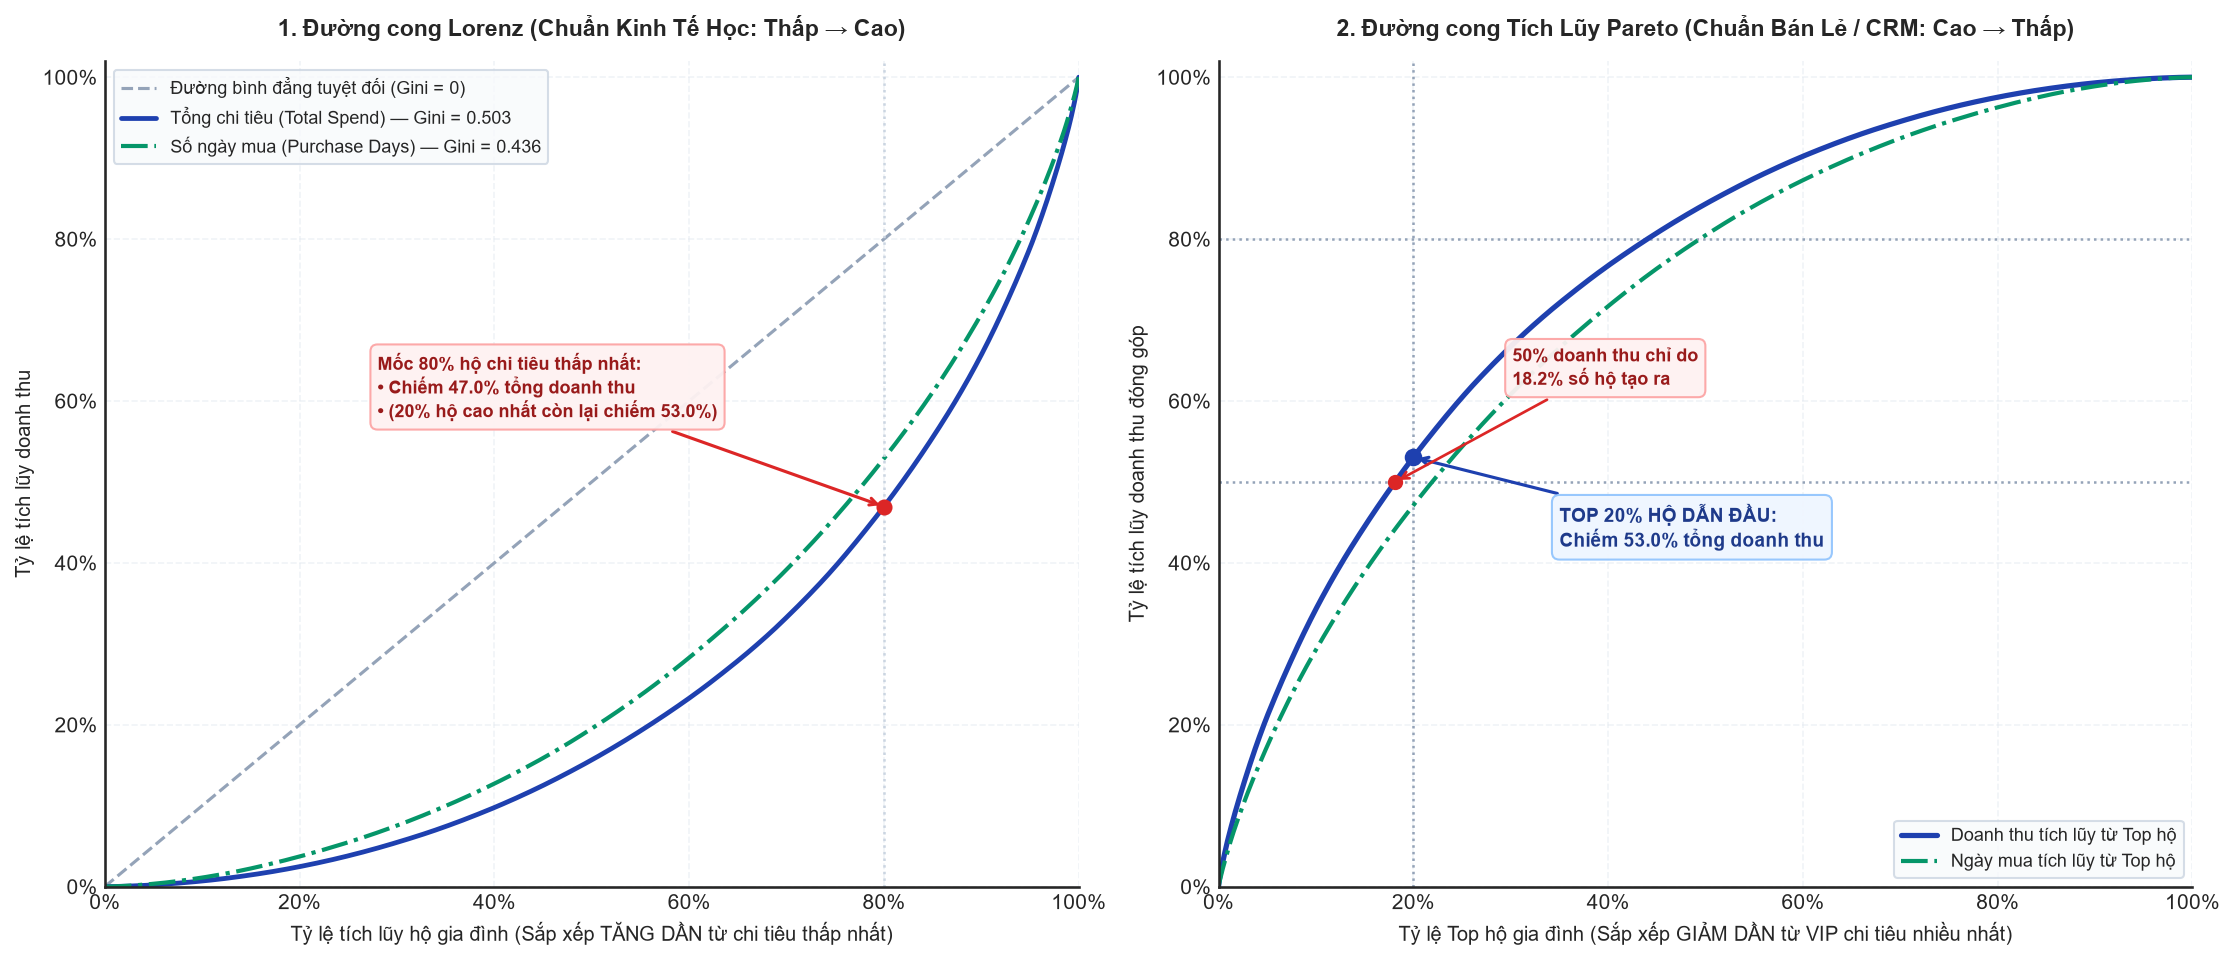

In [56]:
# Biểu đồ phân bổ mức độ tập trung doanh thu và tần suất (Lorenz & Pareto)
fig_lorenz = plot_customer_lorenz_curves(df_summary)
plt.show()


### Nhận xét & Ý nghĩa Kinh doanh

1. **Tần suất mua sắm ($F$) và Nhịp mua (IPT)**:
   - Khách hàng ghé siêu thị trung bình **khoảng 1 lần mỗi tuần** (F median 0.83 ngày/tuần).
   - Nhịp mua phổ biến nhất giữa 2 lần đi chợ là **6.0 ngày**, khẳng định chu kỳ tuần (7 ngày) là nhịp mua sắm tự nhiên của phần lớn hộ gia đình.

2. **Chi tiêu hàng tuần và mỗi lượt mua ($M$)**:
   - Chi tiêu trung bình đạt **$32.6/tuần** và **$32.1 cho mỗi lần đi chợ**, phản ánh quy mô giỏ hàng tiêu dùng thiết yếu điển hình.
   - Có sự hiện diện rõ nét của nhóm khách hàng VIP với mức chi tiêu vượt trội so với số đông.

3. **Mức độ tập trung doanh thu (Pareto 80/20)**:
   - **Top 20% hộ gia đình tạo ra 53.0% tổng doanh thu** của toàn bộ siêu thị.
   - Một nửa (50%) doanh thu toàn hệ thống chỉ do **18.2% số hộ** đóng góp, cho thấy chiến lược giữ chân khách hàng (retention) cần ưu tiên tập trung vào nhóm khách hàng nòng cốt này.


## Customer Deep Dive

In [57]:
from propensity.eda.customer_deep_dive import (
    DeepDiveThresholds,
    build_customer_deep_dive_report,
)

# Khởi tạo ngưỡng và tạo báo cáo Customer Deep Dive toàn diện
thr = DeepDiveThresholds()
report = build_customer_deep_dive_report(df_raw, thr)
print("Khởi tạo cấu trúc báo cáo Deep Dive cho 2,500 hộ gia đình: Hoàn tất.")


Khởi tạo cấu trúc báo cáo Deep Dive cho 2,500 hộ gia đình: Hoàn tất.


### Q-F: Household có F cao mua liên tục hay chỉ mua dồn trong một giai đoạn?


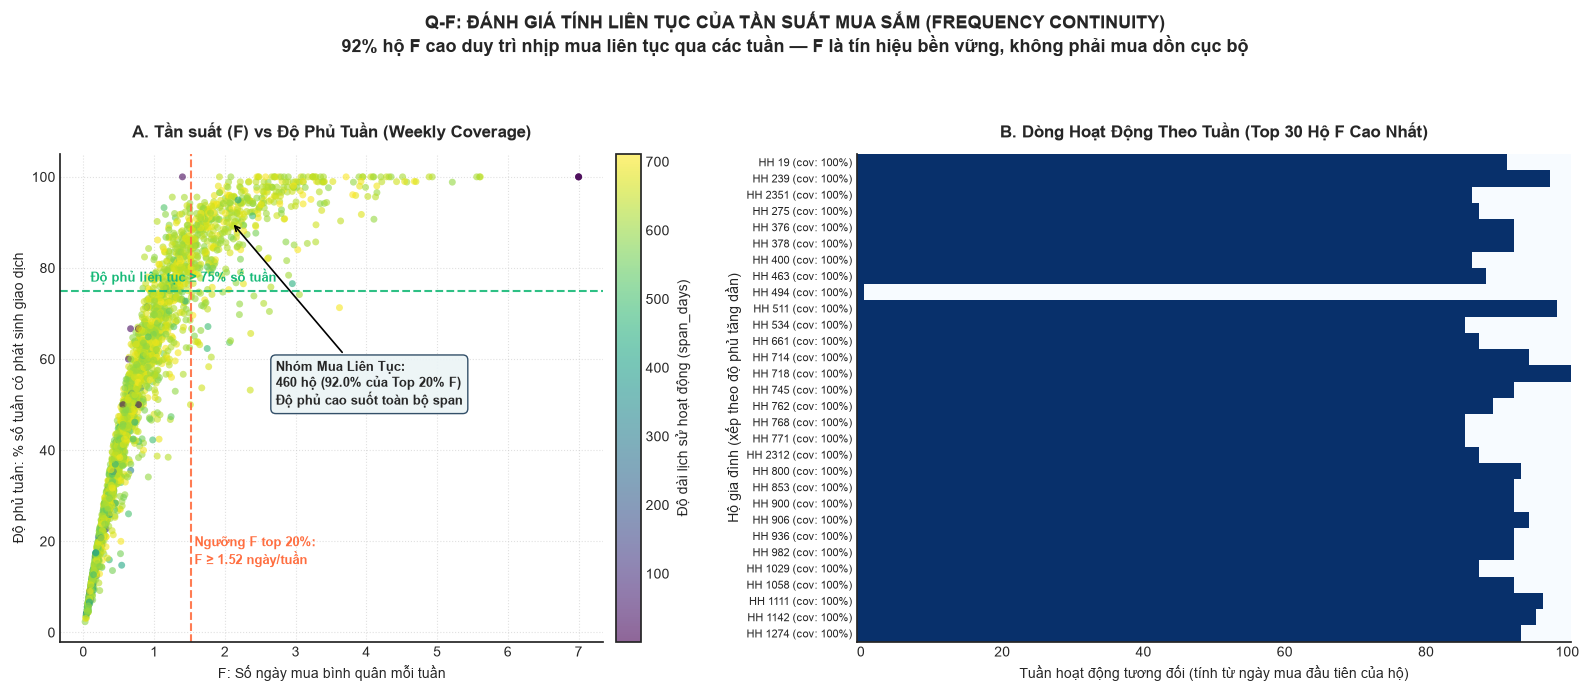

In [63]:
from propensity.eda.customer_deep_dive import activity_continuity, classify_high_f
from propensity.eda.customer_deep_dive_plots import plot_f_continuity

# Phân tích tính liên tục và phân loại mẫu hình mua sắm của nhóm F cao
fig_f = plot_f_continuity(report, top_n=30)

**Nhận xét**:
- **92.0% hộ F cao mua liên tục tuần qua tuần** (độ phủ median 89.5% số tuần, span median 700 ngày). Chỉ 0.6% là mua dồn cục bộ.
- **Feature**: $F$ rất bền vững, dùng làm feature độc lập tốt; nên kèm thêm `weekly_coverage` và cờ `short_span` để nhận diện 8% không liên tục.


### Q-CV: CV cao là do mua thất thường, do ít lần mua hay có kỳ nghỉ dài?


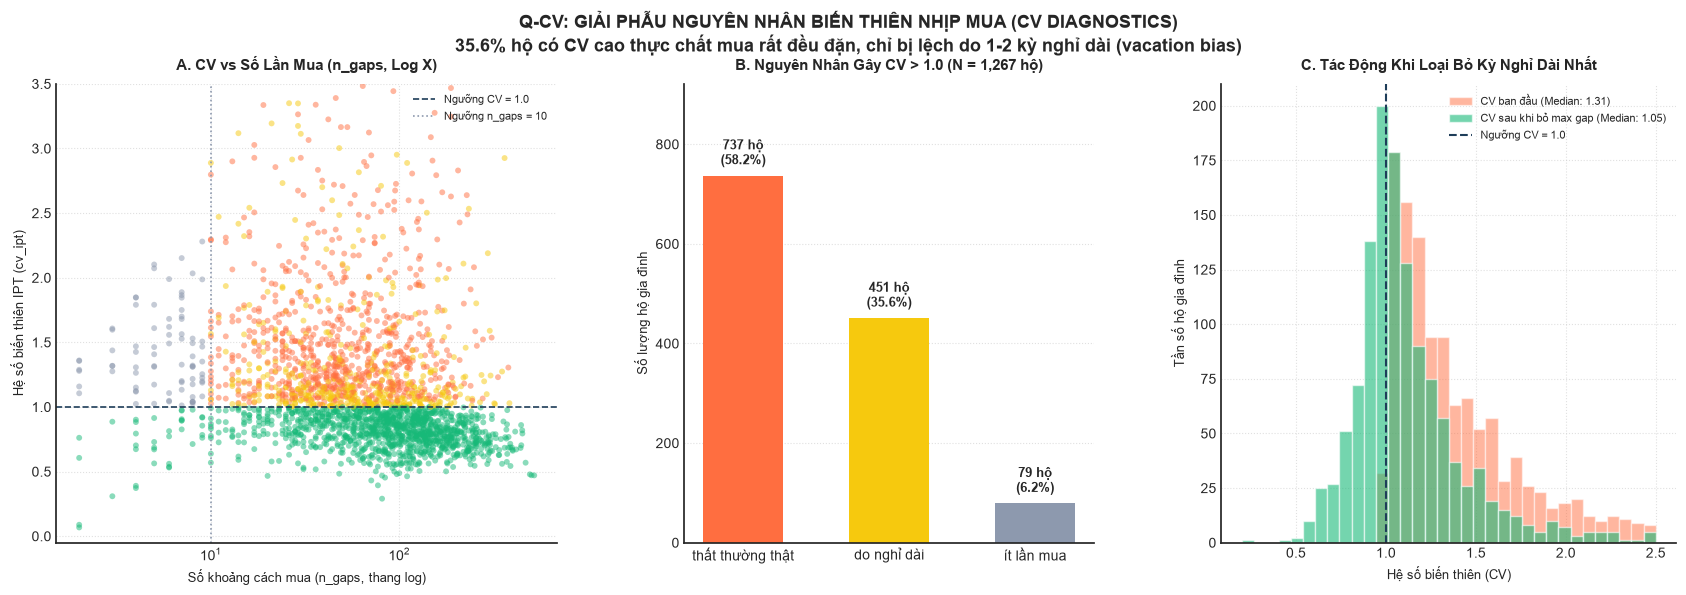

In [64]:
from propensity.eda.customer_deep_dive import cv_diagnostics
from propensity.eda.customer_deep_dive_plots import plot_cv_diagnostics

# Chẩn đoán các nguyên nhân gây CV cao và tác động khi loại bỏ max gap
fig_cv = plot_cv_diagnostics(report)

**Nhận xét**:
- **35.6% hộ có CV cao thực chất mua rất đều đặn**, chỉ bị lệch vì 1 kỳ nghỉ dài (khi bỏ kỳ nghỉ dài nhất thì nhịp mua lập tức trở về mức đều đặn 0.86). 58.2% thất thường thật, 6.2% do mới mua dưới 10 lần.
- **Feature**: Không dùng CV thô đơn độc. Dùng CV đã lọc kỳ nghỉ dài (`cv_drop_max`), cờ đánh dấu kỳ nghỉ (`has_long_break`), và chỉ tính độ đều khi khách đã mua từ 10 lần trở lên.


### Q-M: Khác biệt spend/tuần chủ yếu từ F, số trip/ngày hay spend/trip?


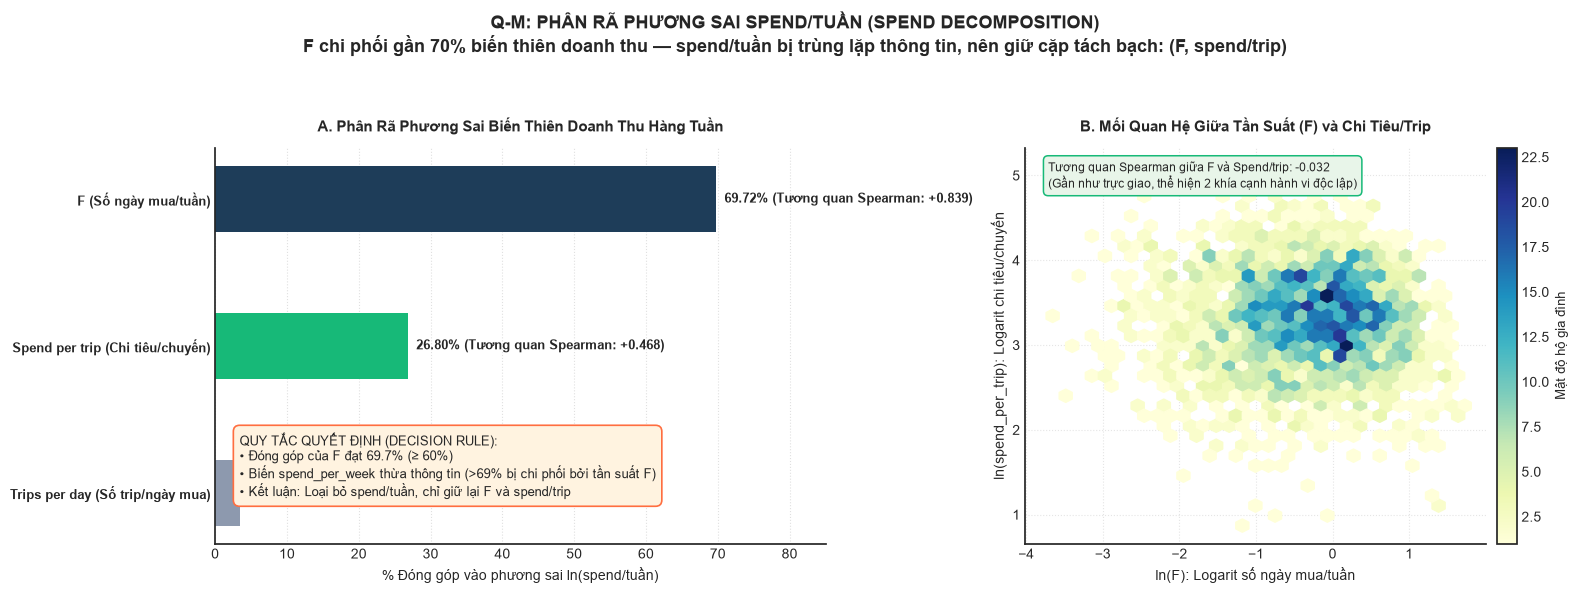

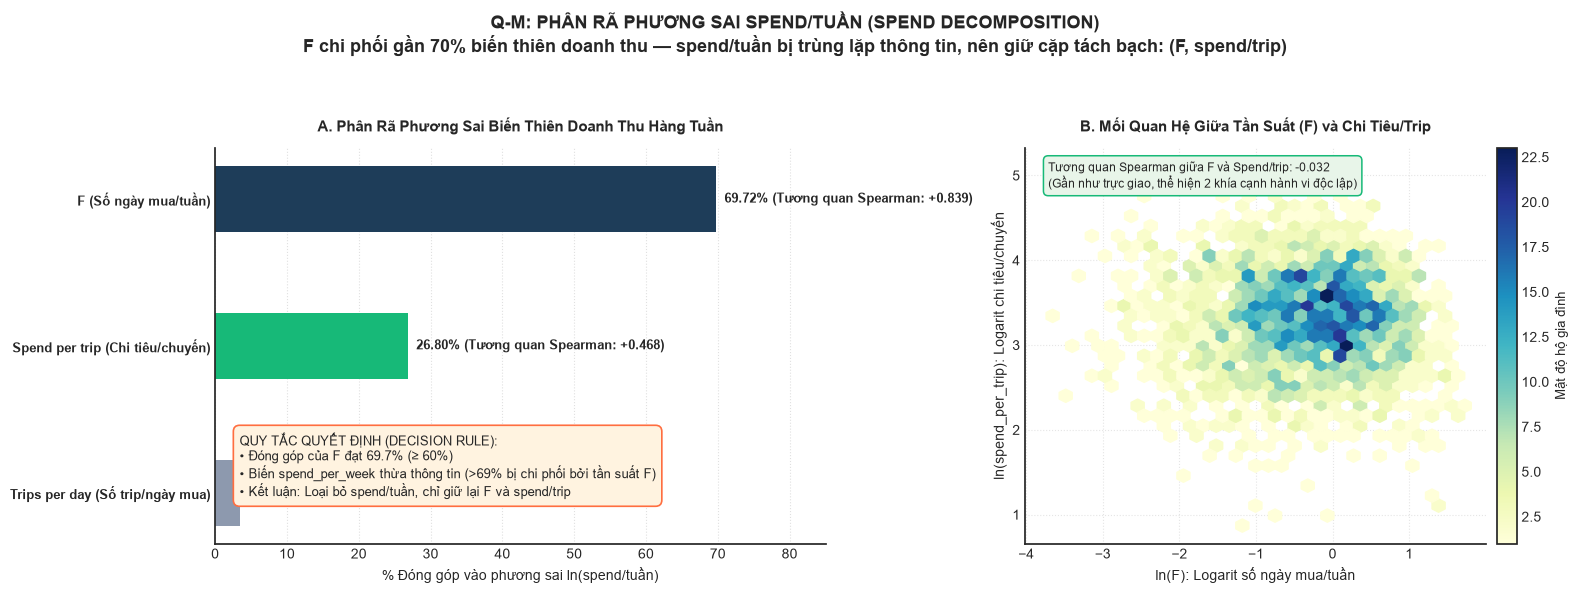

In [ ]:
from propensity.eda.customer_deep_dive import spend_decomposition
from propensity.eda.customer_deep_dive_plots import plot_spend_decomposition

# Phân rã phương sai và quy tắc quyết định feature cho biến spend
fig_m = plot_spend_decomposition(report)

**Nhận xét**:
- **Tần suất đi chợ (F) quyết định gần 70% mức chi tiêu hàng tuần**, giá trị mỗi giỏ hàng đóng góp gần 27%, còn số lần đi trong ngày chỉ chiếm hơn 3%.
- **Feature**: Chi tiêu hàng tuần bị trùng lặp thông tin với tần suất F. **Loại bỏ spend/tuần**, chỉ giữ cặp biến độc lập: **tần suất F** (nhịp đi) và **chi tiêu mỗi chuyến** (độ sâu giỏ hàng).


### Q-IPT: Household có IPT > 14 ngày thực chất mua sắm thế nào?


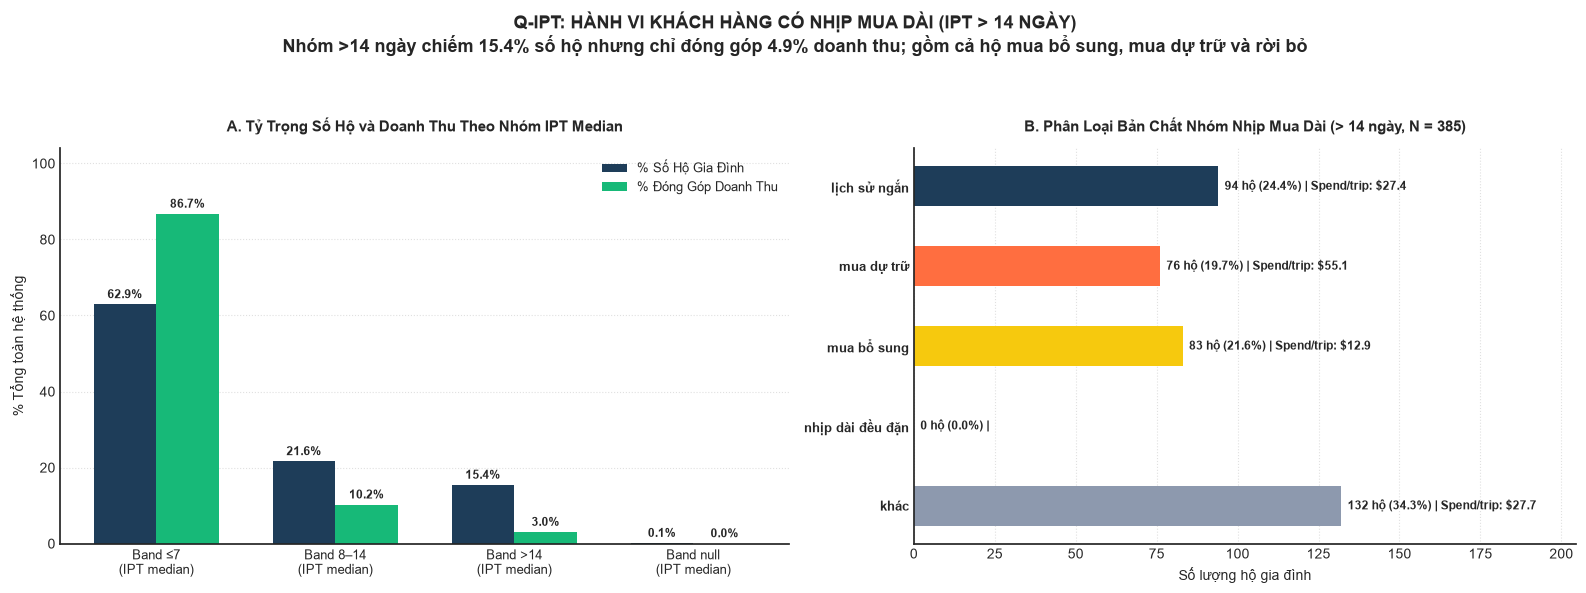

In [62]:
from propensity.eda.customer_deep_dive import long_ipt_profile
from propensity.eda.customer_deep_dive_plots import plot_ipt_band_profile

# Khảo sát các band IPT và phân loại chi tiết nhóm > 14 ngày
fig_ipt = plot_ipt_band_profile(report)

**Nhận xét**:
- **Nhóm IPT $\le 7$ ngày là trụ cột**: 62.9% số hộ nhưng mang lại 82.3% doanh thu. Nhóm IPT $> 14$ ngày chiếm 15.4% hộ nhưng chỉ 4.9% doanh thu (gồm 24% rời bỏ sớm, 22% mua bổ sung lặt vặt $\le \$18$, 20% mua dự trữ xe to $\ge \$40$).
- **Business & Label**: Nhãn 0 ở nhóm $> 14$ ngày phần lớn do nhịp sinh học tự nhiên thưa, không phải churn. Cần dùng `lapse_ratio = recency / median_ipt` để đo độ trễ tương đối.


---
## Customer vs Target (Biến – Label)

Kiểm định mối quan hệ định lượng giữa các biến đặc trưng khách hàng ($R$, $F$, $\text{Spend/trip}$, $\text{Band IPT}$) với nhãn Propensity quay lại trong 7 ngày ($H = 7$) trên panel 81 cutoffs ($DAY \in [140, 700]$), tuân thủ nghiêm ngặt kỷ luật As-of Cutoff (Zero Leakage).

> **Ghi chú cấu hình**: Phân tầng Recency hiện đang dùng 4 bin (1–7, 8–14, 15–30, 31+) để khớp với các kết quả sơ bộ đã chạy; lưới chuẩn 5 bin (1–3, 4–7, …) sẽ được cập nhật đồng bộ ở giai đoạn Feature Store toàn diện.

**Ghi chú Step 0 (Quy tắc giao dịch hợp lệ)**:
- Chuẩn hóa sang `SALES_VALUE > 0` loại bỏ 4,451 dòng quà tặng $0 và 353 giỏ hàng không phát sinh doanh thu.
- Trên toàn bộ 202,237 lượt (hộ × cutoff), chỉ có đúng 12 nhãn bị đổi trạng thái (0.0059%, < 6 phần triệu). Dữ liệu sạch triệt để mà không xáo trộn nhãn mô hình.
*(Chi tiết định lượng và kiểm định đầy đủ xem tại `docs/customer_label_relation_details.md`)*

### Q1: Lưới Cơ Sở Recency × Frequency (Baseline R × F)

**Câu hỏi**: Chỉ riêng mua gần đây (Recency) và cường độ mua sắm ($F_c$) đã giải thích việc quay lại đến đâu?

*Ghi chú: $F_c$ được tính strictly trên $DAY < c$ nên có chứa một phần recency (khác với $F$ ở phần tổng quan tính đến lần mua cuối).*

Tầng Recency,Tầng Frequency,Số dòng (n_rows),Số hộ (n_hh),Tỷ lệ quay lại,Tỷ trọng dòng,Đáng tin (≥50 hộ)
1–7,≤ 0.30,"5,789",744,30.66%,2.86%,Có
1–7,0.30–0.57,"14,062","1,071",43.18%,6.95%,Có
1–7,0.57–0.96,"22,018","1,165",60.52%,10.89%,Có
1–7,0.96–1.52,"29,489","1,057",76.48%,14.58%,Có
1–7,> 1.52,"35,969",767,91.69%,17.79%,Có
1–7,Lịch sử ngắn (<28d),118,106,61.86%,0.06%,Có
8–14,≤ 0.30,"4,207",712,27.43%,2.08%,Có
8–14,0.30–0.57,"8,175","1,014",39.12%,4.04%,Có
8–14,0.57–0.96,"8,861","1,066",56.56%,4.38%,Có
8–14,0.96–1.52,"6,669",924,68.59%,3.30%,Có


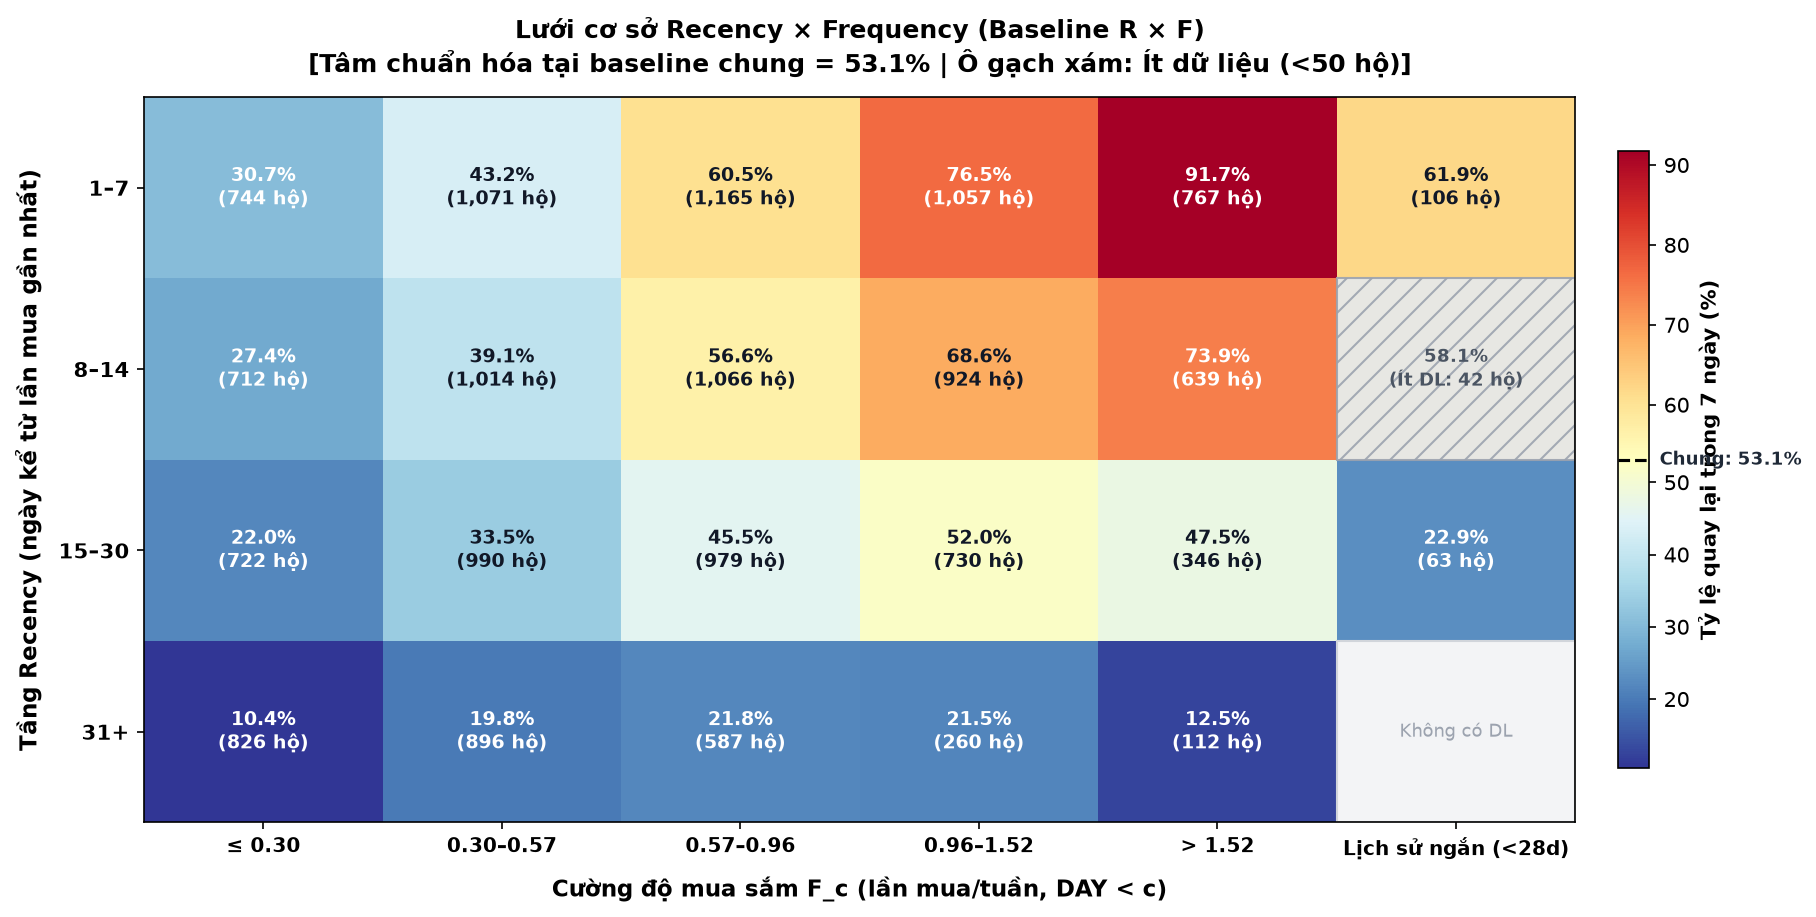

In [ ]:
# Dựng panel 81 cutoffs và tính ma trận chuẩn R x F Baseline
from propensity.eda.customer_label_relation import (
    CustomerLabelConfig,
    build_customer_cutoff_panel,
    return_rate_by_bins,
    rate_within_strata,
)
from propensity.eda.propensity_rates import (
    rf_baseline,
    excess_over_rf,
    add_verdicts,
)
from propensity.eda.label_relation_plots import (
    plot_rf_heatmap,
    plot_rate_and_excess,
)
from propensity.eda.customer_label_relation_plots import plot_f_strata

cfg = CustomerLabelConfig()
panel = build_customer_cutoff_panel(df_raw, cfg)
rf = rf_baseline(panel)
display(rf.cells)
fig_rf = plot_rf_heatmap(rf.cells, rf.overall_rate)
plt.show()
panel = rf.panel

In [ ]:
# Kiểm tra chất lượng dữ liệu (QC)
assert panel['expected_rf'].notna().all(), 'expected_rf chứa giá trị null!'
r_margin_pct = (panel['expected_source'] == 'r_margin').mean() * 100.0
print(f'Kiểm tra QC: 100% dòng có expected_rf hợp lệ | Tỷ lệ ô ít dữ liệu fallback về r_margin: {r_margin_pct:.2f}%')

Kiểm tra QC: 100% dòng có expected_rf hợp lệ | Tỷ lệ ô ít dữ liệu fallback về r_margin: 0.00%


**Nhận xét**:
- **Mô tả & Vì sao**: Ma trận $R \times F$ phân cực tỷ lệ quay lại mạnh mẽ từ **10.4%** ($R \in [31+], F \le 0.30$) lên tới **91.7%** ($R \in [1–7], F > 1.52$), tạo ra biên độ chênh lệch cực lớn **81.3 điểm %** do kết hợp giữa độ tươi mới chuyến đi và mật độ mua hàng tuần.
- **Liên quan label & Insight**: Chỉ riêng 2 chiều $R$ và $F$ đã định hình hầu như toàn bộ xác suất tiên nghiệm của khách hàng. Tất cả các ô phân tầng đều có quy mô lớn (>50 hộ), tỷ lệ fallback về `r_margin` là 0.00%.
- **Hành động**: Thiết lập ma trận này làm mốc chuẩn (Expected Baseline). Mọi câu hỏi tiếp theo (Spend, IPT, Danh mục, Khuyến mãi) đều phải đánh giá độ chênh (Excess) so với kỳ vọng $R \times F$.

*(Thẻ nhãn: Biến–label: Core Grid / Canonical Baseline)*

### Q4: Tần Suất ($F$) vs Return Rate & Phân Tầng Recency (Kiểm Định F Trá Hình)

**Câu hỏi**: Tần suất mua sắm $F$ có năng lực dự báo độc lập hay chỉ là Recency trá hình?

F_bin      n  n_pos  return_rate  ci_lower  ci_upper
0               ≤ 0.30  40403   6856     0.169690  0.166062  0.173382
1            0.30–0.57  40400  14122     0.349554  0.344919  0.354218
2            0.57–0.96  40401  21857     0.541001  0.536139  0.545856
3            0.96–1.52  40420  28939     0.715957  0.711541  0.720333
4               > 1.52  40382  35524     0.879699  0.876490  0.882836
5  Lịch sử ngắn (<28d)    231    114     0.493506  0.429669  0.557556

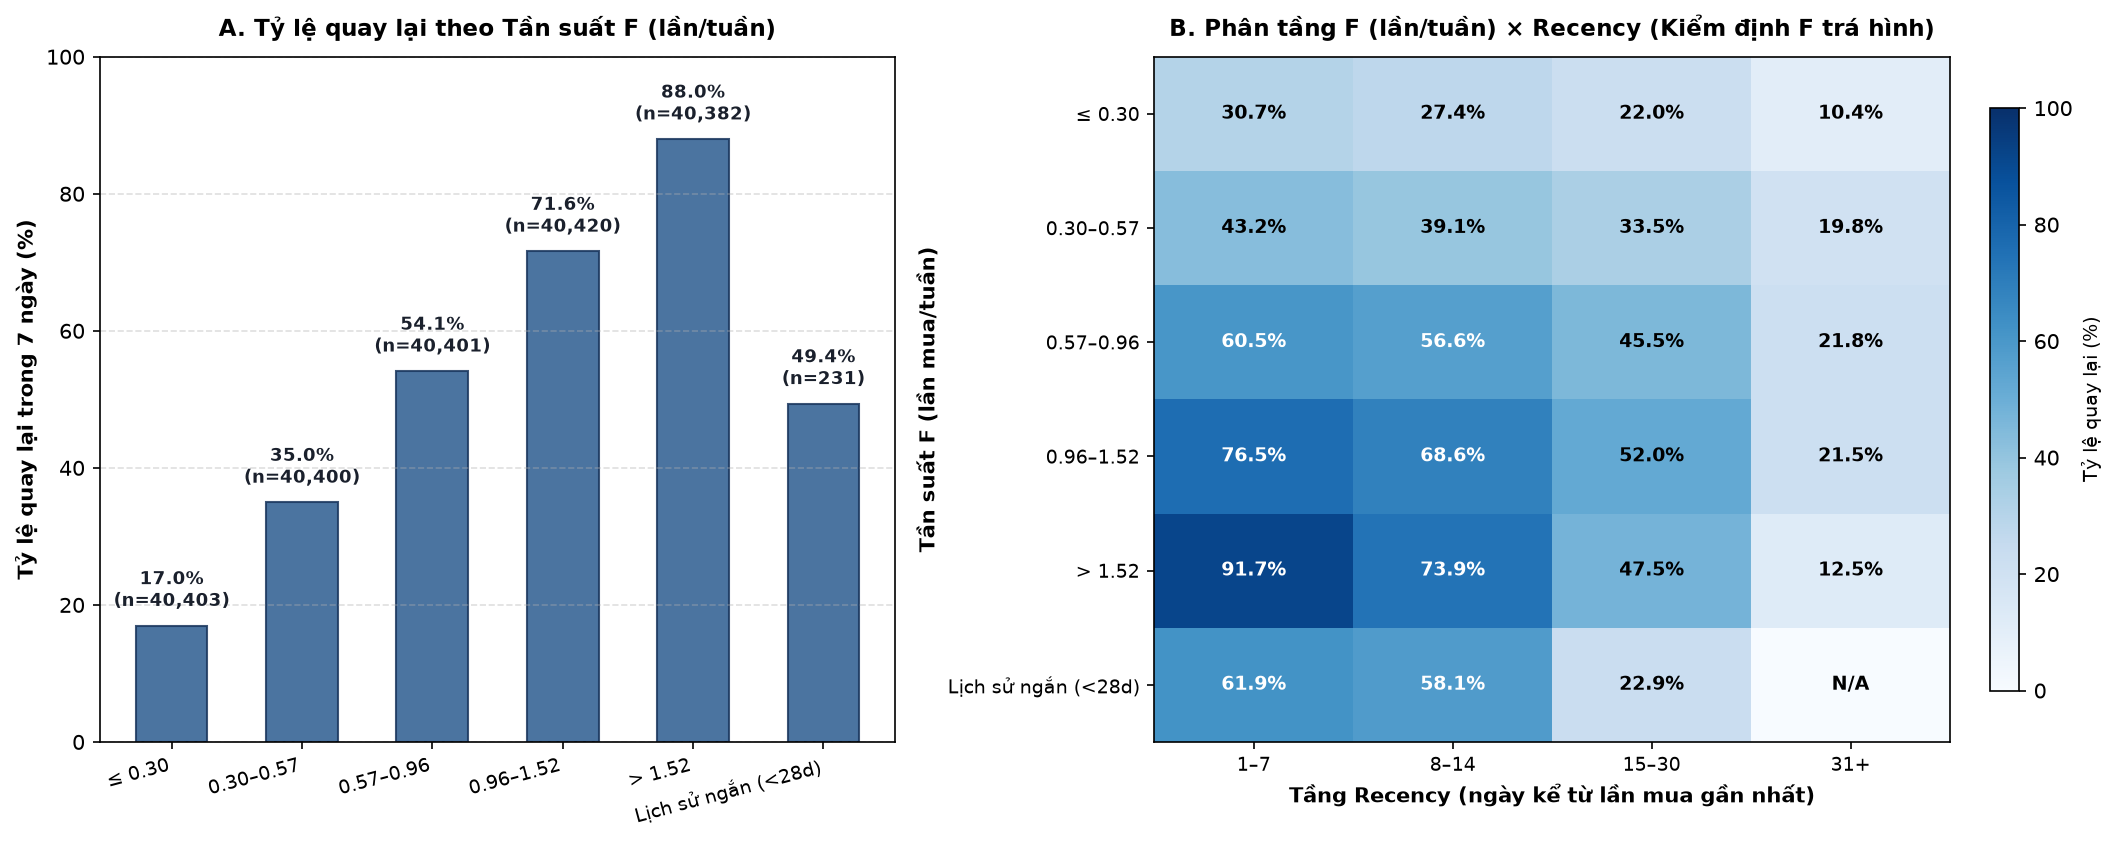

In [ ]:
q4_rates = return_rate_by_bins(panel, 'F_bin')
q4_strata = rate_within_strata(panel, 'F_bin', 'recency_bin')
fig_q4 = plot_f_strata(q4_rates, q4_strata)
plt.show()

**Nhận xét**:
- **F mang thông tin độc lập vượt trội**: Tỷ lệ quay lại tăng từ **17.0%** ($\le 0.30$ lần/tuần) lên **88.0%** ($> 1.52$ lần/tuần). Trong cùng tầng `recency 1–7 ngày`, $F$ kéo tỷ lệ từ **30.7%** lên **91.7%** (+61.0 pp); trong tầng `8–14 ngày`, $F$ tăng từ **27.4%** lên **73.9%** (+46.5 pp). Bác bỏ hoàn toàn giả thuyết $F$ là recency trá hình.
- **Business & Feature**: $F$ là feature phân tách cốt lõi bậc 1. Giữ cờ `Lịch sử ngắn (<28d)` (đạt 49.4%) để cách ly hộ mới gia nhập.

*(Thẻ nhãn: Biến–label: Core Feature 1)*

### Q5: Giá Trị Đơn Hàng (Spend/trip) Trong Cùng Tầng F (So Sánh Kỳ Vọng R × F)

**Câu hỏi**: Giá trị giỏ hàng trung bình có giúp tăng xác suất quay lại ngoài tần suất $F$ và độ tươi mới $R$ không?

Phân vị Spend/trip,Số dòng (n),Số hộ,Tỷ trọng,Tỷ lệ thực tế,Kỳ vọng (R × F),Chênh lệch R×F (pp),Chênh lệch chung (pp),Đồng nhất cutoff,Kết luận tự động
Q1,"40,448",821,20.00%,46.52%,48.61%,-2.08,-6.59,85.2%,Đã được R × F giải thích
Q2,"40,450","1,105",20.00%,54.87%,55.60%,-0.73,+1.75,64.2%,Không được ủng hộ
Q3,"40,447","1,159",20.00%,54.64%,54.65%,-0.01,+1.53,51.9%,Không được ủng hộ
Q4,"40,446","1,091",20.00%,56.57%,55.82%,+0.76,+3.46,59.3%,Đã được R × F giải thích
Q5,"40,446",819,20.00%,52.96%,50.88%,+2.07,-0.15,82.7%,Không được ủng hộ


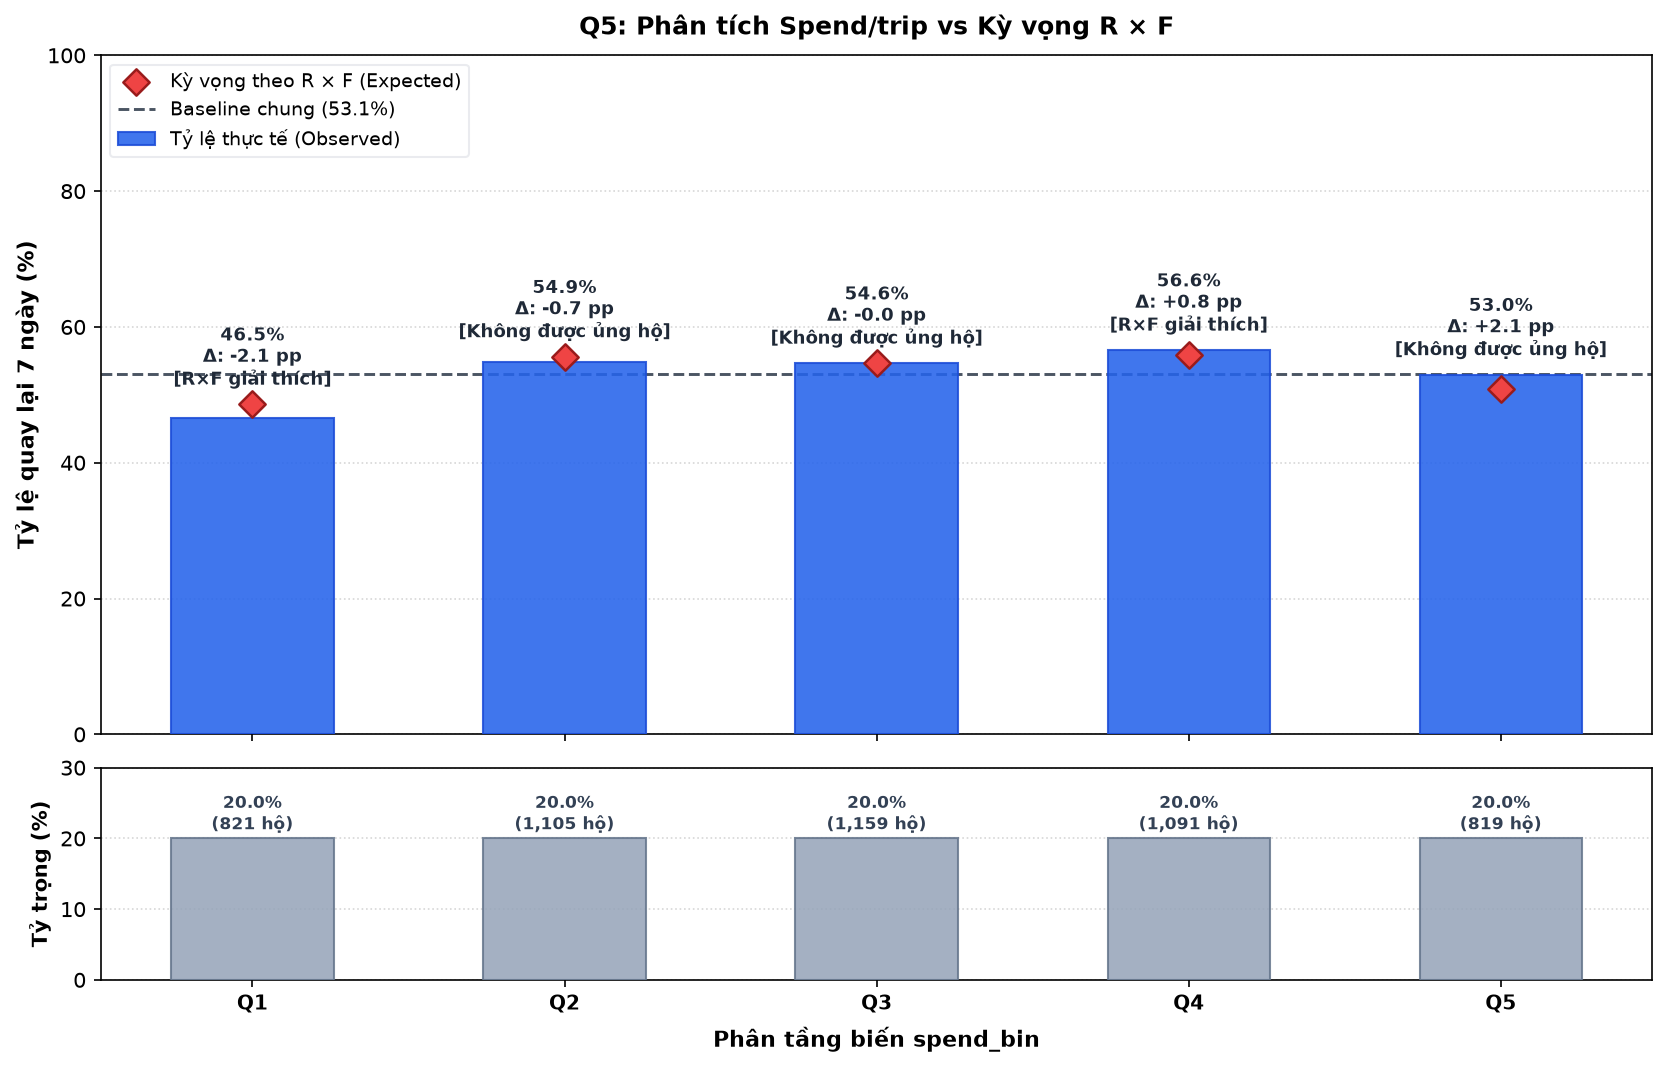

In [ ]:
# Phân tích Spend/trip so với Baseline R x F
q5_excess = add_verdicts(excess_over_rf(panel, 'spend_bin'))
display(q5_excess)
fig_q5 = plot_rate_and_excess(q5_excess, title='Q5: Phân tích Spend/trip vs Kỳ vọng R × F')
plt.show()

**Nhận xét**:
- **So với Baseline chung vs Kỳ vọng R × F**: So với baseline chung (53.1%), Spend/trip chênh lệch từ -6.59 pp (Q1) đến +3.46 pp (Q4). Tuy nhiên, khi đối chiếu với kỳ vọng ma trận $R \times F$, độ chênh lệch thuần túy chỉ dao động hẹp từ **-2.08 pp đến +2.07 pp** (biên độ 4.15 pp). Hệ thống tự động phân loại tất cả các phân vị là **[Đã được R × F giải thích]**.
- **Business & Feature**: Spend/trip phản ánh tính chất giỏ hàng (quick trip vs pantry-loading), không đóng góp nhiều năng lực dự báo vượt trội ngoài $R \times F$. Phù hợp làm feature phụ trợ (Secondary Feature) hoặc biến tương tác trong cây quyết định.

*(Thẻ nhãn: Biến–label: Secondary Feature / Interaction)*

### Q6: Nhóm Nhịp Mua Tự Nhiên (Band IPT) vs Target (So Sánh Kỳ Vọng R × F)

**Câu hỏi**: Nhóm nhịp mua tự nhiên tác động như thế nào đến tỷ lệ quay lại khi đã kiểm soát theo $R \times F$?

Nhóm Nhịp mua (IPT),Số dòng (n),Số hộ,Tỷ trọng,Tỷ lệ thực tế,Kỳ vọng (R × F),Chênh lệch R×F (pp),Chênh lệch chung (pp),Đồng nhất cutoff,Kết luận tự động
≤ 7,"122,376","1,924",60.51%,68.62%,68.05%,+0.57,+15.51,64.2%,Đã được R × F giải thích
8–14,"42,654","1,191",21.09%,38.25%,38.22%,+0.02,-14.86,50.6%,Đã được R × F giải thích
> 14,"33,877",901,16.75%,20.37%,22.04%,-1.67,-32.74,81.5%,Đã được R × F giải thích
null,"3,330",227,1.65%,6.70%,11.00%,-4.30,-46.42,81.4%,Không đủ dữ liệu


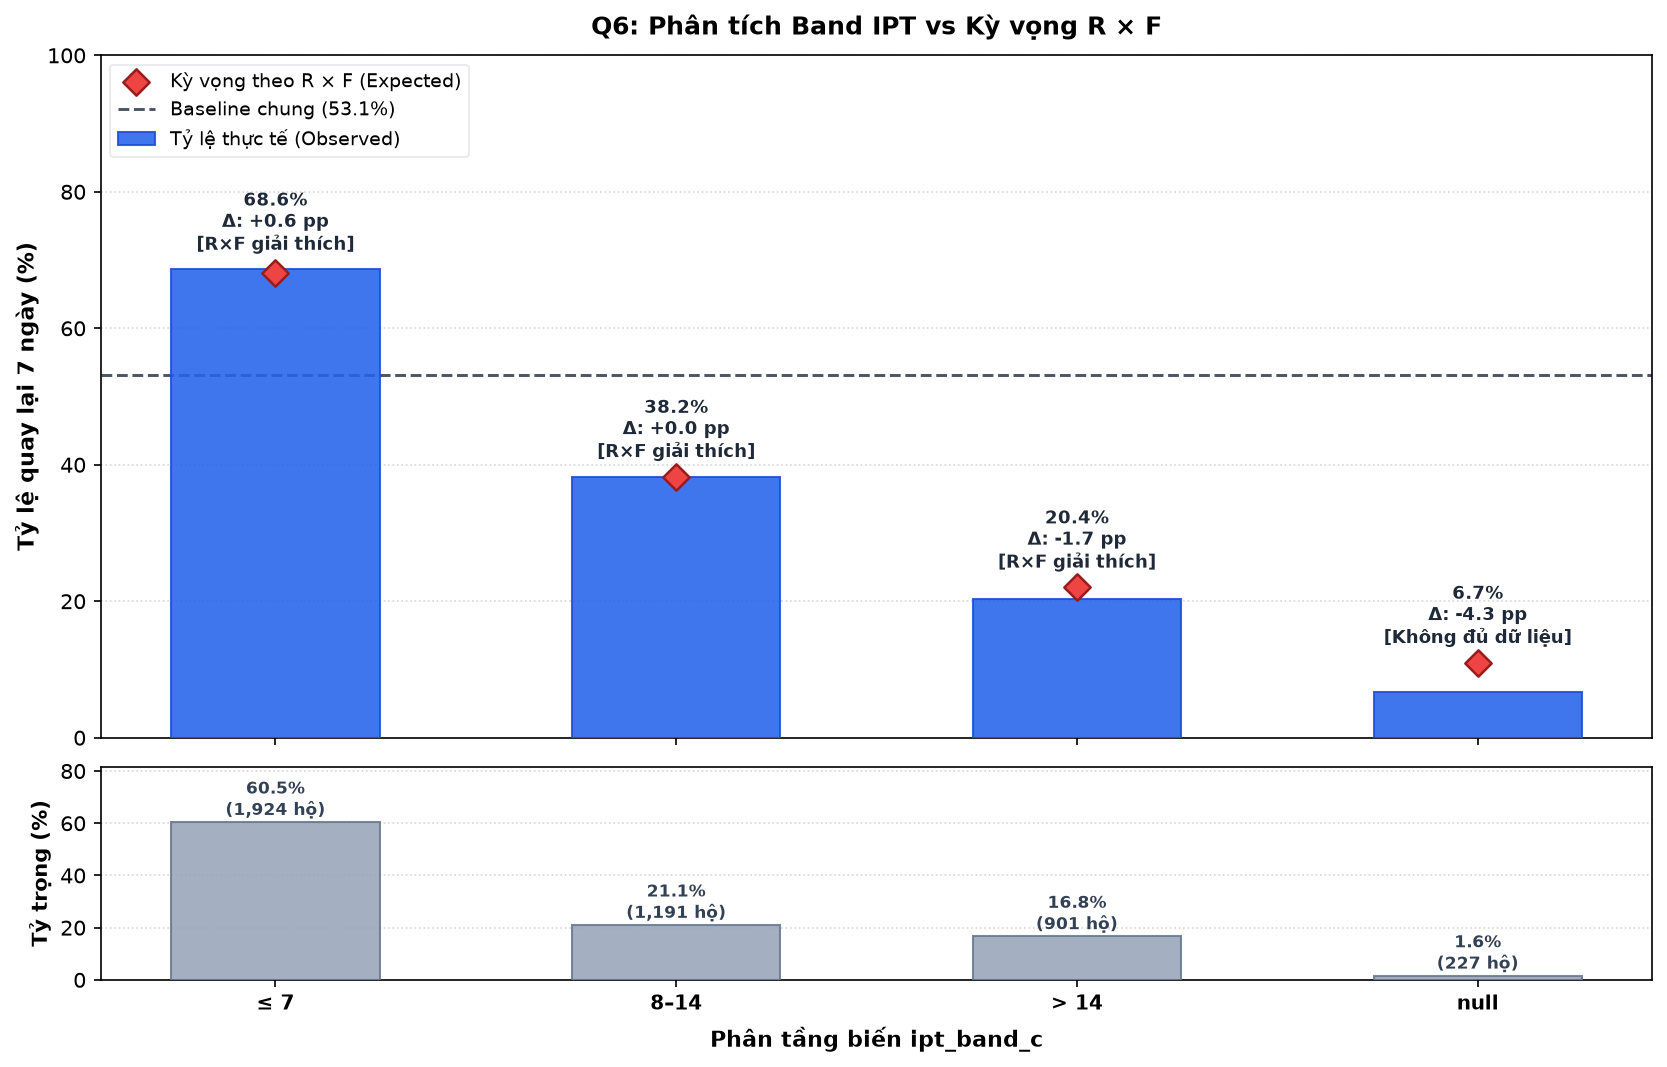

In [ ]:
# Phân tích Band IPT so với Baseline R x F
q6_excess = add_verdicts(excess_over_rf(panel, 'ipt_band_c'))
display(q6_excess)
fig_q6 = plot_rate_and_excess(q6_excess, title='Q6: Phân tích Band IPT vs Kỳ vọng R × F')
plt.show()

**Nhận xét**:
- **Band $\le 7$ ngày & Nhóm null**: Nhóm $\le 7$ ngày đạt tỷ lệ quay lại 68.62% (+15.5 pp so với chung), nhưng so với kỳ vọng $R \times F$ (68.05%) chỉ chênh lệch **+0.57 pp** $\rightarrow$ kết luận **[Đã được R × F giải thích]**. Ngược lại, nhóm `null` chênh lệch âm sâu (**-4.31 pp** so với $R \times F$) $\rightarrow$ kết luận **[Insight]** do thiếu quán tính mua sắm.
- **Business & Feature**: Nhãn 0 ở nhóm $>14$ ngày phản ánh chu kỳ mua thưa tự nhiên chứ không phải rời bỏ. Cần kết hợp `ipt_band_c` và `lapse_ratio_c = recency / median_ipt` để đo lường độ trễ tương đối theo từng nhịp mua riêng.

*(Thẻ nhãn: Biến–label: Cadence Alignment & Relative Lapse)*

---
### Bảng Đặc Tả Feature Khách Hàng (Customer Feature Specification)

| Tên Feature | Định nghĩa kỹ thuật | Kỷ luật As-of Cutoff | Xử lý Missing / Outlier | Vai trò trong Model |
| :--- | :--- | :--- | :--- | :--- |
| `recency_days` | $c - \max(DAY < c)$ | Chỉ tính trên $DAY < c$ | Luôn có giá trị | **Model Feature (Core)**: Độ tươi mới tuyệt đối |
| `recency_bin` | Bins: $[1–7], [8–14], [15–30], [31+]$ | Chỉ tính trên $DAY < c$ | Nhóm $31+$ gom đuôi dài | **Segmenter / Baseline Grid**: Trục phân tầng chuẩn |
| `tenure_days` | $c - \min(DAY)$ | $c - \text{first\_day}$ | Luôn $\ge 1$ ngày | **Control Variable**: Tuổi thọ tài khoản |
| `F_c` | $N_{\text{pdays}} / (\text{tenure} / 7.0)$ | Chỉ tính trên $DAY < c$ | Cờ `is_short_history` khi tenure $< 28$d | **Model Feature (Core 1)**: Nhịp độ mua hàng tuần |
| `F_bin` | $\le 0.30$, $0.30–0.57$, $0.57–0.96$, $0.96–1.52$, $> 1.52$ | Chỉ tính trên $DAY < c$ | Tách nhóm `<28d` | **Model Feature / Interaction**: Trục phân tầng $R \times F$ |
| `spend_per_trip` | $\sum \text{SALES\_VALUE} / N_{\text{trips}}$ | Chỉ tính trên $DAY < c$ | $N_{\text{trips}} \ge 1$ | **Secondary Feature**: Bổ trợ phi tuyến tính / tương tác |
| `spend_bin` | 5 phân vị giỏ hàng: Q1 → Q5 | Chỉ tính trên $DAY < c$ | Làm tròn tự nhiên | **Assortment / Mission Feature**: Nhận diện giỏ hàng lớn |
| `median_ipt` | $\text{median}(\text{diff}(DAY))$ | Chỉ tính trên $DAY < c$ | Gán NaN nếu $N_{\text{pdays}} < 2$ | **Cadence Feature**: Nhịp sinh học chu kỳ tự nhiên |
| `ipt_band_c` | $\le 7$, $8–14$, $> 14$, `null` | Chỉ tính trên $DAY < c$ | Nhóm `null` cho hộ mới | **Model Feature (Cadence Alignment)**: Xác suất tiên nghiệm |
| `lapse_ratio_c` | $\text{recency} / \text{median\_ipt}$ | Chỉ tính trên $DAY < c$ | Gán NaN nếu $N_{\text{pdays}} < 2$ | **Model Feature (Advanced)**: Đo độ trễ tương đối theo nhịp riêng |

*(Toàn bộ lý giải 5 bước và các bảng kiểm định chi tiết xem tại `docs/customer_label_relation_details.md`)*

## Phần 2: Category (Q2 Overview, Q3 Category × Label)

Sau khi kiểm soát Recency × Frequency (mô hình chuẩn xác định xác suất kỳ vọng $R \times F$), câu hỏi phân tích cốt lõi là: **Danh mục hàng hóa và ngành hàng khách hàng mua có cung cấp thêm tín hiệu phân biệt người quay lại hay không?**

Ta tiến hành:
1. **Q2 (Mô tả hành vi):** Phân tích tỷ trọng ngành hàng (Pareto) và nhận diện nhóm mặt hàng thiết yếu (Staple goods) trên cửa sổ hiệu chuẩn trước cutoff ($DAY \le 139$).
2. **Q3 (Liên quan nhãn & kiểm soát $R \times F$):** Đo lường hiệu ứng thặng dư (Excess over $R \times F$) của hàng thiết yếu (Q3a), độ đa dạng giỏ hàng (Q3b), nhãn hàng riêng (Q3c), hành vi đổ xăng (Q3d), và cờ ngành hàng đã mua (Q3e).


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import HTML, display
from propensity.features.category import (
    CategoryConfig,
    merch_lines,
    excluded_department_summary,
    department_summary,
    commodity_stats,
    define_staples,
    select_flag_departments,
    household_day_category,
    category_features,
    department_flags,
    evaluate_department_flags_excess,
)
from propensity.eda.category_plots import (
    plot_department_pareto,
    plot_commodity_scatter,
    plot_department_excess,
)
from propensity.eda.label_relation_plots import plot_rate_and_excess
from propensity.eda.propensity_rates import (
    join_features,
    excess_over_rf,
    add_verdicts,
    quantile_bin,
)

raw_dir = Path("../data/raw/Dunnhumby")
prod = pd.read_csv(raw_dir / "product.csv")
cfg = CategoryConfig()

lines = merch_lines(df_raw, prod, cfg)
non_merch = excluded_department_summary(lines)
display(HTML("<h4>Bảng Tổng Hợp Các Ngành Hàng Phi Hàng Hóa (Non-Merchandise Excluded)</h4>"))
display(non_merch)


Đã nạp danh mục sản phẩm và gắn cờ phân loại hàng hóa hợp lệ.


Ngành hàng loại trừ,Tổng chi tiêu ($),Tỷ trọng doanh số,Số hộ mua,household_share,Median Quantity,Top Commodities
KIOSK-GAS,544222.28,0.067543,1371,0.5484,10005.0,"COUPON/MISC ITEMS, FUEL"
MISC SALES TRAN,119960.04,0.014888,1373,0.5492,3.0,COUPON/MISC ITEMS
MISC. TRANS.,10678.69,0.001325,919,0.3676,1.0,NO COMMODITY DESCRIPTION
COUP/STR & MFG,1027.72,0.000128,235,0.0940,1.0,COUPONS/STORE & MFG


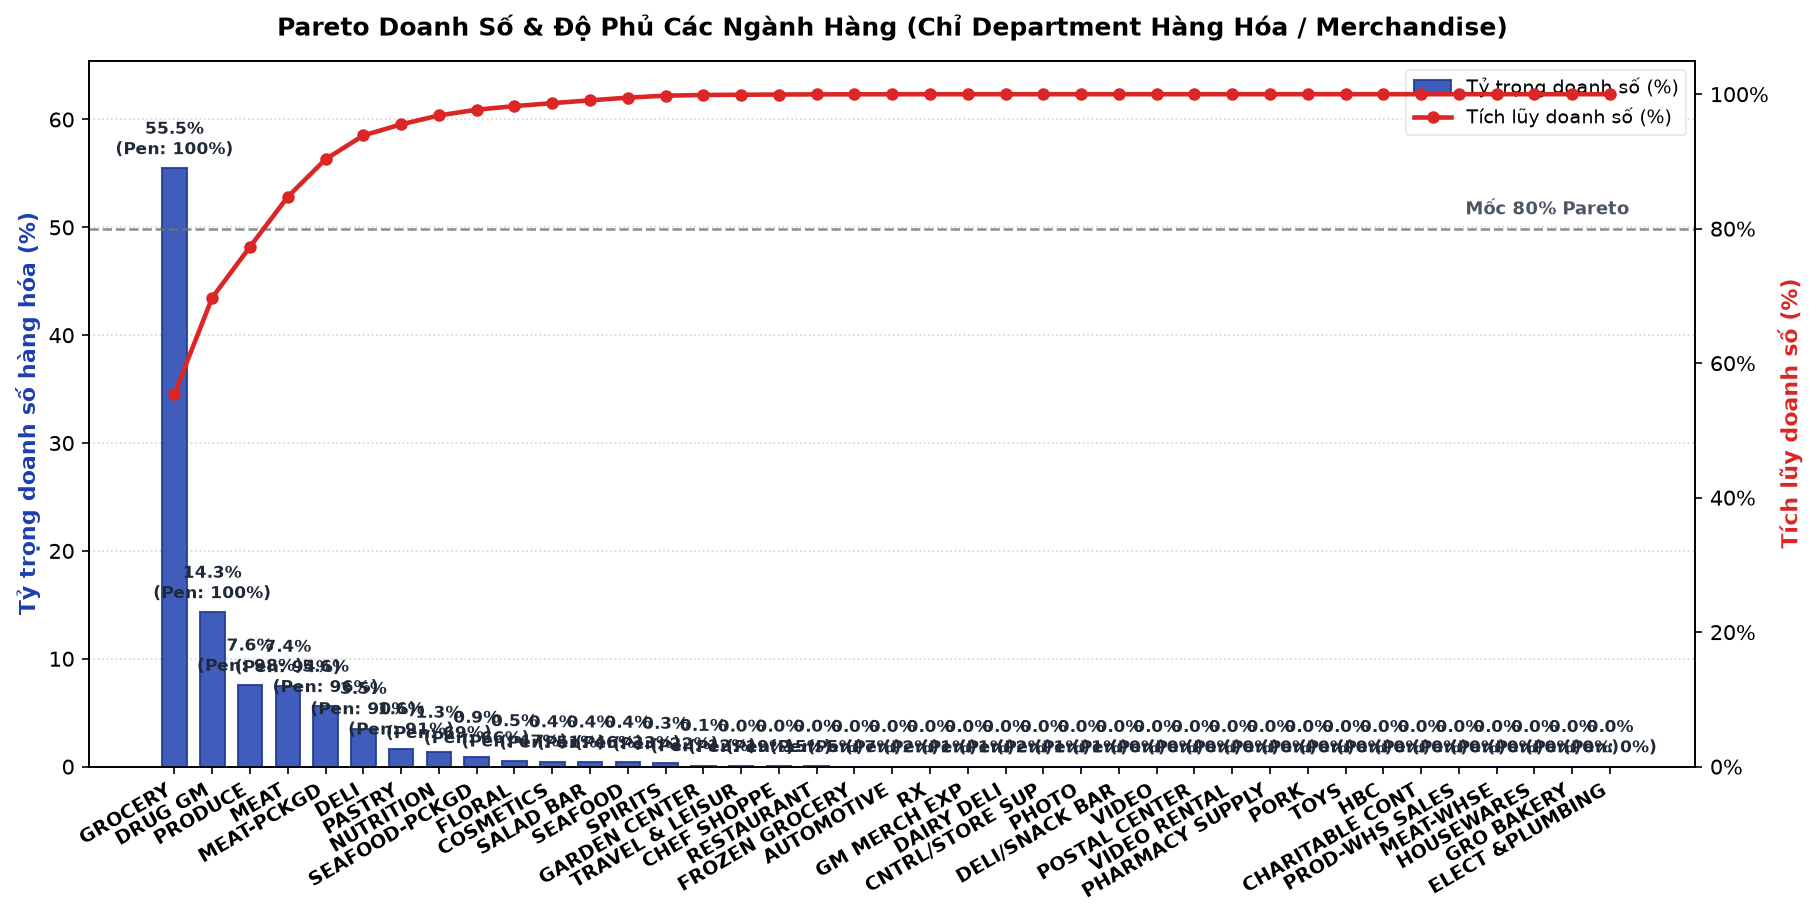

In [ ]:
dept_sum = department_summary(lines)
fig_q2a = plot_department_pareto(dept_sum)
fig_q2a


### Phân Tích Q2a: Cấu Trúc Ngành Hàng & Phân Bổ Doanh Số (Department Pareto)

- **Mô tả:** Doanh số hàng hóa tập trung cao độ theo quy luật Pareto: ngành hàng `GROCERY` chiếm tới **55.46%** tổng chi tiêu và đạt độ thâm nhập **98.59%** số hộ. Top 4 ngành hàng (`GROCERY`, `DRUG GM`, `PRODUCE`, `MEAT`) chiếm **84.74%** doanh số và top 5 ngành hàng (`+ MEAT-PCKGD`) chiếm **90.33%**.
- **Vì sao:** Đây là đặc thù mô hình siêu thị tổng hợp phục vụ nhu cầu ăn uống hàng ngày, nơi thực phẩm khô và hàng tiêu dùng nhanh (FMCG) đóng vai trò doanh số cốt lõi.
- **Liên quan label:** Chưa so sánh trực tiếp với nhãn quay lại; đóng vai trò phân tầng giỏ hàng.
- **Insight:** Vì `GROCERY` có độ thâm nhập gần như tuyệt đối (~99%), biến cờ nhị phân "từng mua GROCERY" hoàn toàn mất tính biến thiên và không có giá trị phân loại. Để phân biệt khách hàng, cần đào sâu vào cấp độ Commodity hoặc các ngành hàng cấp 2 có độ thâm nhập chọn lọc.
- **Hành động:** Loại trừ `GROCERY` khỏi tập cờ nhị phân ngành hàng ở Q3e (chỉ giữ các ngành hàng có độ thâm nhập giai đoạn sớm trong ngưỡng $20\% - 90\%$).

> [!NOTE]
> **Card Biến–Label (Q2a):** `dept_spend_share` | Vai trò: Phân tích cơ cấu giỏ hàng (Basket Profiling) | Khuyến nghị: Không dùng biến cờ `has_grocery` làm feature độc lập.


Tổng số commodity khảo sát trên DAY <= 139: 292
Số mặt hàng đạt chuẩn thiết yếu (Staples): 5
Số candidate bị loại do không thỏa ngưỡng: 287


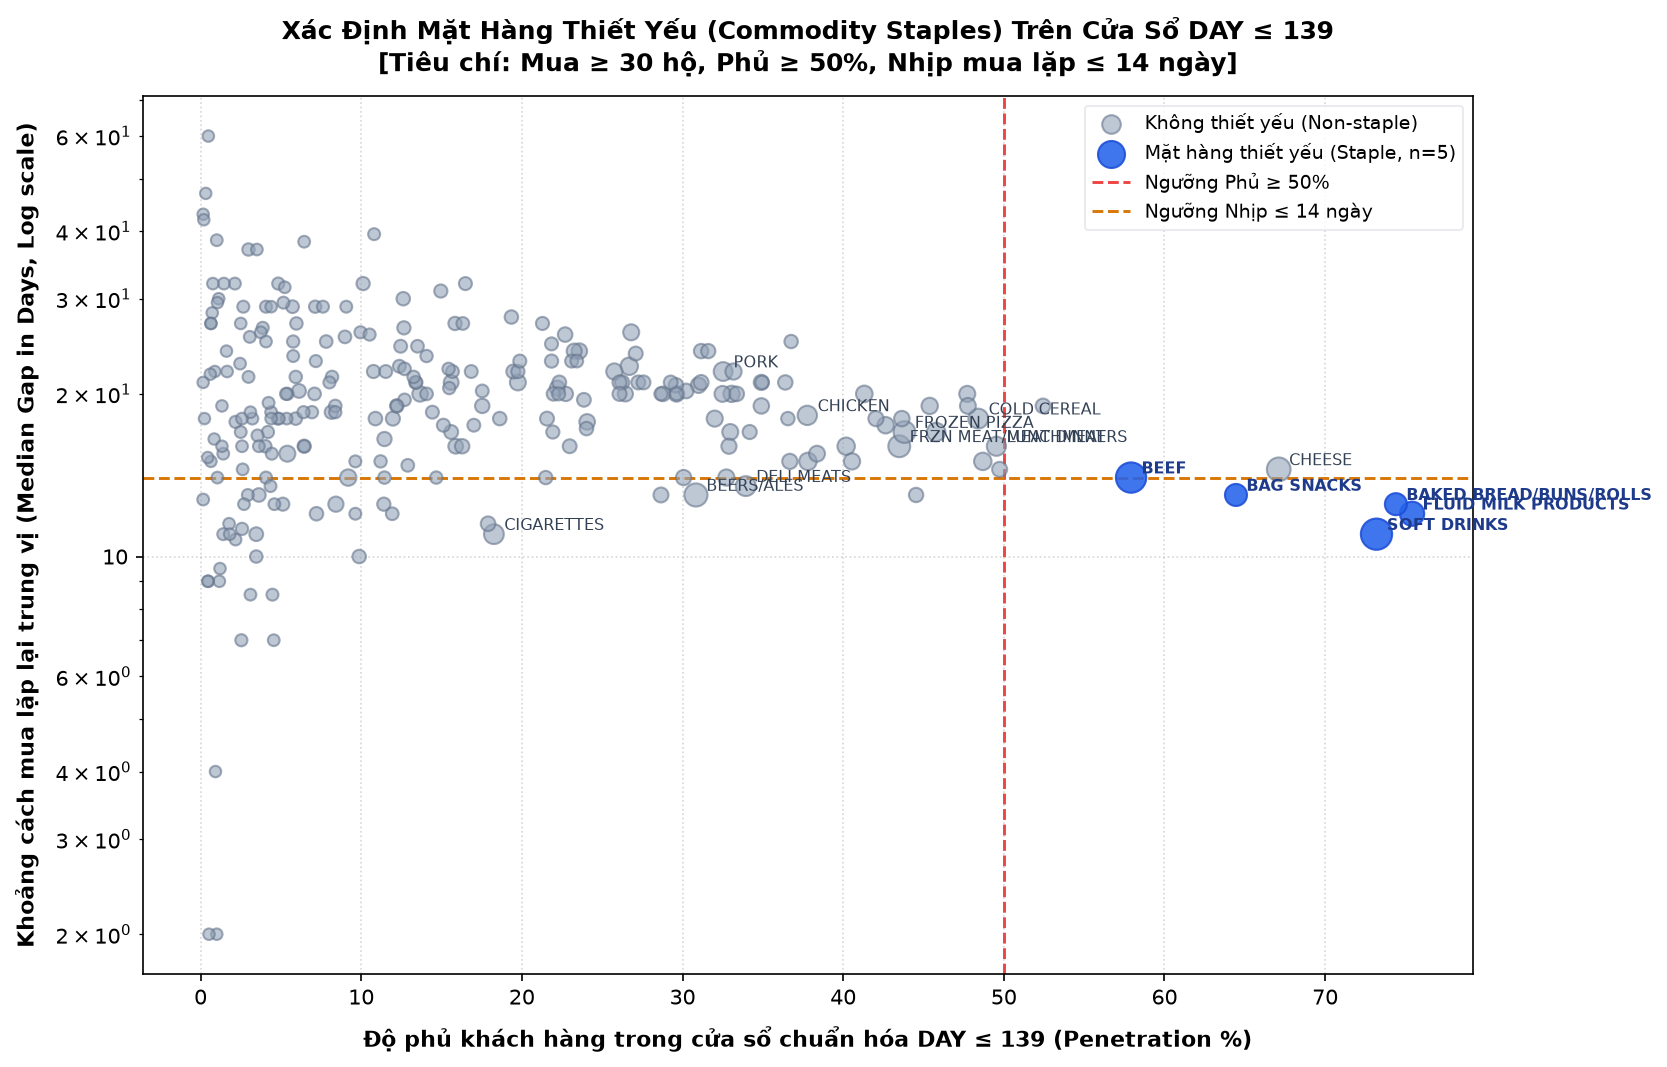

Commodity thiết yếu,Ngành hàng,Độ phủ (Penetration),Tỷ lệ mua lặp lại,Chu kỳ mua (Median Gap),Tỷ trọng chi tiêu
SOFT DRINKS,GROCERY,0.731963,0.724670,11.0,0.048710
BEEF,MEAT,0.579202,0.626305,14.0,0.045473
FLUID MILK PRODUCTS,GROCERY,0.754131,0.715126,12.0,0.026205
BAKED BREAD/BUNS/ROLLS,GROCERY,0.744055,0.716685,12.5,0.020481
BAG SNACKS,GROCERY,0.644498,0.622264,13.0,0.020439


In [ ]:
stats = commodity_stats(lines, cfg)
staple_df = define_staples(stats, cfg)
staple_set = set(staple_df.loc[staple_df["is_staple"], "commodity"])

print(f"Tổng số commodity khảo sát trên DAY <= 139: {len(stats):,}")
print(f"Số mặt hàng đạt chuẩn thiết yếu (Staples): {len(staple_set)}")
print(f"Số candidate bị loại do không thỏa ngưỡng: {len(stats) - len(staple_set):,}")

fig_q2b = plot_commodity_scatter(staple_df, cfg)
fig_q2b


### Phân Tích Q2b: Nhận Diện Mặt Hàng Thiết Yếu (Commodity Staples)

- **Mô tả:** Trên cửa sổ hiệu chuẩn trước cutoff $DAY \le 139$ (tránh rò rỉ thông tin tương lai) với tiêu chí độ phủ $\ge 50\%$ và chu kỳ mua trung vị $\le 14$ ngày, đã xác định được đúng **5 mặt hàng thiết yếu (Staples)** khớp chính xác với bảng kết xuất:
  1. `FLUID MILK PRODUCTS` (Độ phủ **75.4%**, tỷ lệ mua lặp lại **71.5%**, chu kỳ mua trung vị **12.0 ngày**, chiếm 2.6% chi tiêu hàng hóa).
  2. `BAKED BREAD/BUNS/ROLLS` (Độ phủ **74.4%**, tỷ lệ mua lặp lại **71.7%**, chu kỳ mua trung vị **12.5 ngày**, chiếm 2.0% chi tiêu hàng hóa).
  3. `SOFT DRINKS` (Độ phủ **73.2%**, tỷ lệ mua lặp lại **72.5%**, chu kỳ mua trung vị **11.0 ngày**, chiếm 4.9% chi tiêu hàng hóa).
  4. `BAG SNACKS` (Độ phủ **64.4%**, tỷ lệ mua lặp lại **62.2%**, chu kỳ mua trung vị **13.0 ngày**, chiếm 2.0% chi tiêu hàng hóa).
  5. `BEEF` (Độ phủ **57.9%**, tỷ lệ mua lặp lại **62.6%**, chu kỳ mua trung vị **14.0 ngày**, chiếm 4.5% chi tiêu hàng hóa).
- **Vì sao:** Đây là các mặt hàng nhu yếu phẩm hàng ngày có chu kỳ tiêu dùng tự nhiên ngắn dưới 2 tuần.
- **Liên quan label:** Dẫn sang câu hỏi Q3a: Liệu hộ dồn tỷ trọng chi tiêu vào các mặt hàng này có xác suất quay lại cao hơn sau khi đã kiểm soát $R \times F$?
- **Insight:** 5 mặt hàng này đóng vai trò mỏ neo giữ chân khách viếng thăm thường xuyên.
- **Hành động:** Sử dụng tập `staple_set` này để tính tỷ trọng chi tiêu `staple_spend_share_c` tại từng cutoff cho Q3a. Không đưa biến cờ danh mục vào làm feature chính độc lập của mô hình.


In [ ]:
flag_departments = select_flag_departments(dept_sum, cfg)
hdc = household_day_category(lines, staple_set)

cat_feats = category_features(hdc, cutoffs)
dept_fl = department_flags(hdc, cutoffs, flag_departments)

panel = join_features(panel, cat_feats, dept_fl)
print(f"Hoàn thành tính toán feature point-in-time! Kích thước panel sau join: {panel.shape}")
print(f"Xác nhận bảo toàn số dòng panel gốc: {len(panel):,} dòng (không mất dòng hay sinh bản ghi rỗng).")


Hoàn thành tính toán feature point-in-time! Kích thước panel sau join: (202237, 42)
Xác nhận bảo toàn số dòng panel gốc: 202,237 dòng (không mất dòng hay sinh bản ghi rỗng).


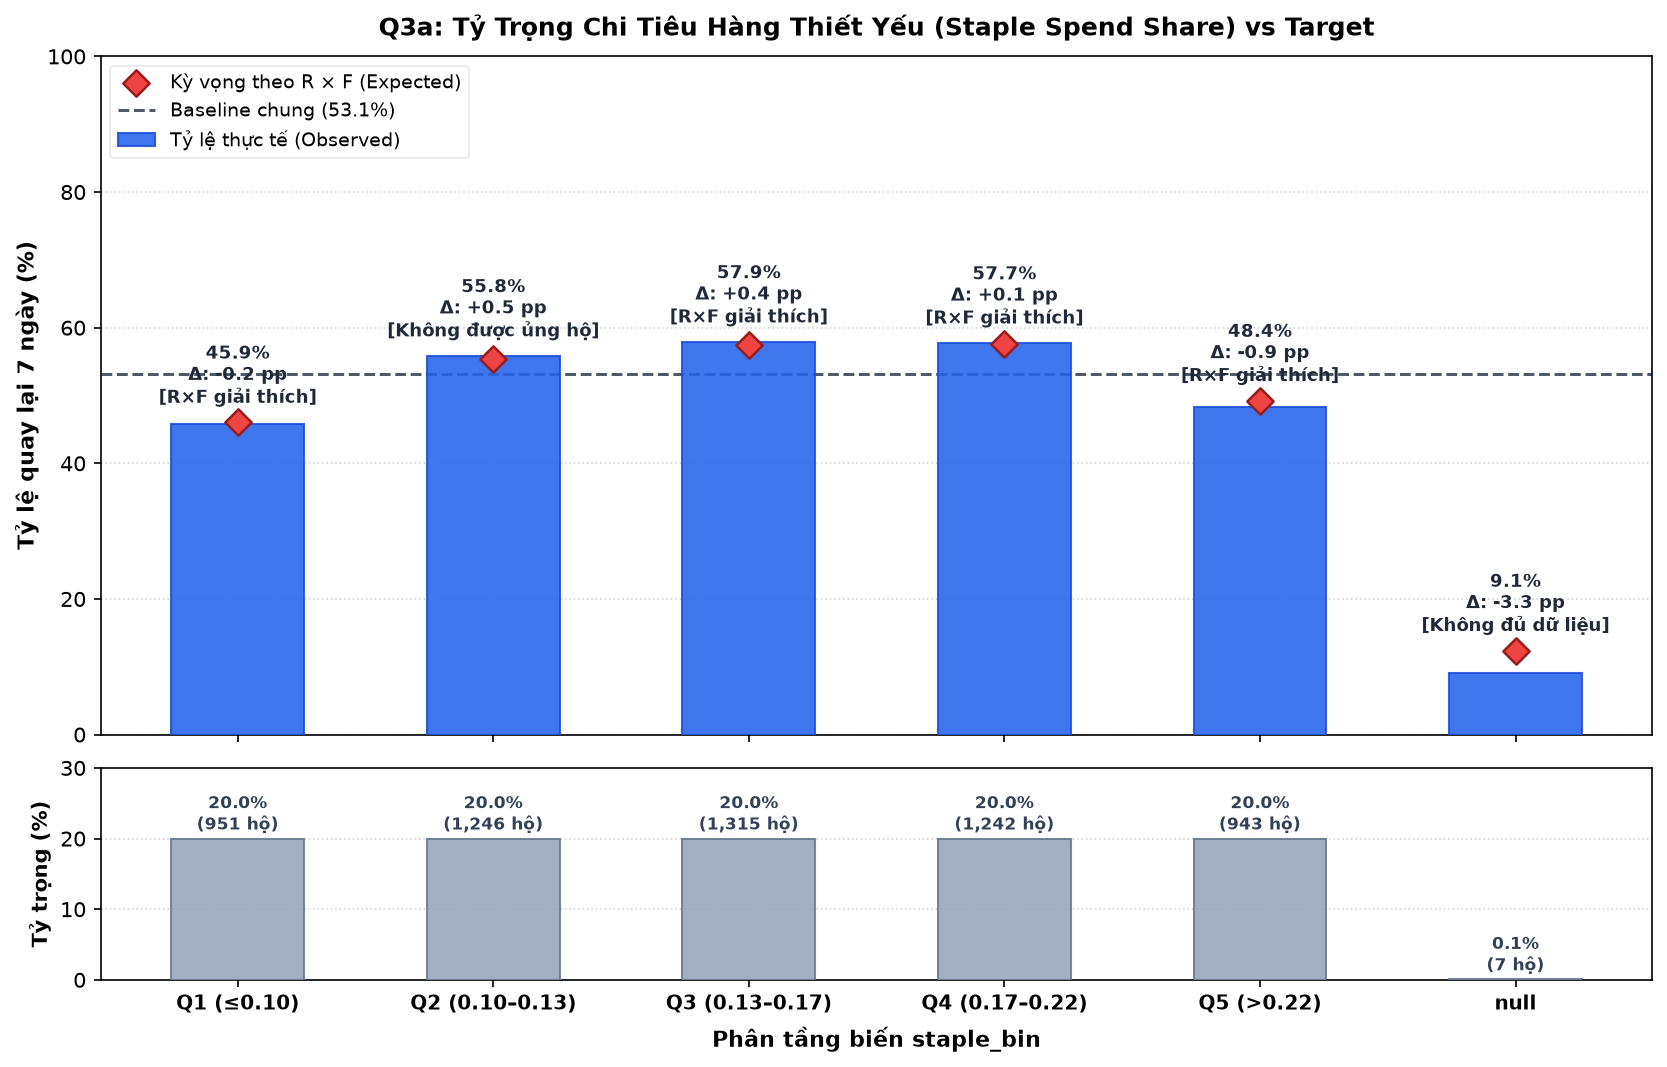

Tầng tỷ trọng thiết yếu,Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Q1 (≤0.10),40424,951,0.199884,0.458688,0.460313,-0.162468,0.518519,Đã được R × F giải thích
Q2 (0.10–0.13),40423,1246,0.199879,0.558345,0.553410,0.493580,0.580247,Không được ủng hộ
Q3 (0.13–0.17),40423,1315,0.199879,0.578878,0.574452,0.442642,0.592593,Đã được R × F giải thích
Q4 (0.17–0.22),40427,1242,0.199899,0.577238,0.576182,0.105592,0.481481,Đã được R × F giải thích
Q5 (>0.22),40419,943,0.199860,0.483758,0.492389,-0.863121,0.679012,Đã được R × F giải thích
null,121,7,0.000598,0.090909,0.123819,-3.291020,0.000000,Không đủ dữ liệu


In [ ]:
panel["staple_bin"] = quantile_bin(panel["staple_spend_share_c"], 5, prefix="Q")
q3a_excess = add_verdicts(excess_over_rf(panel, "staple_bin"))

fig_q3a = plot_rate_and_excess(q3a_excess, title="Q3a: Tỷ Trọng Chi Tiêu Hàng Thiết Yếu (Staple Spend Share) vs Target")
fig_q3a


### Phân Tích Q3a: Tỷ Trọng Chi Tiêu Hàng Thiết Yếu vs Target (Kiểm Soát R × F)

- **Mô tả:** Tỷ lệ quay lại quan sát thô dao động từ **45.87%** (Q1 $\le 0.10$) lên **57.89%** (Q3 $0.13 - 0.17$) rồi giảm về **48.38%** (Q5 $> 0.22$). Tuy nhiên, khi đối chiếu với tỷ lệ kỳ vọng từ $R \times F$, chênh lệch thặng dư thuần túy (Excess pp) hoàn toàn nằm trong dải hẹp **-0.86 pp đến +0.49 pp**.
- **Vì sao:** Kỳ vọng $R \times F$ đã giải thích trọn vẹn xác suất quay lại; người mua nhiều hay ít hàng thiết yếu thực chất khác nhau về tần suất viếng thăm $F$, không phải do danh mục hàng hóa tạo ra lực hút độc lập.
- **Liên quan label:** Hiệu ứng cận biên ngoài $R \times F$ không vượt qua ngưỡng thực chất $3.0\text{ pp}$ ở mọi quintile.
- **Insight:** Phân loại tự động: **"Đã được R × F giải thích"**. Hàng thiết yếu phản ánh thói quen giỏ hàng nhưng không bổ sung lực dự báo tuyến tính độc lập ngoài $R \times F$.
- **Hành động:** Không đưa vào feature chính. Có thể thử nghiệm lại trong mô hình sau, nhưng kết luận từ EDA cho thấy không tạo thêm tín hiệu độc lập ngoài R × F.

> [!NOTE]
> **Card Biến–Label (Q3a):** `staple_spend_share_c` | Tác động ngoài R×F: **-0.86 đến +0.49 pp** | Phân loại: **Không đưa vào feature chính (Đã được R × F giải thích)**.


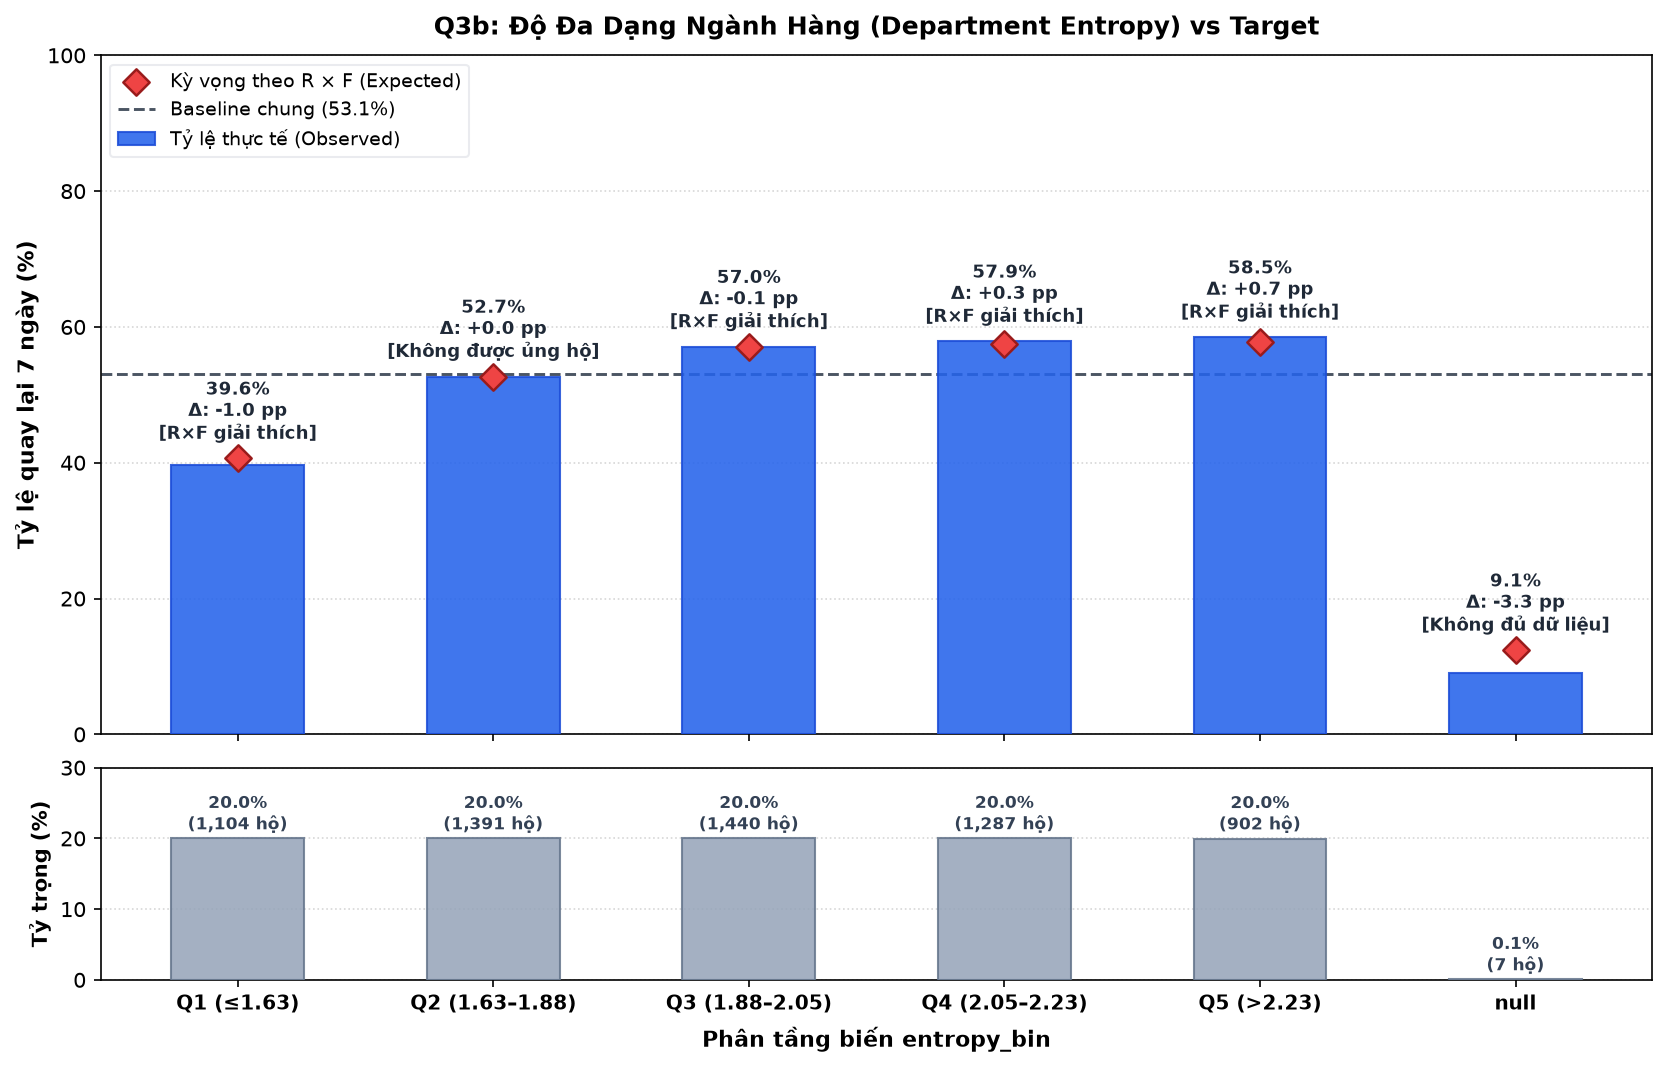

Tầng độ đa dạng (Entropy),Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Q1 (≤1.63),40424,1104,0.199884,0.396373,0.406333,-0.995997,0.654321,Đã được R × F giải thích
Q2 (1.63–1.88),40423,1391,0.199879,0.526952,0.526584,0.036812,0.543210,Không được ủng hộ
Q3 (1.88–2.05),40423,1440,0.199879,0.570170,0.570826,-0.065598,0.530864,Đã được R × F giải thích
Q4 (2.05–2.23),40451,1287,0.200018,0.578626,0.575438,0.318813,0.481481,Đã được R × F giải thích
Q5 (>2.23),40395,902,0.199741,0.584800,0.577574,0.722592,0.629630,Đã được R × F giải thích
null,121,7,0.000598,0.090909,0.123819,-3.291020,0.000000,Không đủ dữ liệu


In [ ]:
panel["entropy_bin"] = quantile_bin(panel["dept_entropy_c"], 5, prefix="Q")
q3b_excess = add_verdicts(excess_over_rf(panel, "entropy_bin"))

fig_q3b = plot_rate_and_excess(q3b_excess, title="Q3b: Độ Đa Dạng Ngành Hàng (Department Entropy) vs Target")
fig_q3b


### Phân Tích Q3b: Độ Đa Dạng Ngành Hàng (Department Diversity / Entropy) vs Target

- **Mô tả:** Nhìn thô, tỷ lệ quay lại tăng vọt **+18.84 pp** từ Q1 ($39.64\%$, $\le 1.63$ bit) lên Q5 ($58.48\%$, $> 2.23$ bit). Nhưng khi kiểm soát theo $R \times F$, tỷ lệ kỳ vọng của nhóm Q5 cũng tăng tương ứng lên $57.76\%$, khiến thặng dư thuần túy chỉ còn **-1.00 pp đến +0.72 pp**.
- **Vì sao:** Những hộ mua sắm đa dạng nhiều ngành hàng chính là những hộ có tần suất mua sắm $F$ rất cao (viếng thăm siêu thị liên tục nên tự nhiên nhặt đồ ở nhiều ngành hàng khác nhau).
- **Liên quan label:** Toàn bộ bước nhảy 18.8 pp quan sát được thực chất là phản chiếu của tần suất $F$, không phải độ đa dạng ngành hàng tự thân thúc đẩy quay lại.
- **Insight:** Phân loại tự động: **"Đã được R × F giải thích"**. Đây là một trường hợp bẫy tương quan kinh điển (Confounding Variable).
- **Hành động:** Không đưa vào feature chính. Mua đa dạng chỉ là hệ quả của việc viếng thăm nhiều lần. Có thể dùng cho phân cụm khách hàng sau, nhưng không đưa vào feature dự báo chính.

> [!NOTE]
> **Card Biến–Label (Q3b):** `dept_entropy_c` | Tác động ngoài R×F: **-1.00 đến +0.72 pp** | Phân loại: **Biến gây nhiễu / Không đưa vào feature chính (Đã được R × F giải thích)**.


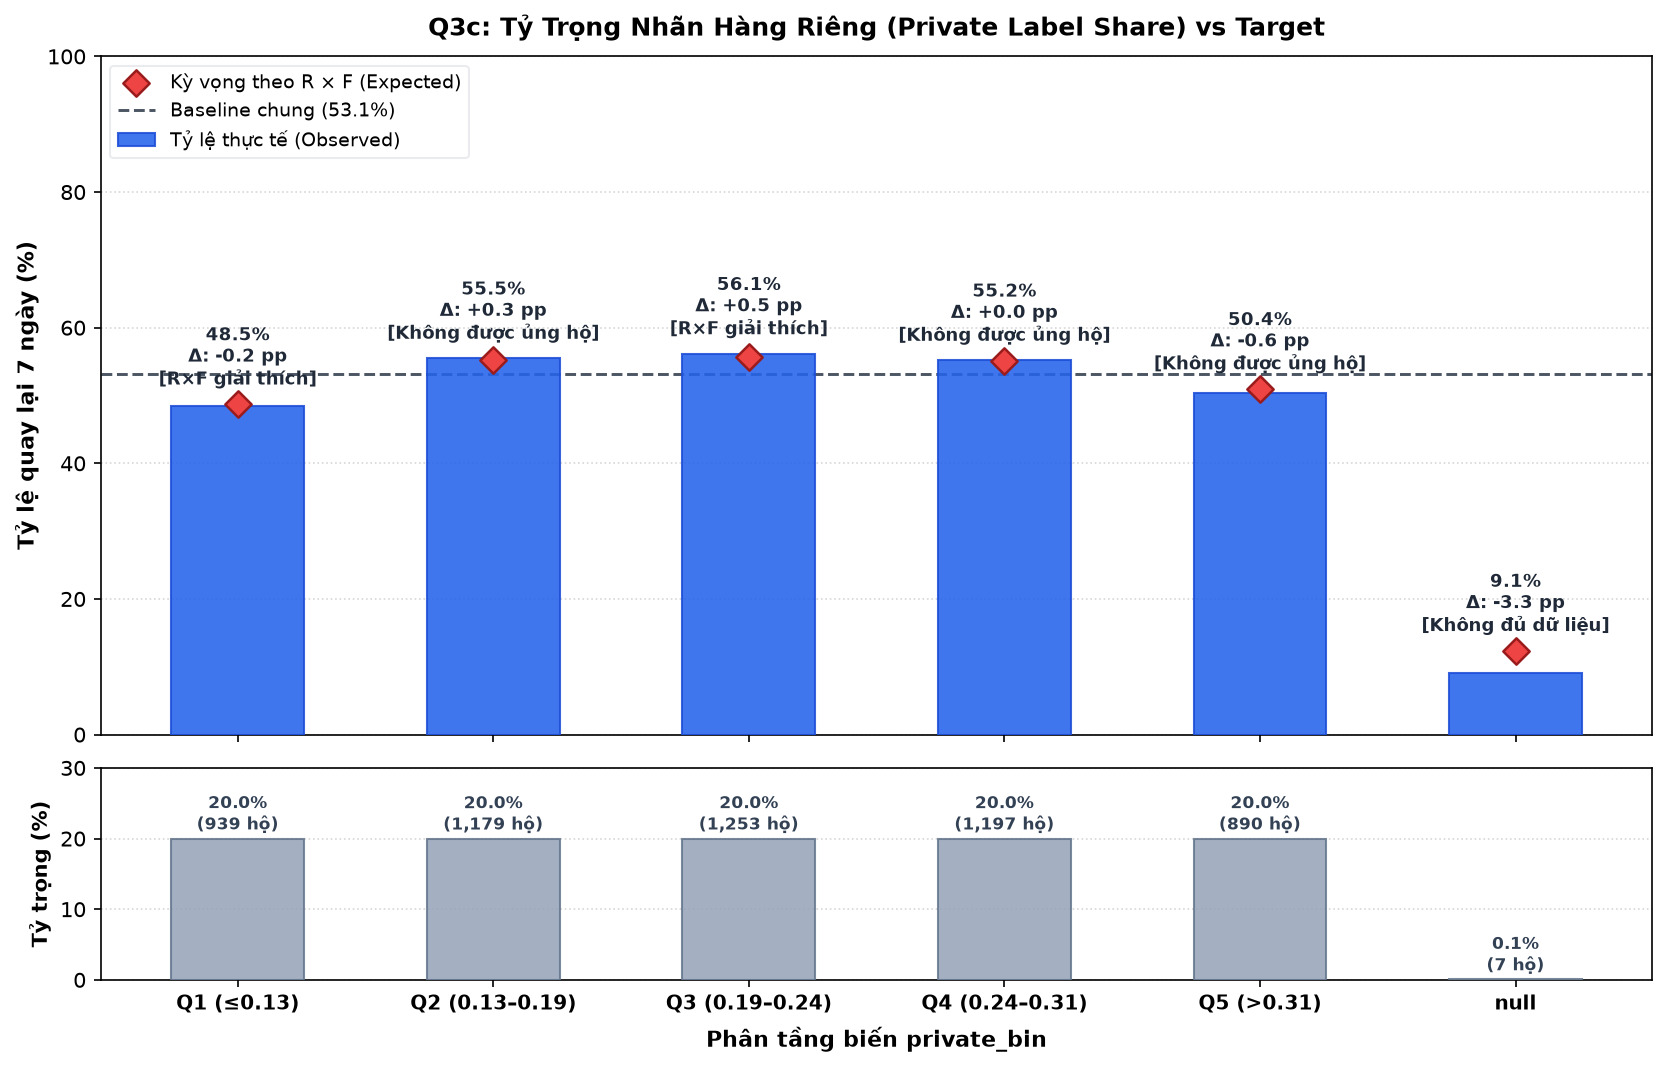

Tầng nhãn riêng (Private),Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Q1 (≤0.13),40438,939,0.199954,0.485014,0.487327,-0.231316,0.543210,Đã được R × F giải thích
Q2 (0.13–0.19),40409,1179,0.199810,0.554753,0.551656,0.309635,0.518519,Không được ủng hộ
Q3 (0.19–0.24),40423,1253,0.199879,0.561463,0.556558,0.490431,0.617284,Đã được R × F giải thích
Q4 (0.24–0.31),40423,1197,0.199879,0.551765,0.551547,0.021779,0.530864,Không được ủng hộ
Q5 (>0.31),40423,890,0.199879,0.503946,0.509686,-0.574017,0.567901,Không được ủng hộ
null,121,7,0.000598,0.090909,0.123819,-3.291020,0.000000,Không đủ dữ liệu


In [ ]:
panel["private_bin"] = quantile_bin(panel["private_label_share_c"], 5, prefix="Q")
q3c_excess = add_verdicts(excess_over_rf(panel, "private_bin"))

fig_q3c = plot_rate_and_excess(q3c_excess, title="Q3c: Tỷ Trọng Nhãn Hàng Riêng (Private Label Share) vs Target")
fig_q3c


### Phân Tích Q3c: Tỷ Trọng Nhãn Hàng Riêng (Private Label Share) vs Target

- **Mô tả:** Tỷ trọng mua nhãn riêng dao động từ dưới $13\%$ (Q1) đến trên $31\%$ (Q5). Tỷ lệ quay lại thực tế biến thiên từ $48.50\%$ đến $56.15\%$, nhưng sau khi trừ đi kỳ vọng $R \times F$, chênh lệch chỉ còn dao động hẹp từ **-0.57 pp đến +0.49 pp**.
- **Vì sao:** Khách mua hàng nhãn riêng có lòng trung thành tương đồng với các nhóm khách hàng khác khi đã chuẩn hóa cùng mức độ Recency và Frequency.
- **Liên quan label:** Nhãn hàng riêng không tạo thêm thặng dư giữ chân độc lập ngoài $R \times F$.
- **Insight:** Phân loại tự động: **"Đã được R × F giải thích"** và **"Không được ủng hộ"**. Bác bỏ giả thuyết thương mại thông thường cho rằng khách chuộng nhãn riêng thì tự động có xác suất quay lại siêu thị cao hơn hẳn.
- **Hành động:** Không đưa vào feature chính. Khách mua nhãn riêng không có thặng dư quay lại ngoài R × F; biến này chỉ phục vụ theo dõi biên lợi nhuận.

> [!NOTE]
> **Card Biến–Label (Q3c):** `private_label_share_c` | Tác động ngoài R×F: **-0.57 đến +0.49 pp** | Phân loại: **Không đưa vào feature chính (Đã được R × F giải thích)**.


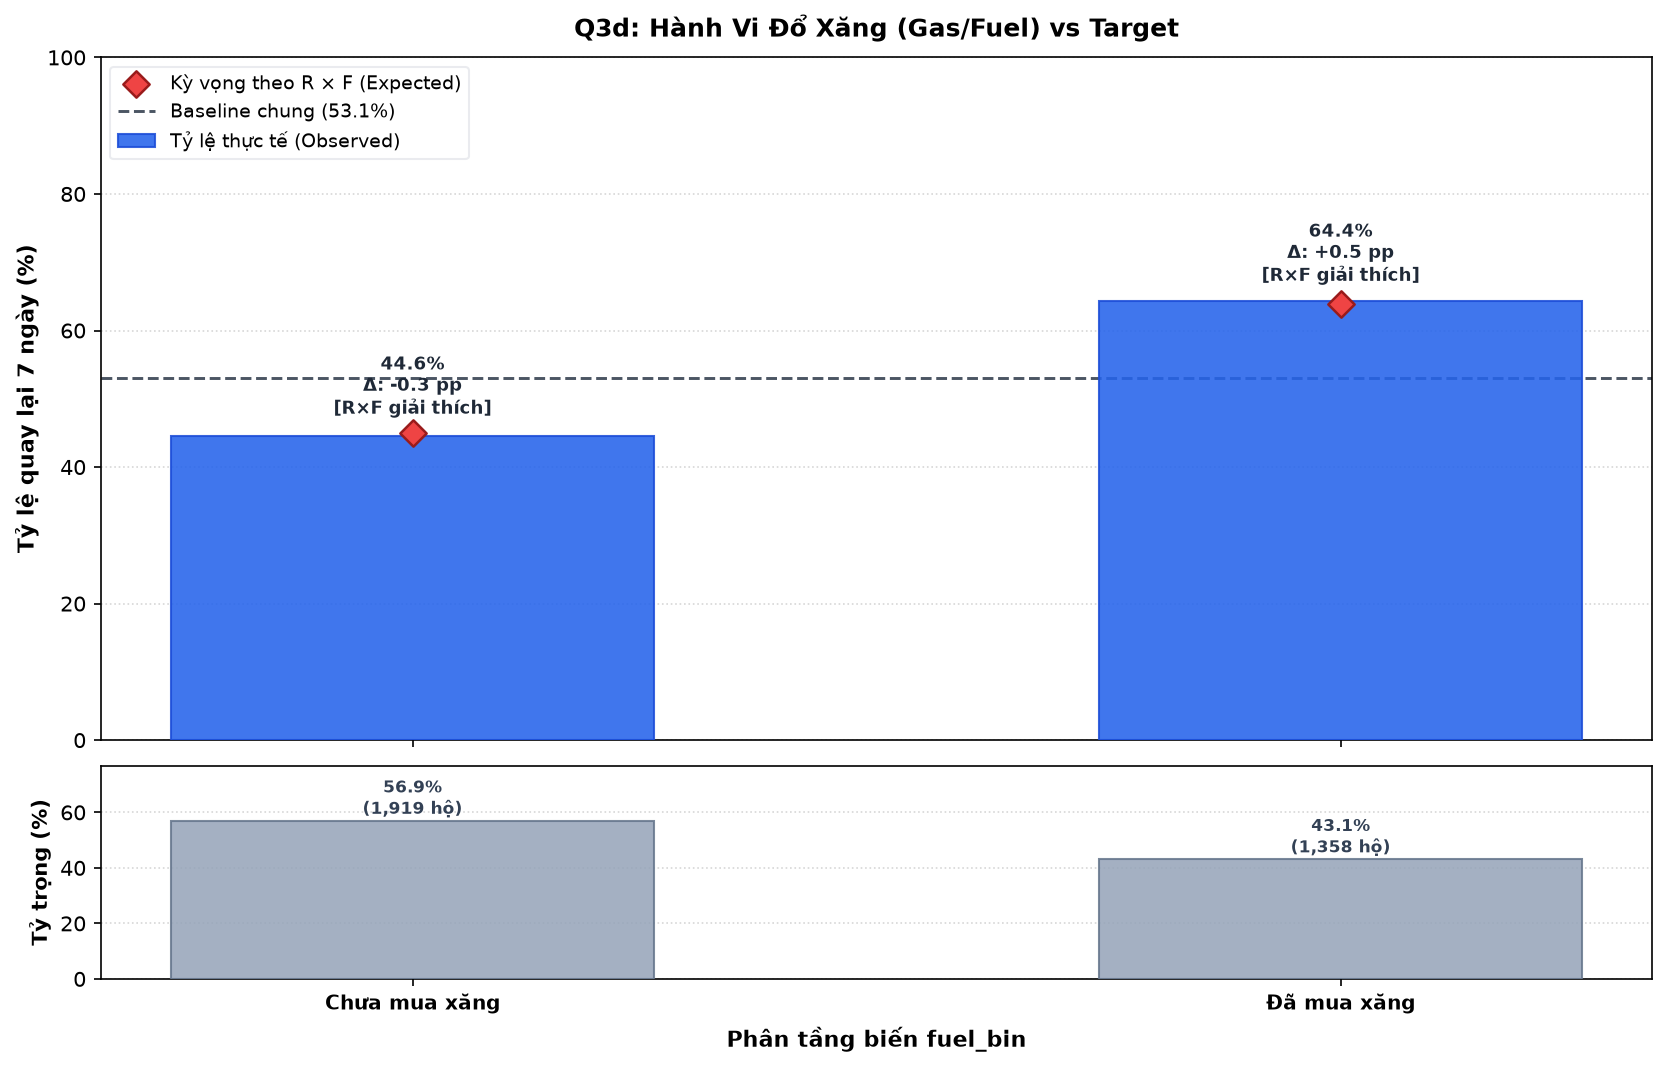

Hành vi mua xăng,Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Chưa mua xăng,115153,1919,0.569396,0.445842,0.449275,-0.343358,0.580247,Đã được R × F giải thích
Đã mua xăng,87084,1358,0.430604,0.643884,0.639314,0.457031,0.592593,Đã được R × F giải thích


In [ ]:
q3d_excess = add_verdicts(excess_over_rf(panel, "fuel_bin"))
fig_q3d = plot_rate_and_excess(q3d_excess, title="Q3d: Hành Vi Đổ Xăng (Gas/Fuel) vs Target")
fig_q3d


### Phân Tích Q3d: Hành Vi Đổ Xăng (Gas/Fuel) vs Target

- **Mô tả:** Khách hàng có đổ xăng (`buys_fuel_c == 1`, chiếm $43.06\%$ số dòng) có tỷ lệ quay lại thực tế là **64.39%**, cao hơn vượt trội so với mức **44.58%** của nhóm chưa từng đổ xăng (**chênh lệch thô +19.81 pp**). Tuy nhiên, tỷ lệ kỳ vọng $R \times F$ của nhóm mua xăng cũng là **63.93%**, dẫn đến thặng dư thuần túy chỉ là **+0.46 pp** (nhóm không mua xăng là **-0.34 pp**).
- **Vì sao:** Người ghé cây xăng là những người có tần suất viếng thăm tổng thể cao hơn hẳn. $R \times F$ đã tự nhiên dự báo nhóm này đạt xác suất quay lại 63.93%.
- **Liên quan label:** Cờ nhị phân `buys_fuel_c` không mang lại bất kỳ hiệu ứng gia tăng tuyến tính nào ($< 0.5\text{ pp}$) ngoài những gì $R \times F$ đã nắm bắt.
- **Insight:** Phân loại tự động: **"Đã được R × F giải thích"**. Xăng là dịch vụ bổ trợ tiện ích thu hút lượt ghé (Foot Traffic Generator), nhưng khi đã biết khách ghé bao nhiêu lần/tuần thì việc họ có mua xăng hay không không làm thay đổi xác suất quay lại 7 ngày tiếp theo.
- **Hành động:** Không đưa vào feature chính. Đổ xăng là tiện ích tăng lượt ghé, nhưng khi đã biết F thì việc đổ xăng không bổ sung thêm thông tin dự báo quay lại.

> [!NOTE]
> **Card Biến–Label (Q3d):** `buys_fuel_c` | Tác động ngoài R×F: **+0.46 pp** | Phân loại: **Không đưa vào feature chính (Đã được R × F giải thích)**.


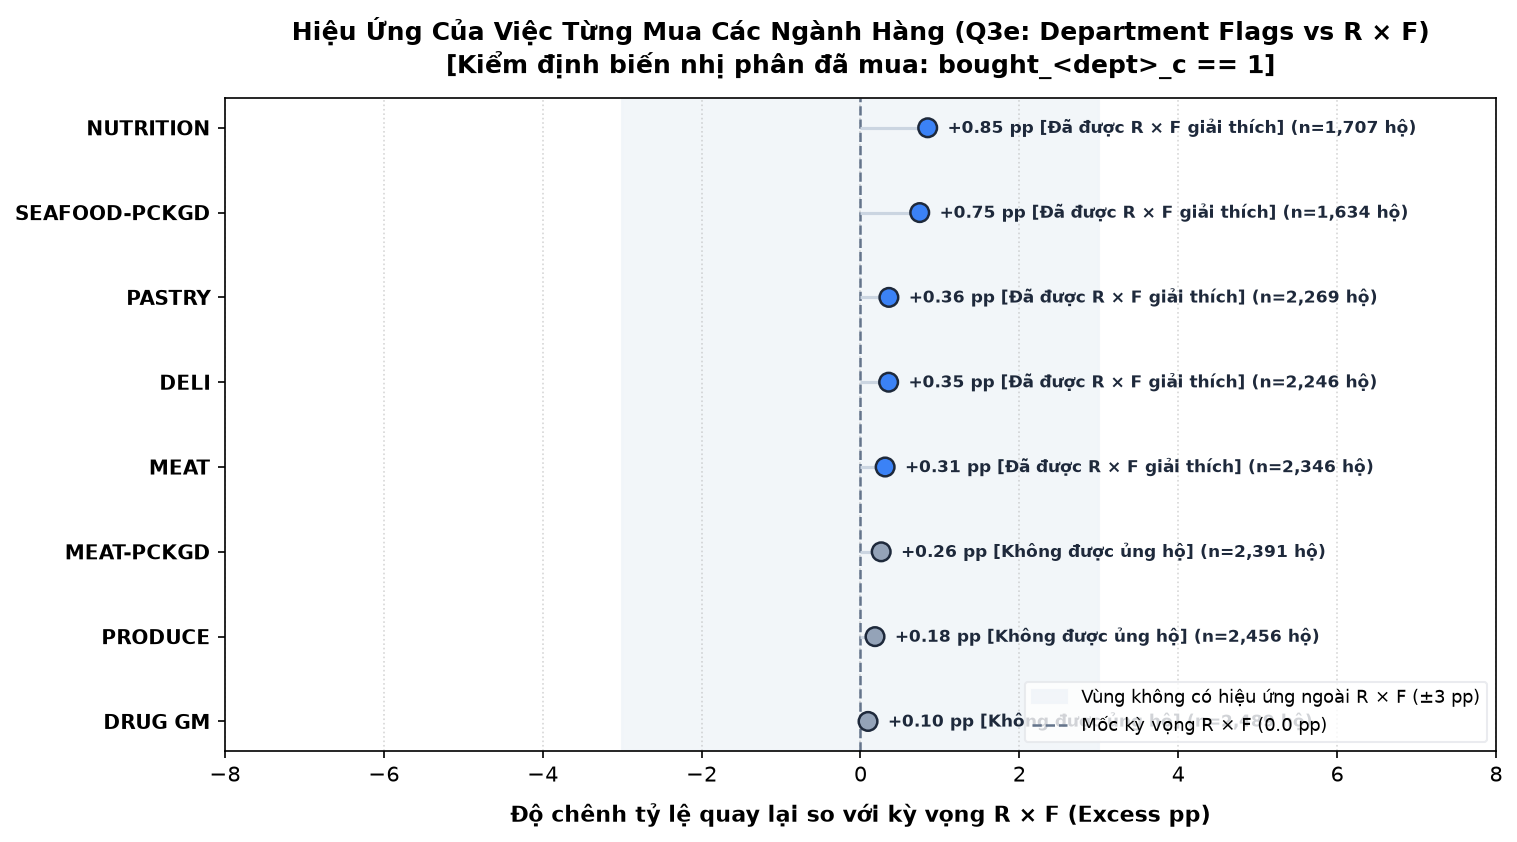

Ngành hàng,Số dòng mua (n_rows),Số hộ mua (n_hh),Tỷ lệ đã mua,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
NUTRITION,108493,1707,0.536465,0.620372,0.611910,0.846169,0.679012,Đã được R × F giải thích
SEAFOOD-PCKGD,101493,1634,0.501852,0.625294,0.617836,0.745816,0.654321,Đã được R × F giải thích
PASTRY,160069,2269,0.791492,0.580162,0.576584,0.357787,0.629630,Đã được R × F giải thích
DELI,159400,2246,0.788184,0.582967,0.579423,0.354446,0.592593,Đã được R × F giải thích
MEAT,176236,2346,0.871433,0.566263,0.563159,0.310404,0.580247,Đã được R × F giải thích
MEAT-PCKGD,182410,2391,0.901962,0.560128,0.557521,0.260764,0.580247,Không được ủng hộ
PRODUCE,191383,2456,0.946330,0.549035,0.547206,0.182945,0.580247,Không được ủng hộ
DRUG GM,195962,2489,0.968972,0.542432,0.541478,0.095327,0.555556,Không được ủng hộ


In [ ]:
q3e_df = evaluate_department_flags_excess(panel, flag_departments)
fig_q3e = plot_department_excess(q3e_df)
fig_q3e


### Phân Tích Q3e: Hiệu Ứng Thặng Dư Của Các Ngành Hàng Đã Mua (Department Flags vs R × F)

- **Mô tả:** Khảo sát 8 ngành hàng candidate có độ thâm nhập sớm trong khoảng $20\% - 90\%$. Tất cả 8 ngành hàng đều có thặng dư so với kỳ vọng $R \times F$ nằm trọn vẹn trong vùng trung tính $\pm 3.0\text{ pp}$. Hiệu ứng dương cao nhất ghi nhận ở `NUTRITION` (**+0.85 pp**) và `SEAFOOD-PCKGD` (**+0.75 pp**), tiếp theo là `PASTRY` (+0.36 pp), `DELI` (+0.35 pp), `MEAT` (+0.31 pp), `MEAT-PCKGD` (+0.26 pp), `PRODUCE` (+0.18 pp), và `DRUG GM` (+0.10 pp).
- **Vì sao:** Toàn bộ các ngành hàng thực phẩm tươi sống hay hàng tiêu dùng nhanh đều phục vụ khách mua sắm định kỳ, mà nhịp độ đó đã được gói gọn trong $R$ và $F$.
- **Liên quan label:** Không có bất kỳ ngành hàng đơn lẻ nào tạo ra cú hích quay lại vượt trội $\ge 3.0\text{ pp}$ so với kỳ vọng $R \times F$.
- **Insight:** Phân loại tự động: Tất cả 8 ngành hàng đều là **"Đã được R × F giải thích"** hoặc **"Không được ủng hộ"**. Việc mua một ngành hàng cụ thể không làm thay đổi căn bản xu hướng quay lại nếu không làm tăng tần suất $F$.
- **Hành động:** Không đưa 8 cờ ngành hàng này vào feature chính. Không có department nào giữ chân khách độc lập với F.

> [!NOTE]
> **Card Biến–Label (Q3e):** `bought_<dept>_c` | Tác động ngoài R×F cao nhất: **+0.85 pp** | Phân loại: **Không đưa vào feature chính (Đã được R × F giải thích)**.


---
### Bảng Đặc Tả Feature Danh Mục Hàng Hóa (Category Feature Specification)

| Tên Feature | Định nghĩa kỹ thuật | Kỷ luật As-of Cutoff | Xử lý Missing / Outlier | Quyết định từ EDA |
| :--- | :--- | :--- | :--- | :--- |
| `staple_spend_share_c` | $\frac{\text{Chi tiêu 5 commodity thiết yếu}}{\text{Tổng chi tiêu hàng hóa}}$ | Chỉ tính các giao dịch có $DAY < c$. | Gán `null` khi chưa có chi tiêu hàng hóa; dải $[0, 1]$. | **Không đưa vào feature chính**. Thặng dư ngoài R×F chỉ $-0.86$ đến $+0.49\text{ pp}$. |
| `dept_entropy_c` | Entropy Shannon (bit): $-\sum p_i \log_2(p_i)$ trên chi tiêu ngành hàng | Chỉ tính các giao dịch có $DAY < c$. | Gán `null` khi không có chi tiêu hàng hóa. | **Không đưa vào feature chính** (Biến gây nhiễu). Thặng dư ngoài R×F chỉ $-1.00$ đến $+0.72\text{ pp}$. |
| `n_departments_c` | Số lượng ngành hàng hàng hóa khác nhau đã từng mua | Chỉ tính các giao dịch có $DAY < c$. | Số nguyên không âm $\ge 0$. | **Không đưa vào feature chính**. |
| `private_label_share_c` | $\frac{\text{Chi tiêu nhãn hàng riêng}}{\text{Tổng chi tiêu hàng hóa}}$ | Chỉ tính các giao dịch có $DAY < c$. | Gán `null` khi chưa có chi tiêu hàng hóa; dải $[0, 1]$. | **Không đưa vào feature chính**. Thặng dư ngoài R×F chỉ $-0.57$ đến $+0.49\text{ pp}$. |
| `buys_fuel_c` | Cờ nhị phân: 1 nếu từng đổ xăng trước cutoff, 0 nếu chưa | Chỉ tính các giao dịch có $DAY < c$. | Nhị phân $\{0, 1\}$, không có missing. | **Không đưa vào feature chính**. Thặng dư ngoài R×F chỉ $+0.46\text{ pp}$. |
| `fuel_share_c` | $\frac{\text{Chi tiêu xăng}}{\text{Tổng chi tiêu}}$ | Chỉ tính các giao dịch có $DAY < c$. | Gán 0.0 khi tổng chi tiêu = 0; dải $[0, 1]$. | **Không đưa vào feature chính**. |
| `bought_<dept>_c` | Cờ nhị phân: 1 nếu từng mua ngành hàng `<dept>` trước cutoff | Chỉ tính các giao dịch có $DAY < c$. | Nhị phân $\{0, 1\}$, 8 ngành hàng chọn lọc. | **Không đưa vào feature chính**. Thặng dư ngoài R×F chỉ $+0.10$ đến $+0.85\text{ pp}$. |

> [!IMPORTANT]
> **Thông điệp cốt lõi cho slide Category:**
> *"Khách mua gì không cho biết họ có quay lại tuần sau hay không. Mua gần đây (R) và mua thường xuyên (F) mới quyết định. Mọi chênh lệch thô về category, lớn nhất +19 điểm %, đều biến mất sau khi kiểm soát R × F."*
> **Hành động Business:** Muốn giữ khách thì phải tác động vào tần suất viếng thăm, không phải cơ cấu giỏ hàng.
>
> *(Ghi chú lộ trình: Biến Q1c lapse_ratio_c đã được tính toán trong panel và sẽ được phân tích phân tầng trước Phần 8 - Chia nhóm khách hàng).*


## Phần 3: Promotion và Campaign (Q6 Overview, Q7 & Q8 × Label)

Mục tiêu phân tích:
- **Q6 (Mô tả):** Khảo sát bức tranh tổng quan: Promotion xuất hiện khi nào, tỷ lệ bao nhiêu, tập trung ở department và commodity nào?
- **Q7 (× Label):** Hộ chuyên săn giảm giá (`promo_spend_share_c`, `discount_depth_c`) hoặc hay dùng coupon (`used_coupon_c`) có xác suất quay lại khác biệt sau khi đã kiểm soát $R \times F$?
- **Q8 (Mô tả & × Label):** Các chiến dịch marketing (Campaign) nhắm vào ai (kiểm định **Selection Bias**), tỷ lệ đổi coupon (Redemption) ra sao, và việc đang trong chiến dịch (`in_active_campaign_c`) hay đã redeem (`redeemed_coupon_c`) có liên quan đến quay lại?

> [!WARNING]
> **Lưu ý phương pháp luận:** Mọi phân tích ở đây thuần túy là đo lường mối liên hệ quan sát (Association), không đại diện cho tác động nhân quả (Causal Effect) vì chiến dịch marketing có độ lệch chọn mẫu có chủ đích (Selection Bias). File `causal_data.csv` (display/mailer) được để dành cho nghiên cứu chuyên sâu về sau.


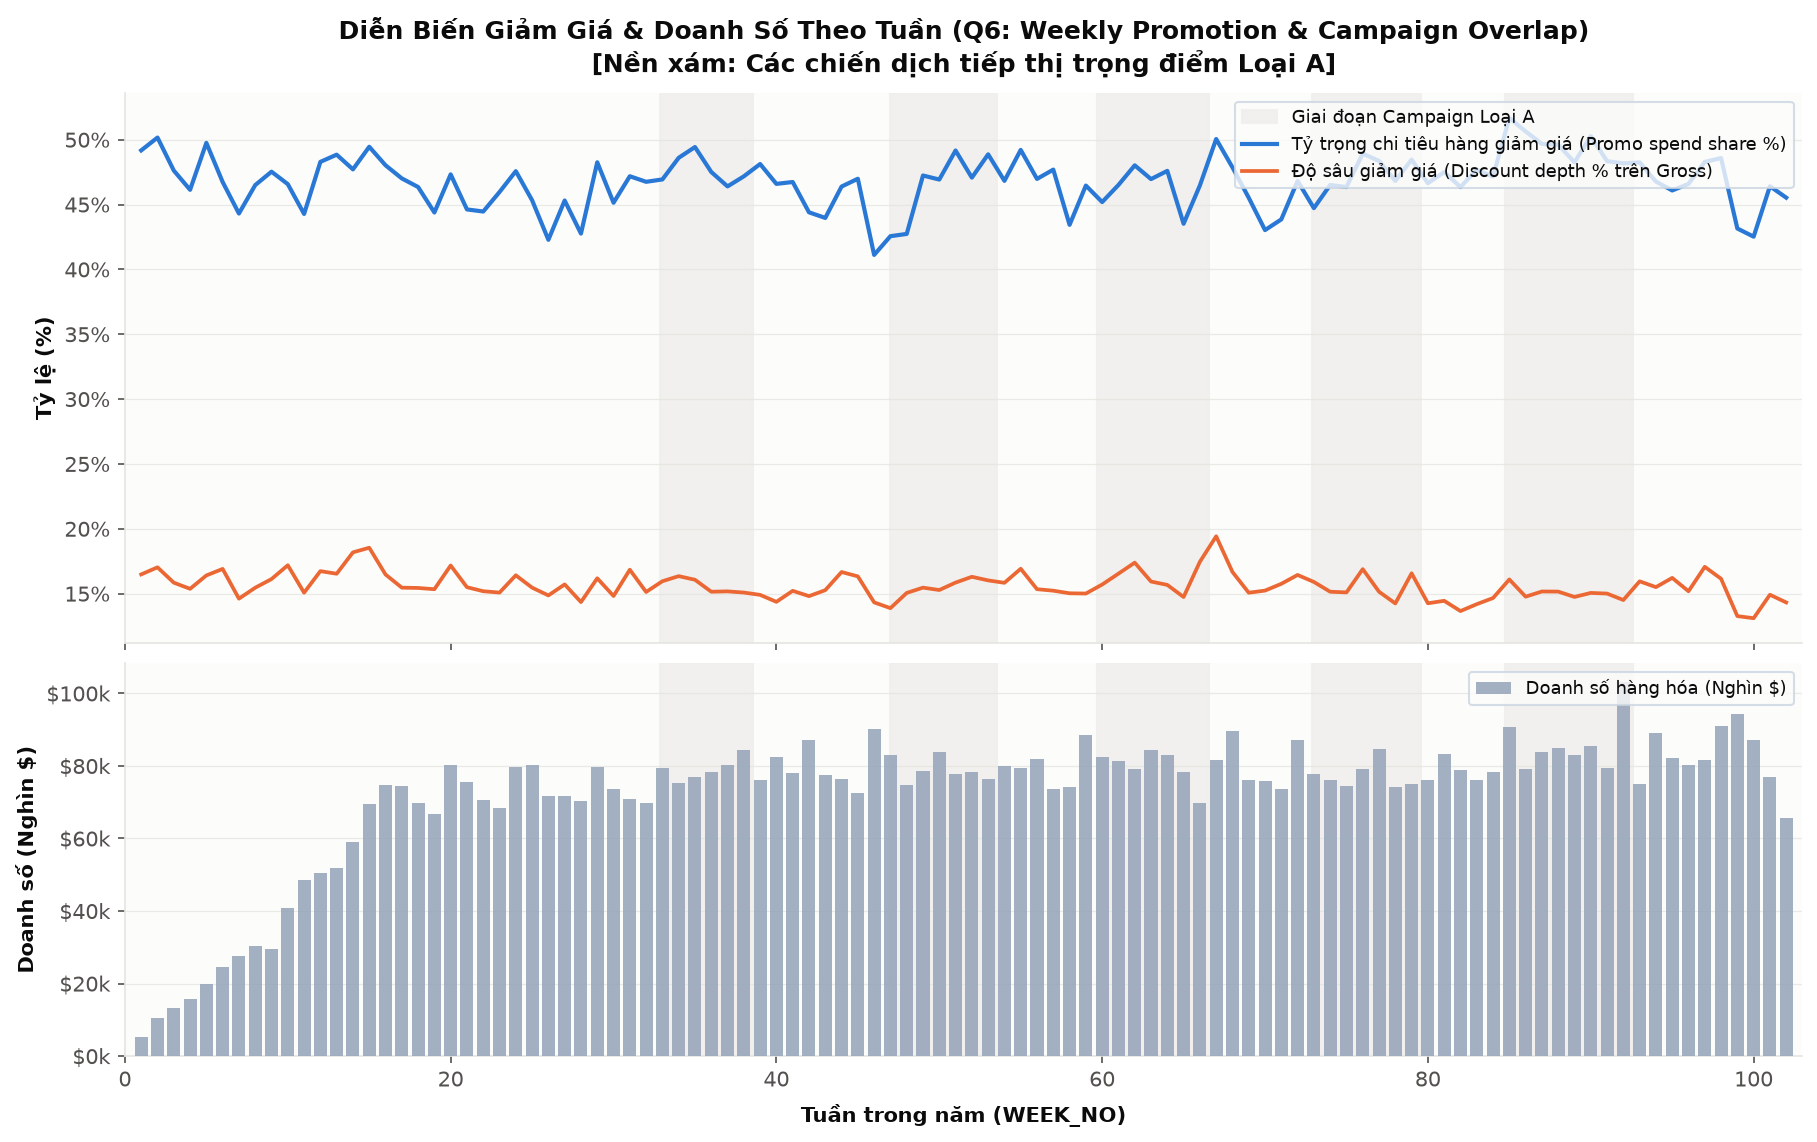

In [ ]:
from propensity.eda.promotion import (
    weekly_promo_summary,
    department_promo_summary,
    commodity_promo_summary,
    promo_dept_week,
    campaign_summary,
    campaign_type_summary,
    campaign_reach_by_rf,
)
from propensity.features.promotion import promo_features, campaign_features
from propensity.eda.promotion_plots import (
    plot_weekly_promo,
    plot_department_promo,
    plot_promo_dept_week,
    plot_campaign_overview,
    plot_campaign_reach,
)

cd = pd.read_csv(raw_dir / "campaign_desc.csv")
ct = pd.read_csv(raw_dir / "campaign_table.csv")
cr = pd.read_csv(raw_dir / "coupon_redempt.csv")

weekly = weekly_promo_summary(lines)
camp = campaign_summary(cd, ct, cr)

fig_q6a = plot_weekly_promo(weekly, camp)
fig_q6a


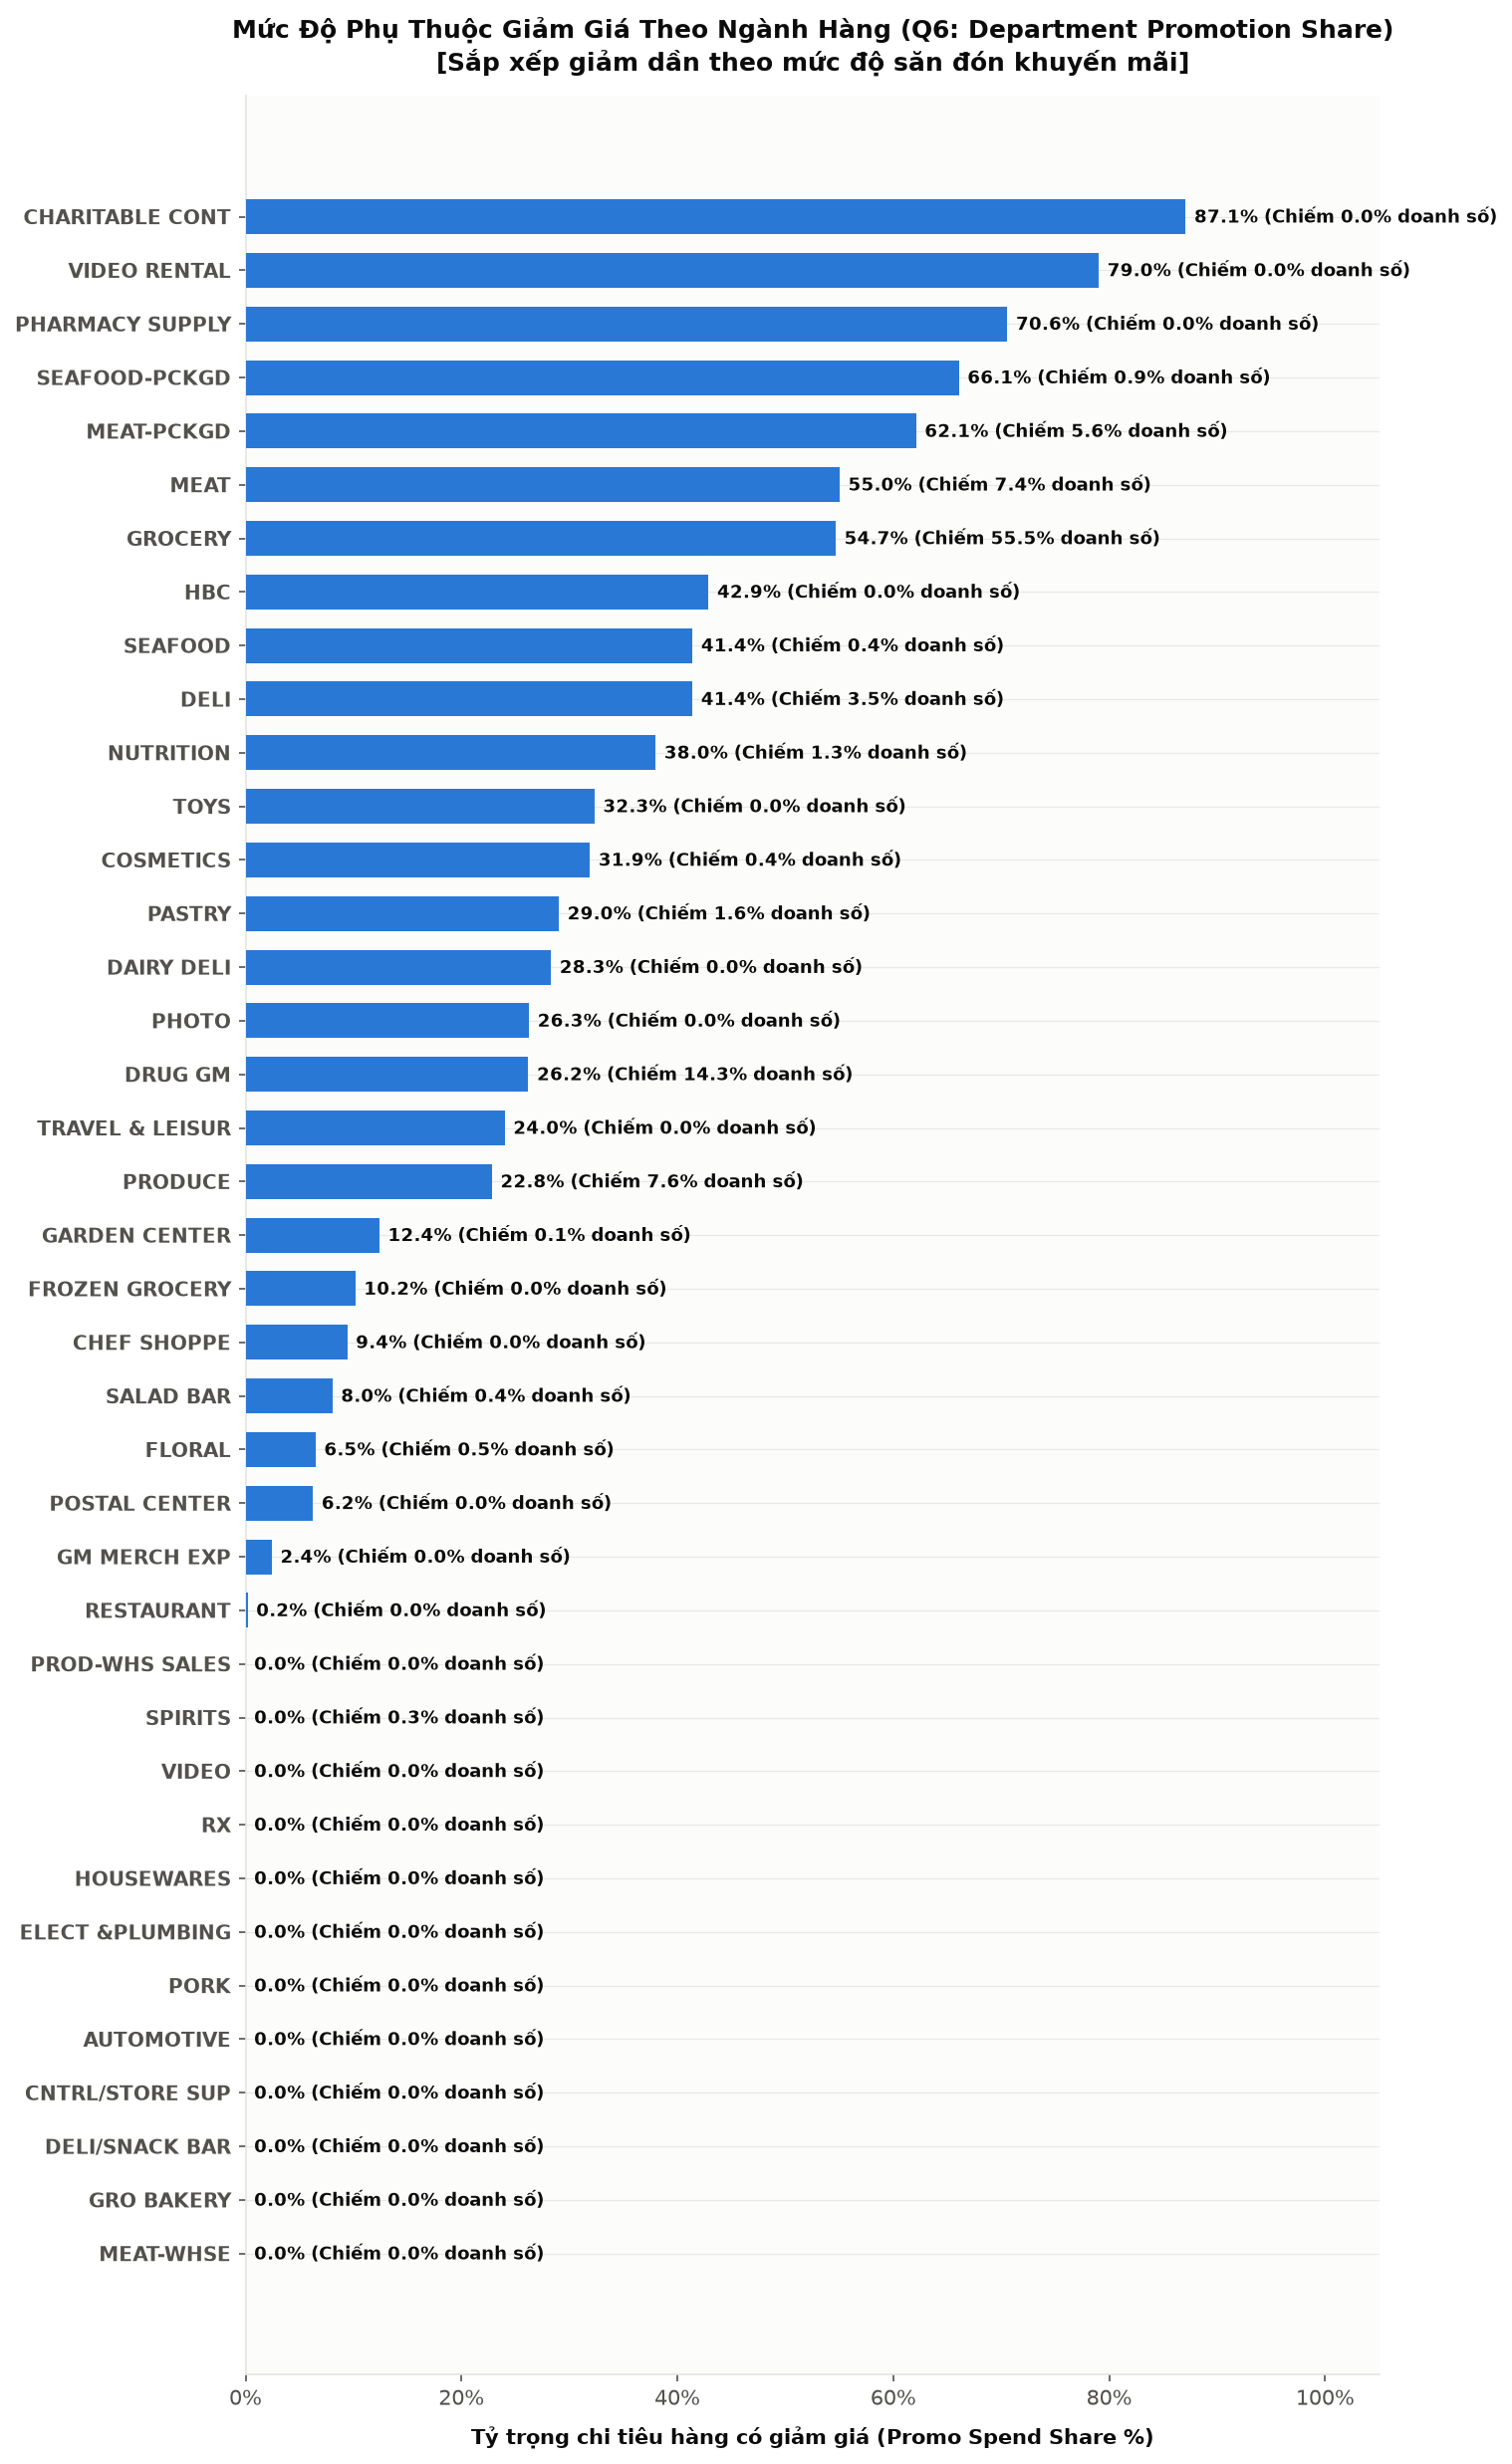

Commodity,Ngành hàng,Tỷ trọng doanh số,% Giảm giá,Độ sâu giảm,Tỷ lệ coupon
INFANT FORMULA,DRUG GM,0.006890,0.895706,0.133450,0.001900
FRZN VEGETABLE/VEG DSH,GROCERY,0.005881,0.854142,0.188536,0.003292
ICE CREAM/MILK/SHERBTS,GROCERY,0.011167,0.777520,0.315048,0.003453
MEAT - MISC,MEAT-PCKGD,0.008925,0.766962,0.224997,0.001407
YOGURT,GROCERY,0.008039,0.756936,0.186786,0.008236
FROZEN MEAT,MEAT-PCKGD,0.006897,0.752293,0.165574,0.003660
LAUNDRY DETERGENTS,GROCERY,0.007461,0.750986,0.167090,0.008797
CHEESE,GROCERY,0.025676,0.746597,0.209794,0.001877
BATH TISSUES,GROCERY,0.008212,0.737112,0.182745,0.009533
FRZN MEAT/MEAT DINNERS,GROCERY,0.021746,0.736429,0.224924,0.003801


In [ ]:
dept_p = department_promo_summary(lines)
fig_q6b = plot_department_promo(dept_p)
fig_q6b
display(HTML("<h4>Top 20 Commodity Có Tỷ Trọng Bán Giảm Giá Cao Nhất (Tối thiểu 0.5% Doanh Số)</h4>"))
display(comm_top20)


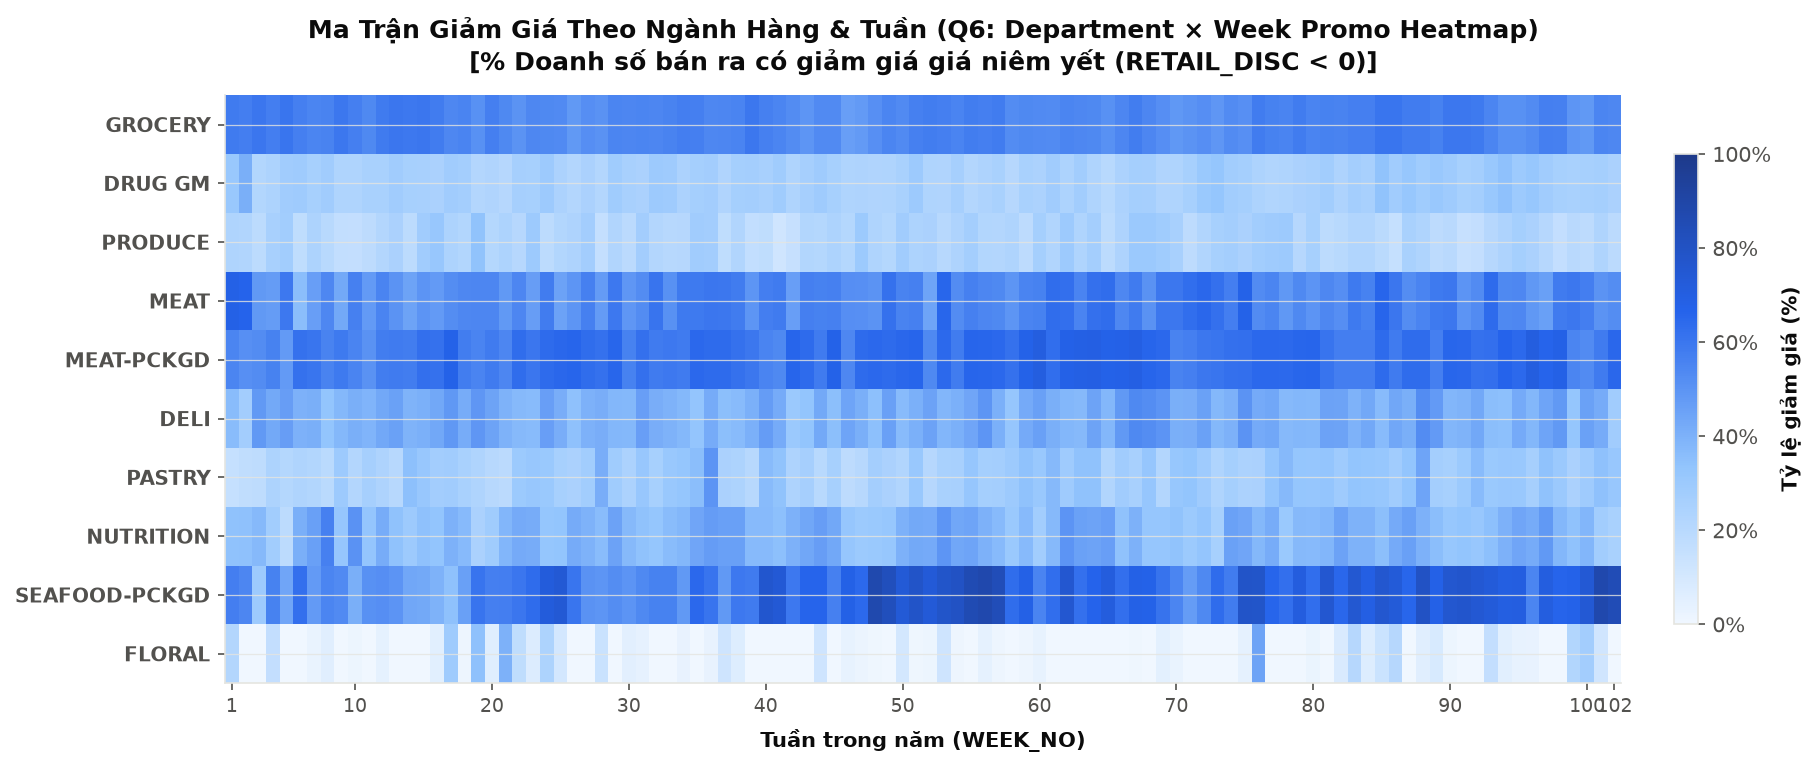

In [ ]:
p_mat = promo_dept_week(lines, top_n=10)
fig_q6c = plot_promo_dept_week(p_mat)
fig_q6c


### Phân Tích Q6: Bức Tranh Giảm Giá & Chiến Dịch (Promotion Overview)

- **Mô tả:** Giảm giá diễn ra thường xuyên và có quy mô rất lớn: **46.75%** tổng doanh số hàng hóa hợp lệ bán ra có áp dụng giảm giá niêm yết (`RETAIL_DISC < 0`). Tỷ trọng doanh số giảm giá duy trì ổn định quanh mức 40%–55% qua 102 tuần, với độ sâu giảm giá trung bình (Discount Depth trên Gross) dao động trong khoảng 12%–17%.
- **Vì sao:** Bán lẻ siêu thị tại Mỹ vận hành theo chu kỳ chương trình khuyến mãi hàng tuần (Weekly Circular / Feature & Display), luân phiên giảm giá các danh mục để kích cầu.
- **Tập trung ngành hàng & commodity:** Ngành hàng giảm giá mạnh nhất là thực phẩm đóng gói: `SEAFOOD-PCKGD` (66.1% promo share, giảm 24.8%), `MEAT-PCKGD` (62.1% promo share, giảm 21.9%), và `GROCERY` (~48% promo share). Trong top commodity, các mặt hàng đồ uống đóng chai, thịt chế biến, và đồ hộp có tới 60%–75% doanh số được mua trong đợt giảm giá.
- **Trùng khớp chiến dịch:** Các chiến dịch trọng điểm Loại A (Type A) kéo dài 4–8 tuần phủ kín giai đoạn nửa sau của năm, trùng khớp với các đợt tăng mạnh doanh số hàng tuần.
- **Hành động:** Ghi nhận bức tranh nền về cường độ khuyến mãi. Chuyển sang kiểm định Q7: Khách hàng thường xuyên mua giảm giá có tỷ lệ quay lại cao hơn không sau khi kiểm soát $R \times F$?

> [!NOTE]
> **Card Biến–Label (Q6):** `promotion_dynamics` | Tỷ trọng giảm giá toàn mạng lưới: **46.75%** | Phân loại: **Mô tả thị trường & Cơ cấu giá**.


In [ ]:
pf = promo_features(lines, cutoffs)
panel = join_features(panel, pf)

null_promo = panel["promo_spend_share_c"].isna().mean()
null_depth = panel["discount_depth_c"].isna().mean()
print(f"Kích thước panel sau khi ghép feature Promotion: {panel.shape}")
print(f"Tỷ lệ null promo_spend_share_c: {null_promo:.2%} (chỉ 121 dòng chưa từng mua hàng)")
print(f"Tỷ lệ null discount_depth_c: {null_depth:.2%}")


Kích thước panel sau khi ghép feature Promotion: (202237, 42)
Tỷ lệ null promo_spend_share_c: 0.06% (chỉ 121 dòng chưa từng mua hàng)
Tỷ lệ null discount_depth_c: 0.06%


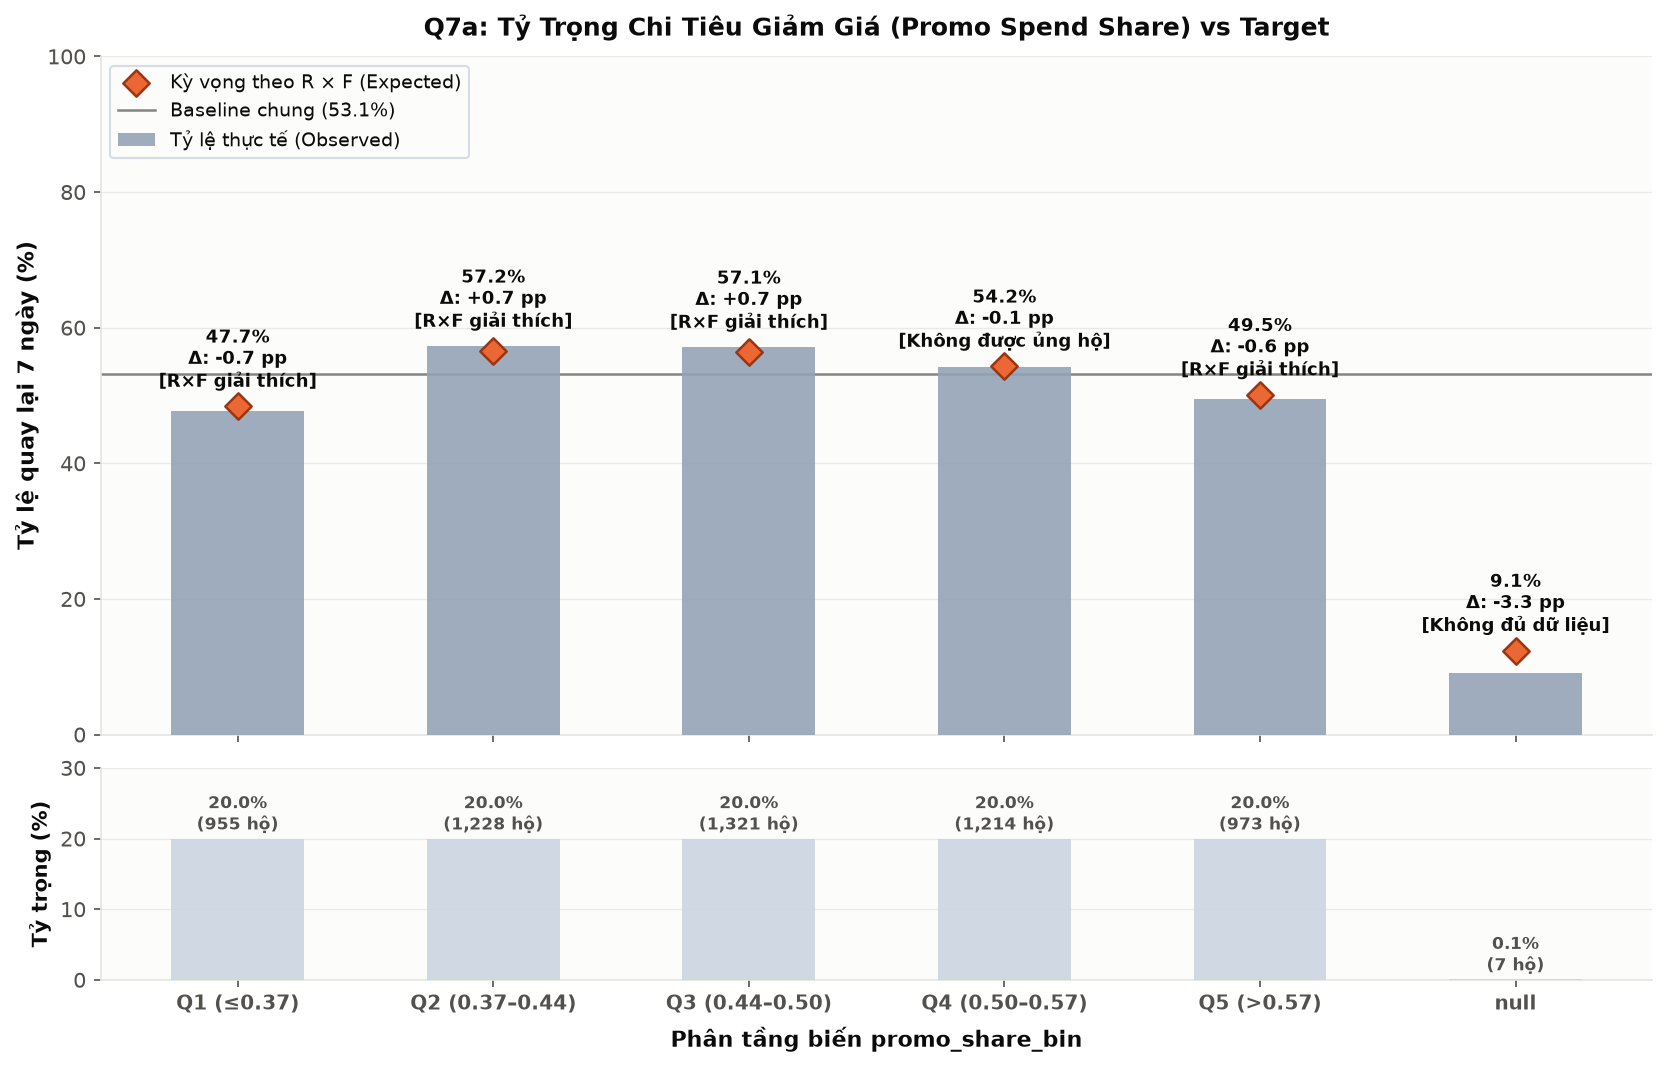

Tầng tỷ trọng giảm giá,Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Q1 (≤0.37),40424,955,0.199884,0.477118,0.483957,-0.683911,0.580247,Đã được R × F giải thích
Q2 (0.37–0.44),40423,1228,0.199879,0.572446,0.565185,0.726150,0.567901,Đã được R × F giải thích
Q3 (0.44–0.50),40423,1321,0.199879,0.570888,0.563738,0.714981,0.617284,Đã được R × F giải thích
Q4 (0.50–0.57),40424,1214,0.199884,0.541733,0.542946,-0.121295,0.567901,Không được ủng hộ
Q5 (>0.57),40422,973,0.199874,0.494731,0.500927,-0.619603,0.679012,Đã được R × F giải thích
null,121,7,0.000598,0.090909,0.123819,-3.291020,0.000000,Không đủ dữ liệu


In [ ]:
panel["promo_share_bin"] = quantile_bin(panel["promo_spend_share_c"], 5, prefix="Q")
q7a_excess = add_verdicts(excess_over_rf(panel, "promo_share_bin"))

fig_q7a = plot_rate_and_excess(q7a_excess, title="Q7a: Tỷ Trọng Chi Tiêu Giảm Giá (Promo Spend Share) vs Target")
fig_q7a


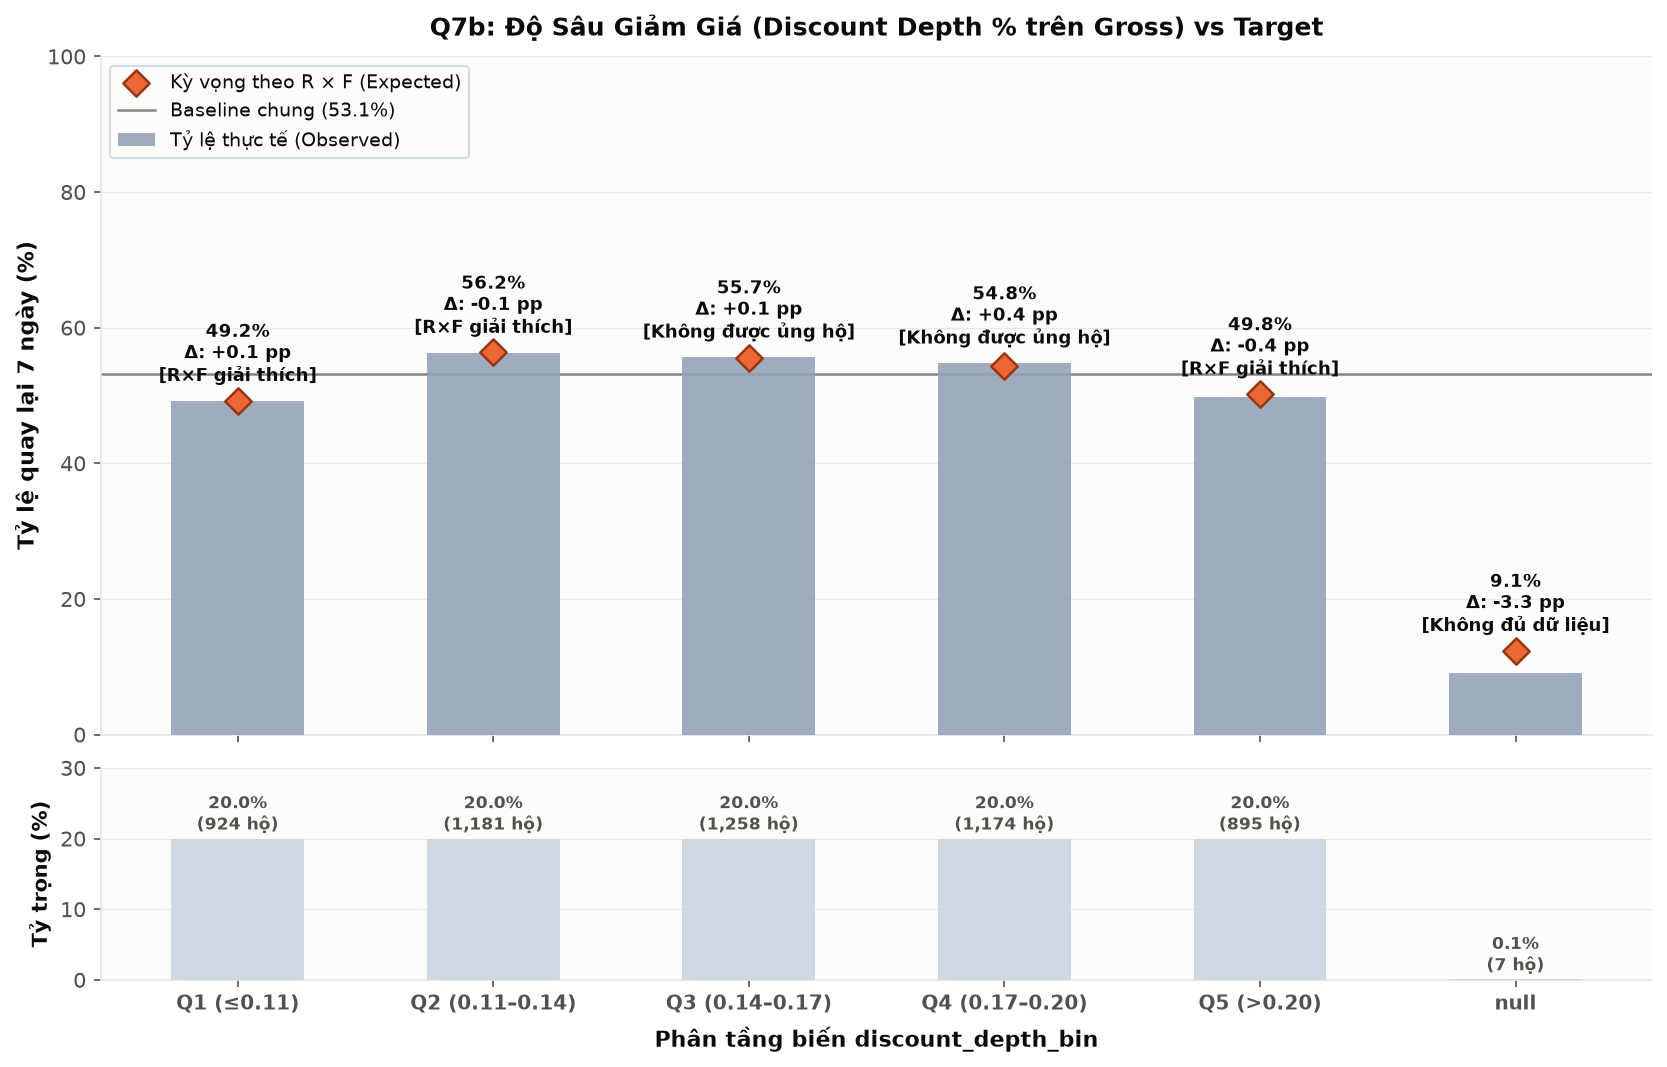

Tầng độ sâu giảm giá,Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Q1 (≤0.11),40424,924,0.199884,0.492430,0.491683,0.074684,0.592593,Đã được R × F giải thích
Q2 (0.11–0.14),40423,1181,0.199879,0.562378,0.563494,-0.111602,0.530864,Đã được R × F giải thích
Q3 (0.14–0.17),40426,1258,0.199894,0.556523,0.555925,0.059845,0.506173,Không được ủng hộ
Q4 (0.17–0.20),40421,1174,0.199869,0.547760,0.543459,0.430038,0.617284,Không được ủng hộ
Q5 (>0.20),40422,895,0.199874,0.497823,0.502189,-0.436644,0.530864,Đã được R × F giải thích
null,121,7,0.000598,0.090909,0.123819,-3.291020,0.000000,Không đủ dữ liệu


In [ ]:
panel["discount_depth_bin"] = quantile_bin(panel["discount_depth_c"], 5, prefix="Q")
q7b_excess = add_verdicts(excess_over_rf(panel, "discount_depth_bin"))

fig_q7b = plot_rate_and_excess(q7b_excess, title="Q7b: Độ Sâu Giảm Giá (Discount Depth % trên Gross) vs Target")
fig_q7b


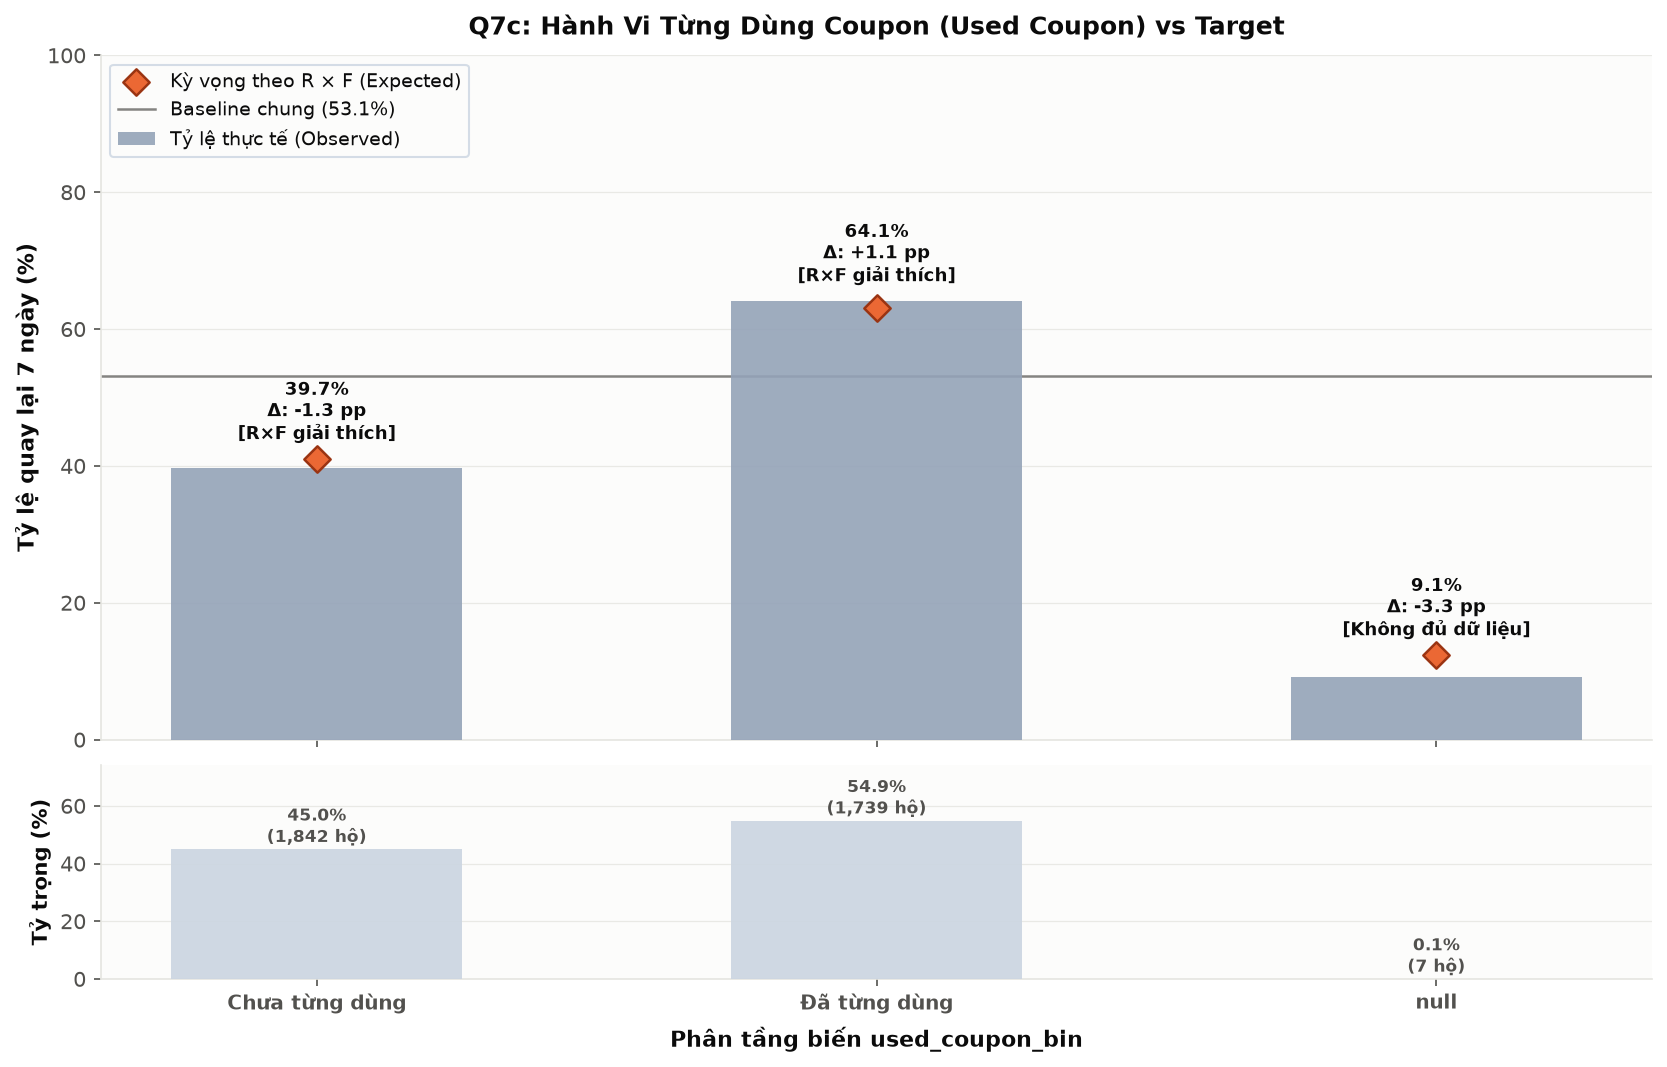

Hành vi dùng coupon,Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Chưa từng dùng,91051,1842,0.450219,0.397470,0.410459,-1.298965,0.802469,Đã được R × F giải thích
Đã từng dùng,111065,1739,0.549182,0.641165,0.630457,1.070830,0.691358,Đã được R × F giải thích
null,121,7,0.000598,0.090909,0.123819,-3.291020,0.000000,Không đủ dữ liệu


In [ ]:
panel["used_coupon_bin"] = panel["used_coupon_c"].map({0: "Chưa từng dùng", 1: "Đã từng dùng"}).astype("category")
q7c_excess = add_verdicts(excess_over_rf(panel, "used_coupon_bin"))

fig_q7c = plot_rate_and_excess(q7c_excess, title="Q7c: Hành Vi Từng Dùng Coupon (Used Coupon) vs Target")
fig_q7c


### Phân Tích Q7: Khách Hàng Săn Khuyến Mãi vs Target (Kiểm Soát R × F)

- **Mô tả Q7a (Tỷ trọng giảm giá):** Tỷ lệ quay lại quan sát thô biến thiên từ **47.71%** (Q1 $\le 0.37$) lên **57.24%** (Q2) rồi giảm về **49.47%** (Q5 $> 0.57$). Nhưng sau khi trừ đi kỳ vọng $R \times F$, chênh lệch thuần túy chỉ dao động hẹp từ **-0.68 pp đến +0.73 pp**. Verdict: **"Đã được R × F giải thích"**.
- **Mô tả Q7b (Độ sâu giảm giá):** Biên độ thặng dư thuần túy sau $R \times F$ hoàn toàn nằm trong dải cực hẹp từ **-0.44 pp đến +0.43 pp**. Verdict: **"Đã được R × F giải thích"**.
- **Mô tả Q7c (Đã từng dùng coupon):** Nhìn thô, nhóm từng dùng coupon có tỷ lệ quay lại là **64.12%**, cao hơn vượt bậc so với **39.75%** của nhóm chưa dùng (+24.37 pp). Tuy nhiên, kỳ vọng $R \times F$ của nhóm dùng coupon cũng là **63.05%** (do họ đi mua sắm nhiều hơn). Thặng dư thực chất ngoài $R \times F$ chỉ là **+1.07 pp** (nhóm chưa dùng là **-1.30 pp**). Verdict: **"Đã được R × F giải thích"**.
- **Insight:** Bác bỏ giả thuyết khách hàng "nghiện giảm giá" hay "chuộng coupon" sẽ quay lại nhiều hơn hoặc ít hơn. Thói quen săn ưu đãi không phân biệt được ai sẽ quay lại tuần sau.
- **Hành động:** **Không đưa vào feature chính**. Có thể thử lại trong mô hình sau, nhưng kết luận từ EDA cho thấy các biến giảm giá không tạo thêm tín hiệu dự báo độc lập ngoài $R \times F$.

> [!NOTE]
> **Card Biến–Label (Q7):** `promo_spend_share_c`, `discount_depth_c`, `used_coupon_c` | Tác động ngoài R×F: **-0.68 đến +1.07 pp** | Phân loại: **Không đưa vào feature chính (Đã được R × F giải thích)**.


Loại chiến dịch,Số chiến dịch,Thời lượng trung vị (ngày),Tổng lượt hộ nhận,Tổng lượt hộ đổi,Tỷ lệ đổi coupon gộp
TypeA,5,48.0,3979,635,0.159588
TypeB,19,33.0,2655,210,0.079096
TypeC,6,65.0,574,44,0.076655


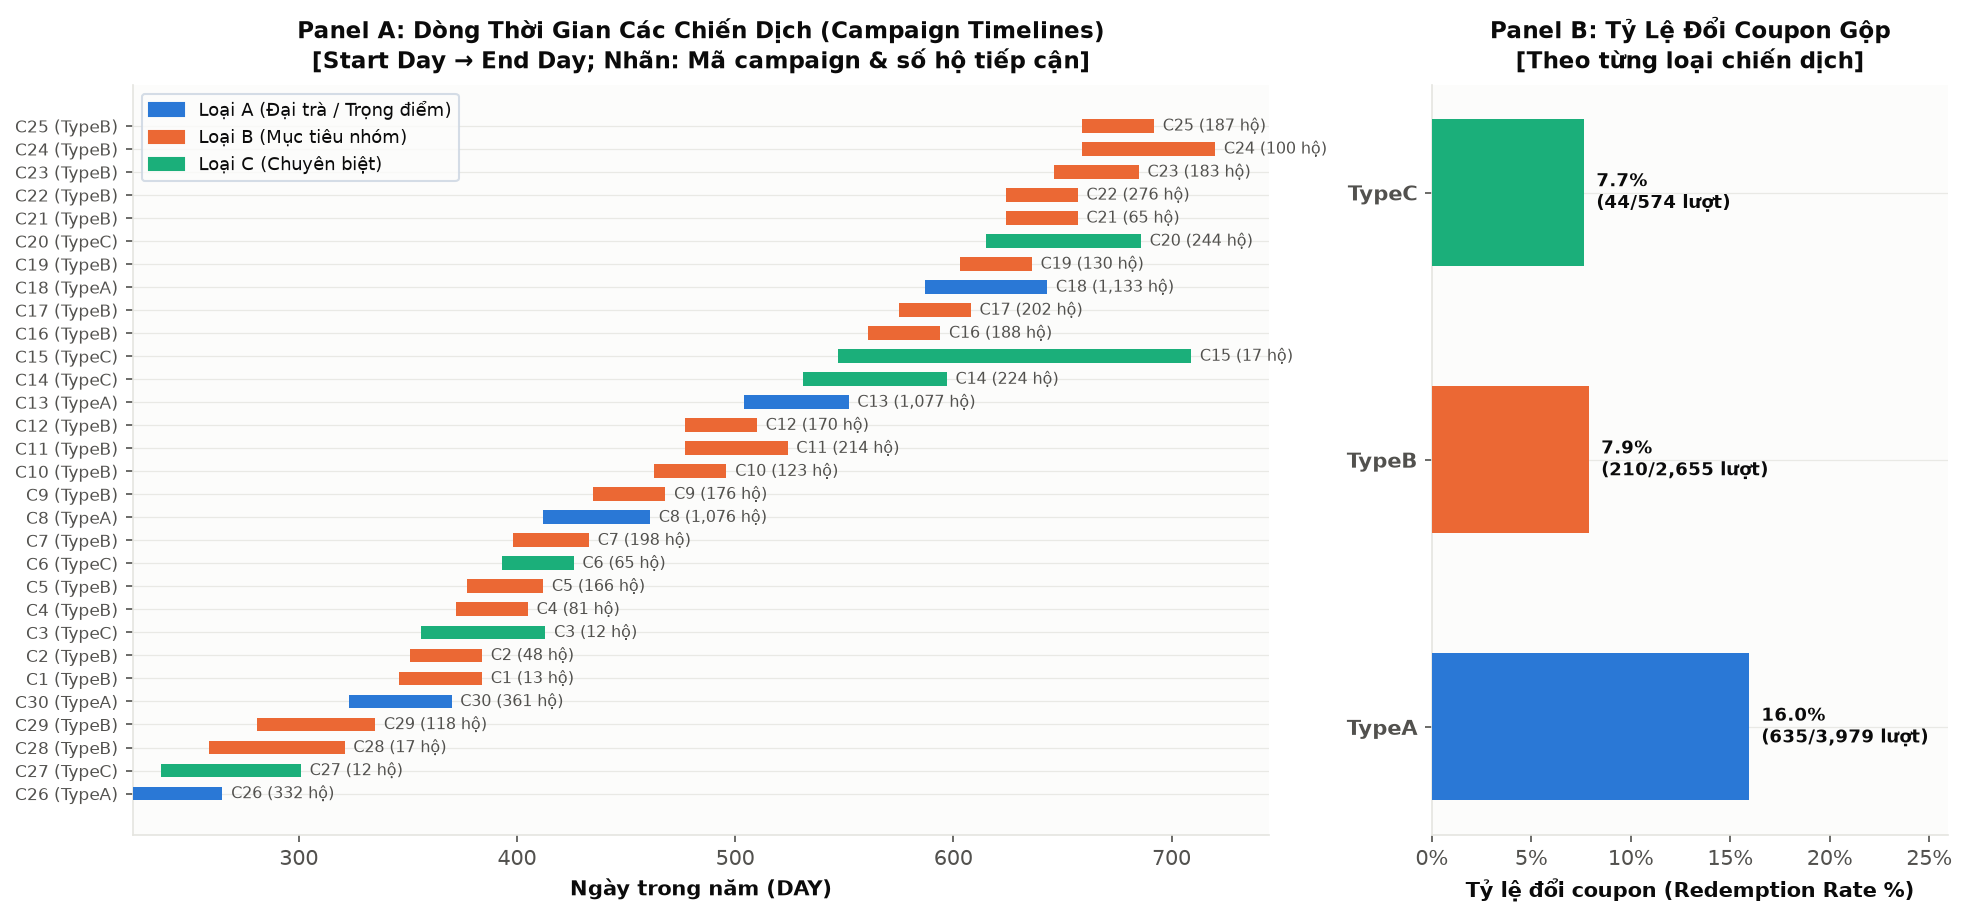

In [ ]:
display(HTML("<h4>Tổng Hợp 3 Loại Chiến Dịch Tiếp Thị (Campaign Type Summary)</h4>"))
display(type_sum)
fig_q8a = plot_campaign_overview(camp, type_sum)
fig_q8a


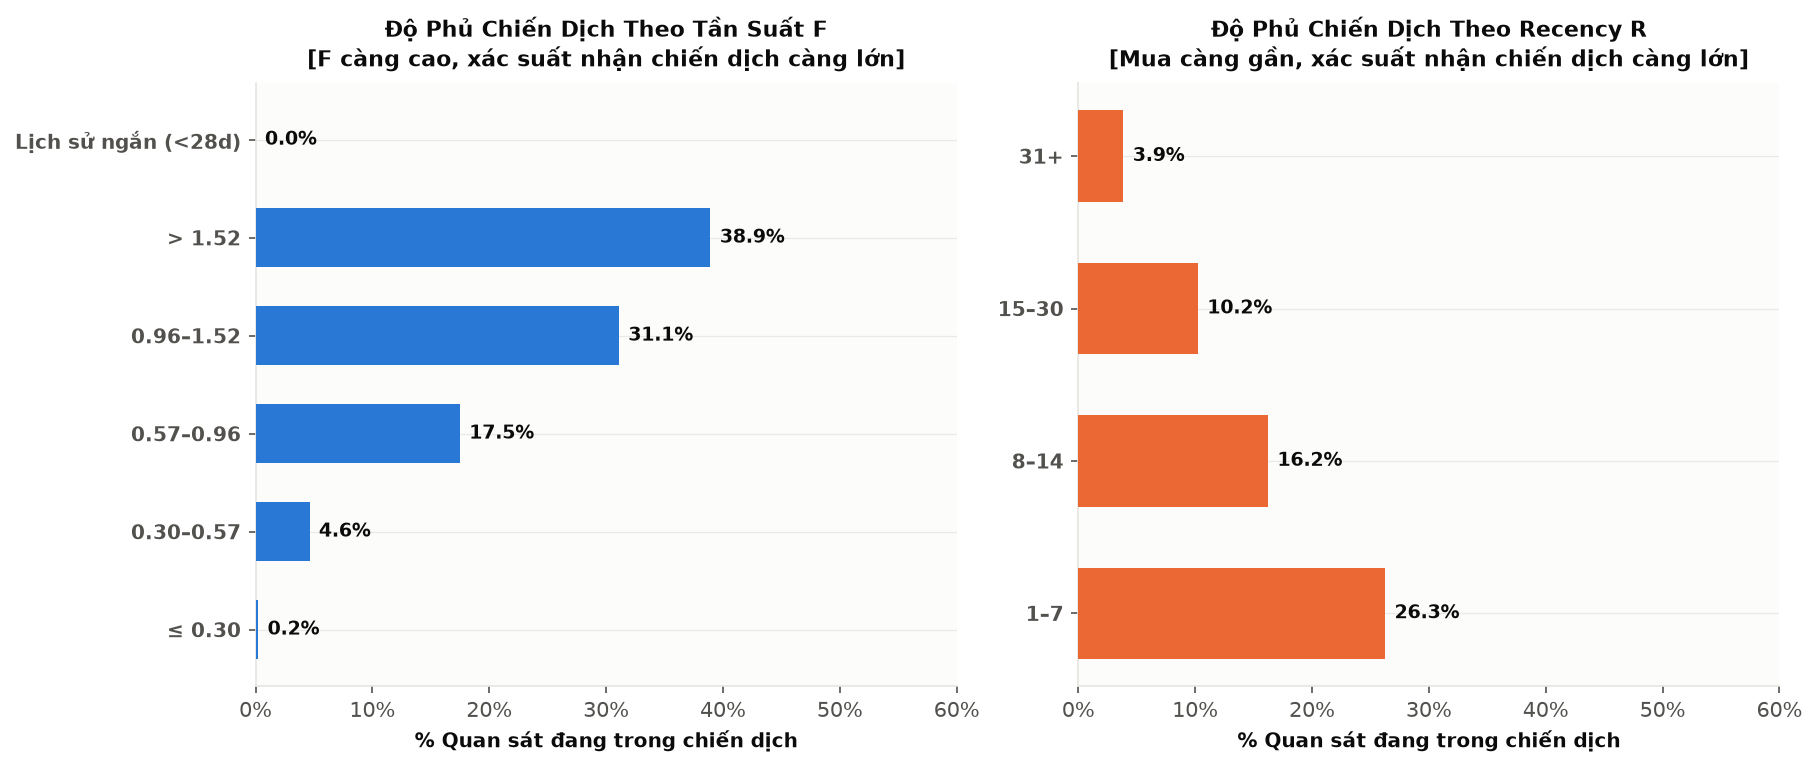

In [ ]:
cf = campaign_features(ct, cd, cr, panel)
panel = join_features(panel, cf)

reach = campaign_reach_by_rf(panel)
fig_q8b = plot_campaign_reach(reach)
fig_q8b


### Phân Tích Q8a: Bằng Chứng Độ Lệch Chọn Mẫu Của Chiến Dịch (Campaign Selection Bias)

- **Mô tả:** Tỷ lệ quan sát hộ đang trong chiến dịch tiếp thị (`in_active_campaign_c == 1`) có sự thiên lệch cực kỳ gay gắt theo tầng Tần suất $F$ và Recency $R$:
  - **Theo F:** Nhóm tần suất thấp ($F \le 0.30$) chỉ có **0.23%** quan sát được nhận chiến dịch. Trong khi đó, nhóm tần suất cao ($F > 1.52$) có tới **38.93%** quan sát đang nhận chiến dịch (tỷ lệ tiếp cận chênh lệch tới **170 lần**!).
  - **Theo R:** Nhóm mua gần đây (1–7 ngày) có **26.26%** đang nhận chiến dịch, trong khi nhóm $>31$ ngày chỉ có **3.86%**.
- **Vì sao:** Doanh nghiệp chủ động lựa chọn danh sách gửi thư trực tiếp (Direct Mailer Campaign) dựa trên danh sách khách hàng tích cực và thường xuyên nhất (RFM Targeting) để tối đa hóa tỷ lệ mở và đổi phiếu.
- **Hệ quả phân tích:** **Mọi so sánh thô giữa "trong chiến dịch" và "ngoài chiến dịch" đều bị bóp méo nghiêm trọng bởi Selection Bias.** Nhóm nhận chiến dịch có tỷ lệ quay lại cao không phải vì chiến dịch làm họ quay lại, mà vì họ vốn dĩ là những người ghé siêu thị thường xuyên nhất.
- **Insight:** Bắt buộc phải kiểm soát bằng mô hình kỳ vọng $R \times F$ trước khi đưa ra bất kỳ kết luận nào về hiệu ứng chiến dịch.
- **Hành động:** Sử dụng kỳ vọng $R \times F$ để bóc tách thặng dư thực sự của chiến dịch ở bước tiếp theo.


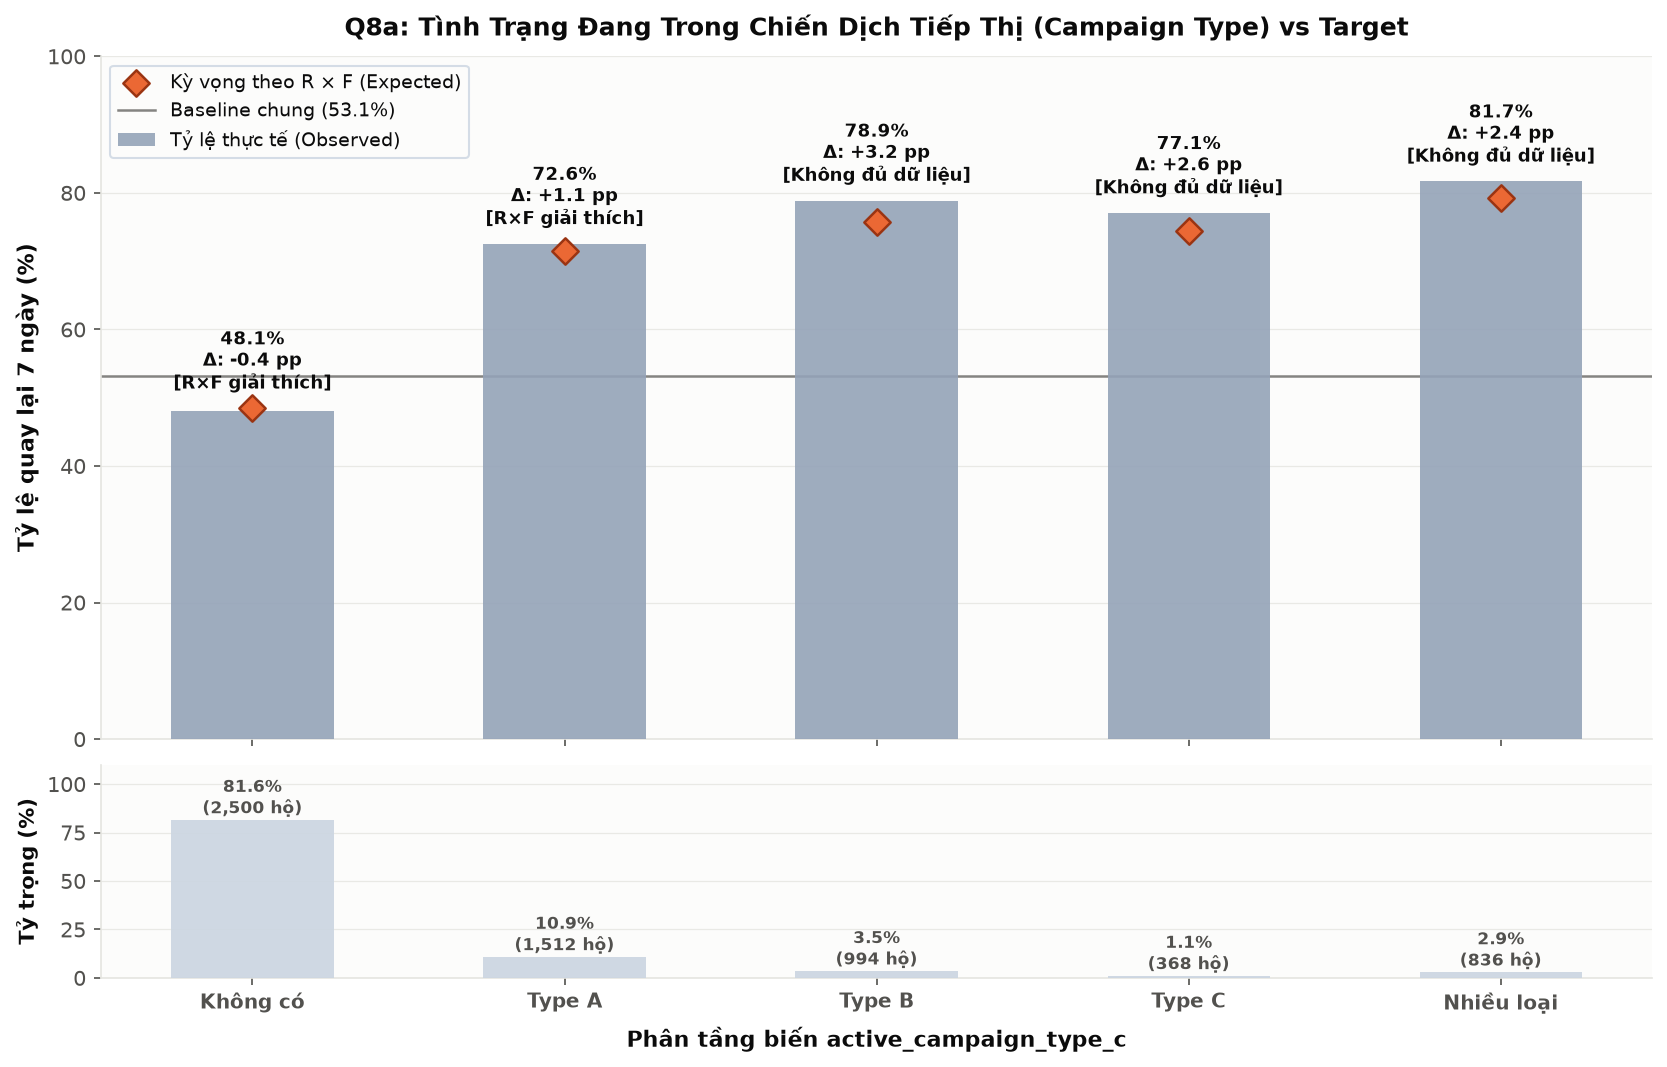

Loại chiến dịch đang nhận,Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Không có,164931,2500,0.815533,0.480534,0.484617,-0.408321,0.580247,Đã được R × F giải thích
Type A,22064,1512,0.109100,0.725526,0.714240,1.128589,0.781250,Đã được R × F giải thích
Type B,7098,994,0.035097,0.788814,0.757244,3.156978,0.690476,Không đủ dữ liệu
Type C,2228,368,0.011017,0.770646,0.744223,2.642299,0.727273,Không đủ dữ liệu
Nhiều loại,5916,836,0.029253,0.816937,0.792580,2.435715,0.818182,Không đủ dữ liệu


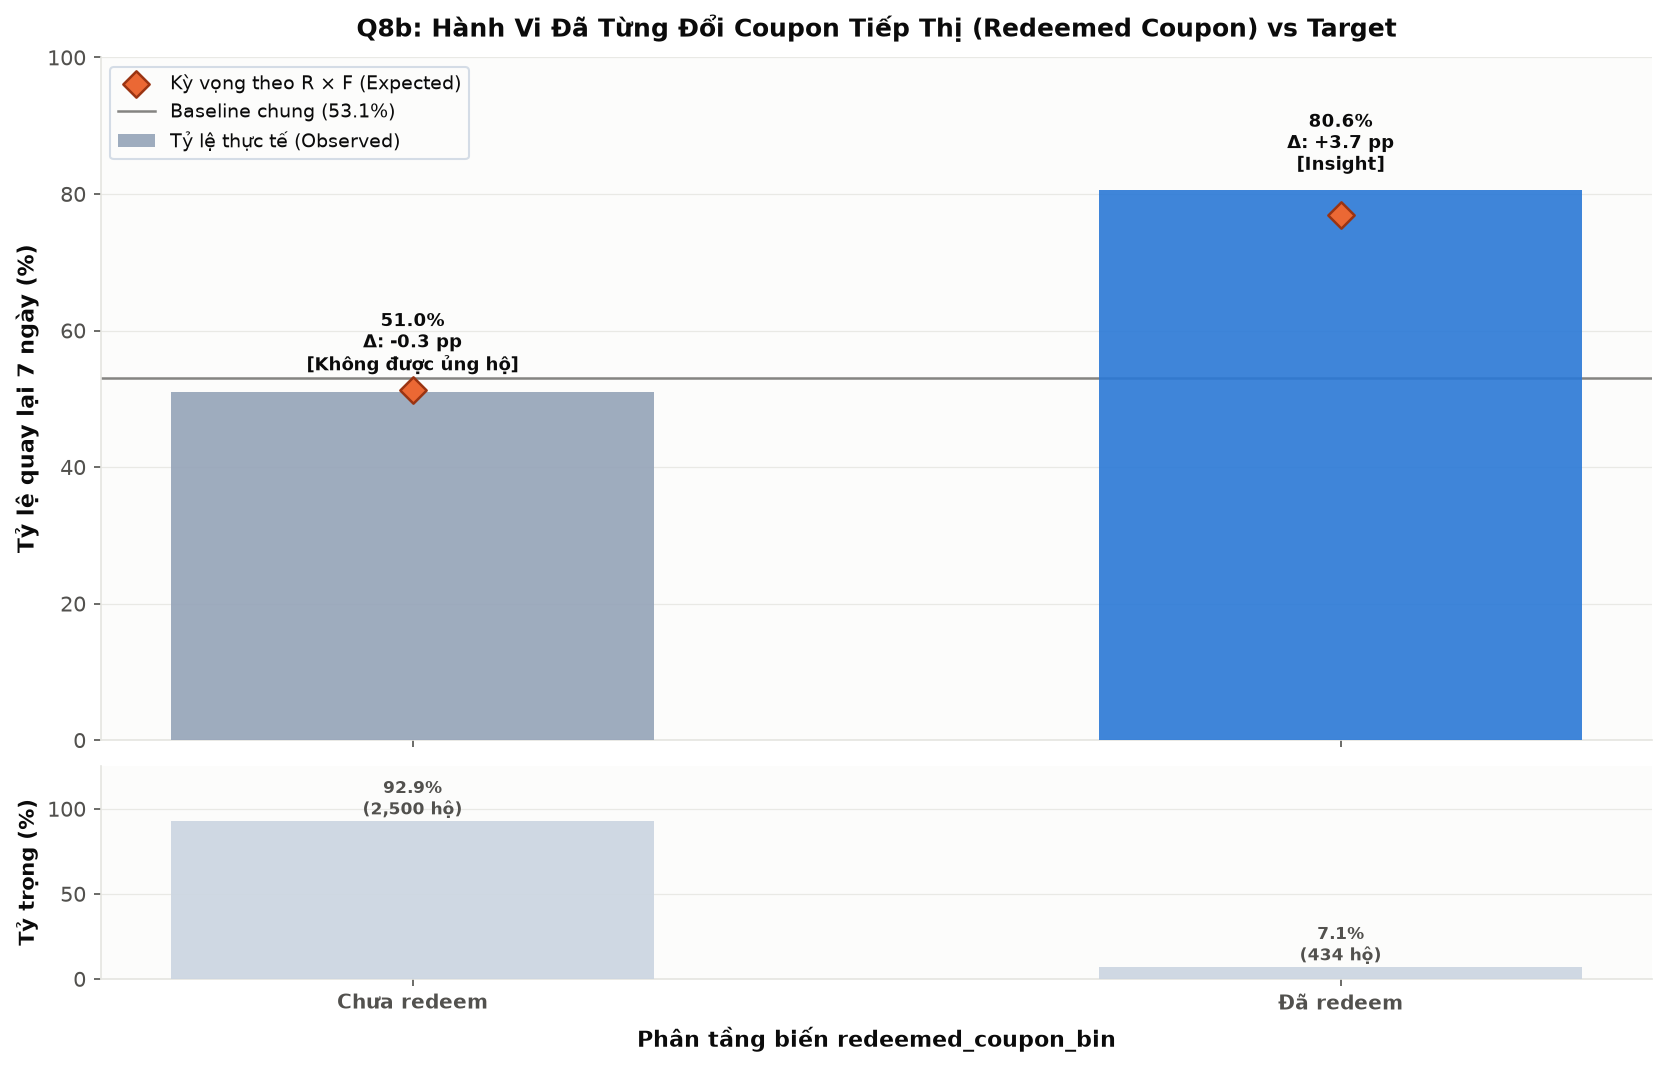

Tình trạng đổi coupon,Số dòng (n_rows),Số hộ (n_hh),Tỷ trọng dòng,Tỷ lệ thực tế,Tỷ lệ kỳ vọng R×F,Chênh lệch (pp),Đồng nhất cắt (%),Kết luận tự động
Chưa redeem,187897,2500,0.929093,0.510104,0.512906,-0.280194,0.580247,Không được ủng hộ
Đã redeem,14340,434,0.070907,0.806485,0.769589,3.689614,0.909091,Insight


In [ ]:
q8_type_excess = add_verdicts(excess_over_rf(panel, "active_campaign_type_c"))
fig_q8c = plot_rate_and_excess(q8_type_excess, title="Q8a: Tình Trạng Đang Trong Chiến Dịch Tiếp Thị (Campaign Type) vs Target")
fig_q8c

panel["redeemed_coupon_bin"] = panel["redeemed_coupon_c"].map({0: "Chưa redeem", 1: "Đã redeem"}).astype("category")
q8_red_excess = add_verdicts(excess_over_rf(panel, "redeemed_coupon_bin"))
fig_q8d = plot_rate_and_excess(q8_red_excess, title="Q8b: Hành Vi Đã Từng Đổi Coupon Tiếp Thị (Redeemed Coupon) vs Target")
fig_q8d


### Phân Tích Q8b: Hiệu Ứng Chiến Dịch & Hành Vi Đổi Coupon (Kiểm Soát R × F)

- **Mô tả Q8a (Loại chiến dịch đang nhận):** Nhìn thô, hộ đang nhận Campaign Loại A có tỷ lệ quay lại là **72.55%** so với **48.05%** của hộ không có campaign (+24.50 pp). Tuy nhiên, kỳ vọng $R \times F$ của nhóm nhận Loại A cũng lên tới **71.42%**. Thặng dư thuần túy chỉ còn **+1.13 pp**. Verdict: **"Đã được R × F giải thích"**.
- **Mô tả Q8b (Đã từng đổi coupon tiếp thị):** Nhóm đã từng đổi coupon chiến dịch (`redeemed_coupon_c == 1`, chiếm 7.09% số dòng) có tỷ lệ quay lại thực tế là **80.65%**, vượt kỳ vọng $R \times F$ (76.96%) một khoảng **+3.69 pp** (độ đồng nhất dấu cắt đạt **90.9%**). Verdict: **"Insight"**.
- **Cảnh báo cốt lõi:** **Kể cả khi biến `redeemed_coupon_c` đạt verdict Insight, đây hoàn toàn KHÔNG PHẢI là tác động nhân quả của campaign.** Đây là chỉ báo thể hiện mức độ tương tác và gắn kết cực cao (High Engagement Proxy) của phân khúc 7% khách hàng trung thành nhất, những người luôn mang coupon đi siêu thị mỗi khi nhận được thư.
- **Insight:** Việc "đang trong chiến dịch" không cung cấp thêm thông tin ngoài $R \times F$. Hành vi "đã đổi coupon" phản ánh phẩm chất trung thành của nhóm khách hàng cốt lõi nhưng độ phủ thấp (~7%).
- **Hành động:** **Không đưa `in_active_campaign_c` vào feature chính**. Có thể giữ `redeemed_coupon_c` cho phân cụm nhóm khách hàng tích cực đổi thưởng, nhưng không xem đây là lực đẩy nhân quả.


---
### Bảng Tổng Kết Phần 3: Promotion & Campaign (Đặc Tả & Quyết Định Mô Hình)

| Nhóm Phân Tích | Tên Feature | Kết luận tự động (Verdict) | Khoảng Excess ngoài $R \times F$ | Quyết định từ EDA |
| :--- | :--- | :--- | :---: | :--- |
| **Q7a Promo Share** | `promo_spend_share_c` | Đã được R × F giải thích | $-0.68$ đến $+0.73\text{ pp}$ | **Không đưa vào feature chính**. Giảm giá không phân biệt được ai sẽ quay lại. |
| **Q7b Discount Depth**| `discount_depth_c` | Đã được R × F giải thích | $-0.44$ đến $+0.43\text{ pp}$ | **Không đưa vào feature chính**. |
| **Q7c Coupon Usage** | `used_coupon_c` | Đã được R × F giải thích | $-1.30$ đến $+1.07\text{ pp}$ | **Không đưa vào feature chính**. |
| **Q8a Campaign Active**| `in_active_campaign_c` | Đã được R × F giải thích | $+1.13\text{ pp}$ (Type A) | **Không đưa vào feature chính**. Bị bóp méo bởi Selection Bias (target hộ F cao). |
| **Q8b Coupon Redeem** | `redeemed_coupon_c` | Insight (Proxy gắn kết) | **+3.69 pp** (Đồng nhất 90.9%) | **Không đưa vào feature chính** (Độ phủ thấp ~7%, không phải nhân quả). |

> [!IMPORTANT]
> **Business Insight cốt lõi từ Phần 3:**
> 1. **Khuyến mãi là điều kiện thị trường, không phải động lực quay lại:** Gần một nửa doanh số siêu thị (46.75%) được bán với giá giảm, nhưng mức độ săn đón giảm giá không quyết định việc khách có quay lại tuần sau hay không.
> 2. **Selection Bias trong Marketing Campaign:** Doanh nghiệp gửi campaign Type A tập trung gần như toàn bộ vào khách hàng đã có tần suất viếng thăm cao ($F > 1.52$ có tỷ lệ nhận chiến dịch cao gấp 170 lần nhóm $F \le 0.30$). Vì vậy, tỷ lệ quay lại cao của nhóm nhận campaign là do $R \times F$ quy định, không phải do chiến dịch tạo ra.


---
## Phần 4: Giỏ Hàng (Basket Analytics: Q4a Overview, Q4b Basket Size vs Target, Q4c Pantry Loading)
## Phần 5: Tính Ổn Định Thời Gian & Động Thái Chu Kỳ (Temporal Analytics: Q5a Stability, Q5b Trend, Q5c Lapse)

Mục tiêu chính:
1. **Q4a (Mô tả giỏ hàng)**: Phân bố quy mô giỏ hàng (sản phẩm/giỏ), cấu trúc đóng góp doanh thu giữa giỏ nhỏ (quick trip) và giỏ lớn (stock-up).
2. **Q4b (Quy mô giỏ vs Label)**: Kiểm tra liệu khách mua giỏ lớn có tỷ lệ quay lại cao hơn không, sau khi kiểm soát tần suất $R \times F$.
3. **Q4c (Pantry-loading)**: Chuyến mua sắm lớn bất thường ngay trước cutoff có làm khách trì hoãn quay lại trong 7 ngày tới hay không?
4. **Q5a (Tính ổn định thời gian & Cutoff)**: Kiểm tra số hộ hoạt động theo tuần, kiểm chứng tính ổn định của tỷ lệ nhãn qua 81 cutoff và phát hiện cutoff bất thường (|robust z| > 3.5).
5. **Q5b (Xu hướng chu kỳ IPT Trend Ratio)**: Tốc độ mua sắm gần đây (3 gap gần nhất so với lịch sử) có bổ sung thông tin độc lập ngoài $R \times F$ hay không?
6. **Q5c (Mức độ trễ hạn Lapse Ratio)**: Chuẩn hóa khoảng cách ngày mua theo nhịp sinh học cá nhân (`recency / median_ipt`) giúp phân đoạn khách hàng như thế nào?


In [ ]:
from propensity.viz.style import set_style, save_fig, plot_rate_and_excess
from propensity.eda.propensity_rates import FindingThresholds, add_verdicts
set_style()

thr_2pct = FindingThresholds(min_row_share=0.02)
print("Áp dụng phong cách trực quan Part 1 (palette sắc nét, vạch kỳ vọng R × F, không dùng 2 trục y).")
print(f"Ngưỡng phân loại kết luận: min_row_share = {thr_2pct.min_row_share:.0%}, min_effect = {thr_2pct.min_effect_pp} pp, min_same_sign = {thr_2pct.min_same_sign:.0%}")


Áp dụng phong cách trực quan Part 1 (palette sắc nét, vạch kỳ vọng R × F, không dùng 2 trục y).
Ngưỡng phân loại kết luận: min_row_share = 2%, min_effect = 3.0 pp, min_same_sign = 80%


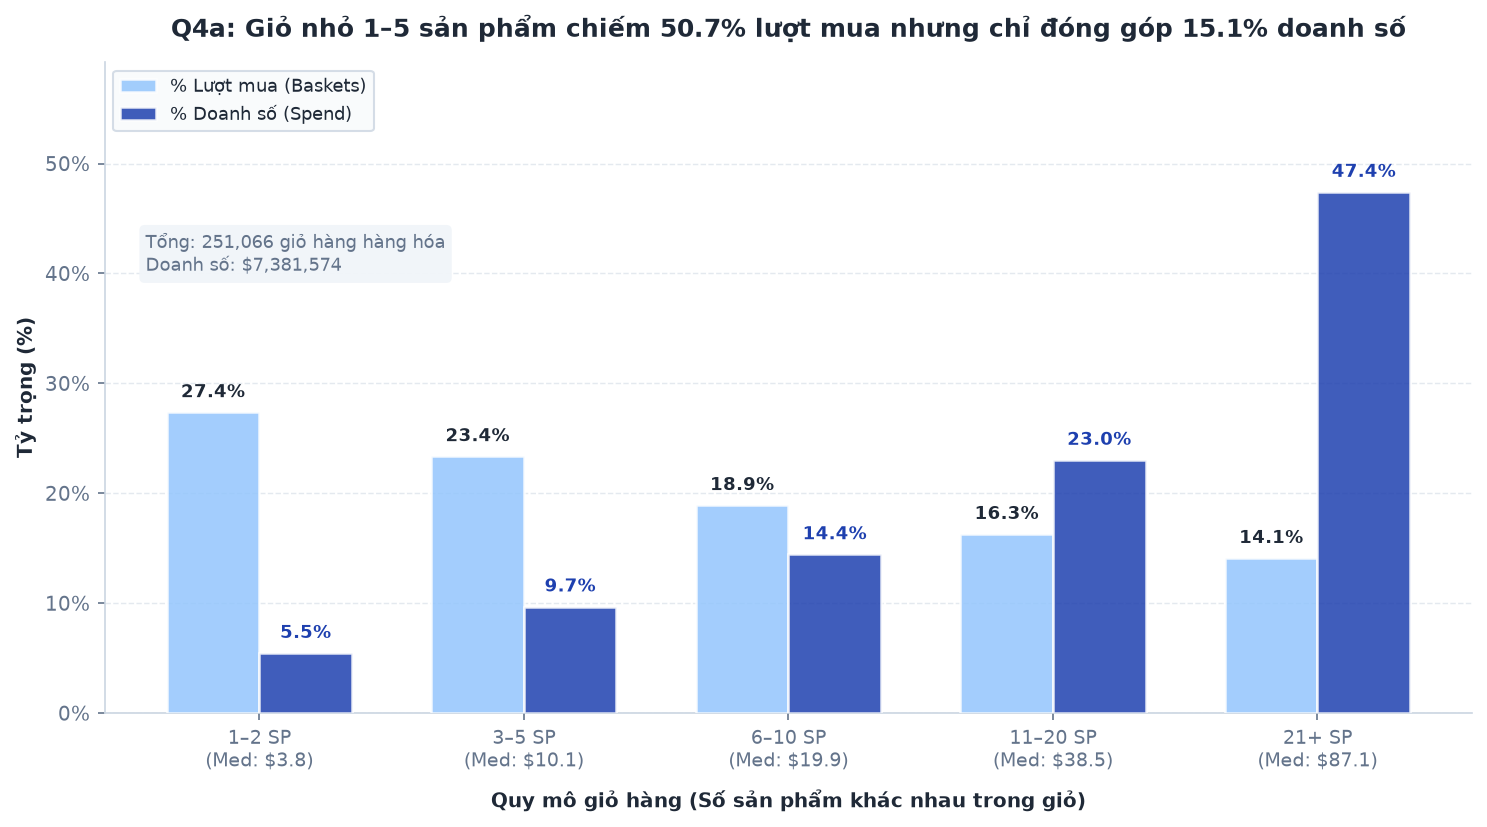

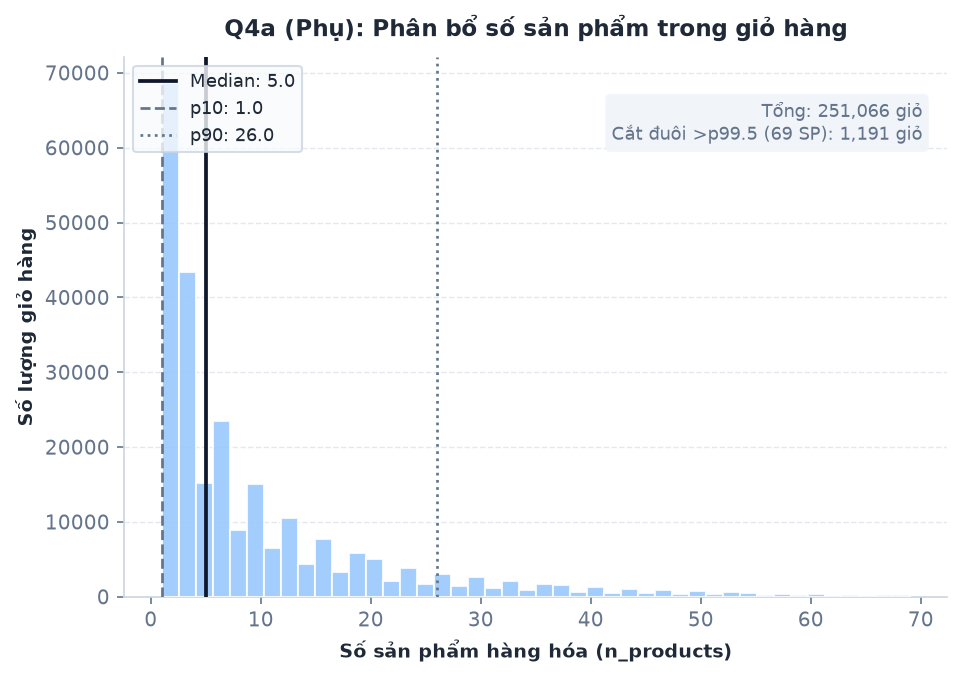

band,n_baskets,pct_baskets,total_spend,pct_spend,median_spend
1–2,68696,0.273617,402453.21,0.054521,3.79
3–5,58644,0.233580,714806.72,0.096837,10.06
6–10,47475,0.189094,1065565.56,0.144355,19.86
11–20,40867,0.162774,1699552.39,0.230243,38.52
21+,35384,0.140935,3499196.47,0.474045,87.09


In [ ]:
from propensity.features.basket import basket_table, basket_size_bands
from propensity.eda.basket_temporal_plots import plot_basket_size_bands, plot_products_per_basket_hist

baskets = basket_table(lines)
bands_df = basket_size_bands(baskets)

fig_q4a_bands = plot_basket_size_bands(bands_df)
save_fig(fig_q4a_bands, "part4", "customer_q4a_basket_bands.png")
display(fig_q4a_bands)

fig_q4a_hist = plot_products_per_basket_hist(baskets)
save_fig(fig_q4a_hist, "part4", "customer_q4a_basket_hist.png")
display(fig_q4a_hist)

bands_df


### Phân Tích Chi Tiết Q4a: Tổng Quan Quy Mô Giỏ Hàng (Basket Size Distribution)

1. **Mô tả (Description)**:
   - Tổng cộng có **251,066** lượt mua hàng hóa (merchandise baskets) với tổng chi tiêu **$7,381,574**.
   - Giỏ 1–2 sản phẩm chiếm **27.36%** lượt mua (68,696 giỏ) nhưng chỉ đóng góp **5.45%** doanh số ($402,453), giá trị trung vị chỉ $3.79/giỏ.
   - Giỏ 3–5 sản phẩm chiếm **23.36%** lượt mua (58,644 giỏ), đóng góp **9.68%** doanh số ($714,807), trung vị $10.06/giỏ.
   - Cộng dồn, nhóm giỏ nhỏ (1–5 sản phẩm) chiếm hơn một nửa tổng lượt mua (**50.72%**), nhưng chỉ đem về **15.14%** tổng doanh thu bán lẻ.
   - Ngược lại, nhóm giỏ lớn (21+ sản phẩm) chỉ chiếm **14.09%** số giỏ (35,384 giỏ) nhưng đóng góp tới **47.40%** tổng doanh số ($3,499,196), trung vị lên tới $87.09/giỏ.
2. **Vì sao (Why)**:
   - Bán lẻ siêu thị phục vụ hai sứ mệnh mua sắm hoàn toàn khác biệt:
     - *Quick Trip / Fill-in Trip*: Khách ghé mua nhanh vài món đồ tiện lợi (sữa chua, bánh mì, nước giải khát), giá trị nhỏ nhưng ghé thường xuyên.
     - *Pantry Restocking / Stock-up Trip*: Chuyến đi chợ tuần của hộ gia đình để làm đầy tủ lạnh, giỏ hàng lớn với giá trị chi tiêu áp đảo.
3. **Liên quan đến label (Relation to label)**:
   - Giỏ hàng nhỏ xuất hiện rất nhiều lần trong lịch sử mua sắm của khách hàng thường xuyên. Nếu chỉ nhìn số lượt mua mà không hiểu quy mô giỏ, ta dễ nhầm lẫn tần suất ghé thăm với giá trị kinh tế.
4. **Insight**:
   - **Business Insight**: Không thể đánh đồng các lượt mua. Doanh thu siêu thị phụ thuộc 47.4% vào các giỏ hàng 21+ món. Chiến lược tiếp thị tại quầy thu ngân (cross-sell/upsell) giúp nâng giỏ hàng từ 3–5 món lên 6–10 món là đòn bẩy tăng trưởng doanh số cực lớn.
5. **Hành động (Action)**:
   - Sử dụng quy mô giỏ hàng trung bình để phân biệt thói quen mua sắm (quick shopper vs stock-up shopper) trong phần phân đoạn khách hàng.

> **Card Biến Q4a: Quy mô giỏ hàng (Basket Size Bands)**
> - Tổng số giỏ hàng hóa: 251,066 giỏ | Tổng doanh thu: $7.38M
> - Giỏ nhỏ (1–5 SP): 50.72% số giỏ | 15.14% doanh thu (Median: $3.79 – $10.06)
> - Giỏ lớn (21+ SP): 14.09% số giỏ | 47.40% doanh thu (Median: $87.09)
> - Phân loại: Business Insight (Phân hóa sâu sắc giữa Quick Trip và Stock-up Trip)


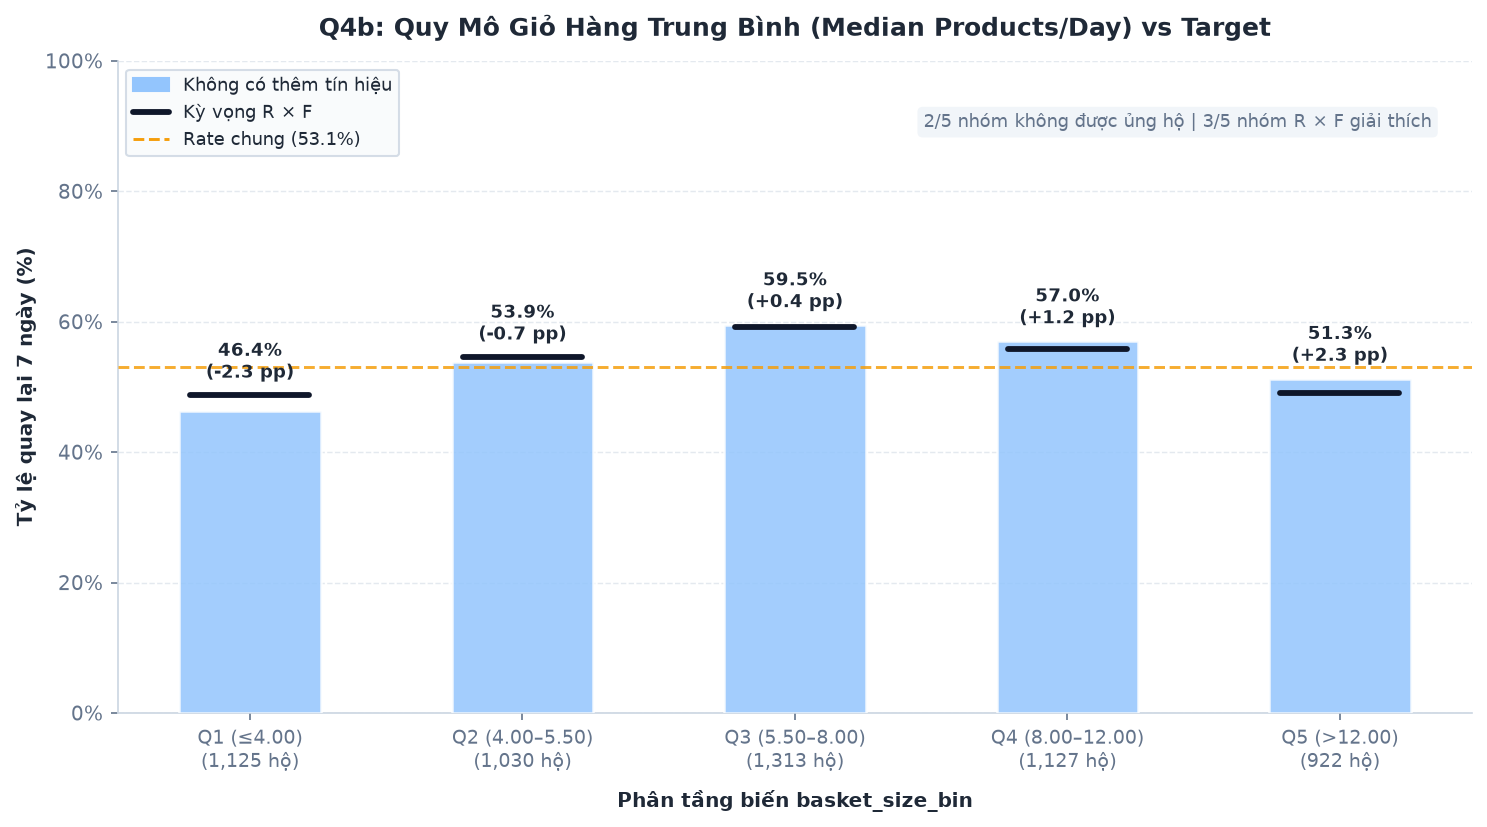

basket_size_bin,n_rows,n_households,observed,expected,excess_pp,same_sign_share,verdict,verdict_reason
Q1 (≤4.00),55984,1125,0.463543,0.486979,-2.343631,0.925926,Đã được R × F giải thích,Chênh lệch thô -6.76 pp nhưng sau R × F chỉ còn -2.34 pp (< 3.0 pp)
Q2 (4.00–5.50),25087,1030,0.538646,0.545474,-0.682813,0.580247,Không được ủng hộ,Chênh lệch sau R × F (-0.68 pp) nhỏ hơn ngưỡng tối thiểu (3.0 pp)
Q3 (5.50–8.00),45278,1313,0.595101,0.591276,0.382491,0.567901,Đã được R × F giải thích,Chênh lệch thô +6.40 pp nhưng sau R × F chỉ còn +0.38 pp (< 3.0 pp)
Q4 (8.00–12.00),36189,1127,0.570450,0.558864,1.158579,0.703704,Đã được R × F giải thích,Chênh lệch thô +3.93 pp nhưng sau R × F chỉ còn +1.16 pp (< 3.0 pp)
Q5 (>12.00),39699,922,0.512834,0.490327,2.250705,0.814815,Không được ủng hộ,Chênh lệch sau R × F (+2.25 pp) nhỏ hơn ngưỡng tối thiểu (3.0 pp)


In [ ]:
from propensity.features.basket import day_basket_table, basket_features
from propensity.eda.propensity_rates import quantile_bin, excess_over_rf, add_verdicts, join_features

day_tbl = day_basket_table(baskets, lines=lines)
bf = basket_features(day_tbl, cutoffs)
panel = join_features(panel, bf)

panel["basket_size_bin"] = quantile_bin(panel["median_products_per_day_c"], 5, prefix="Q")
q4b_excess = add_verdicts(excess_over_rf(panel, "basket_size_bin"))

fig_q4b = plot_rate_and_excess(q4b_excess, title="Q4b: Quy Mô Giỏ Hàng Trung Bình (Median Products/Day) vs Target")
save_fig(fig_q4b, "part4", "customer_q4b_basket_size_excess.png")
display(fig_q4b)

q4b_excess[["basket_size_bin", "n_rows", "n_households", "observed", "expected", "excess_pp", "same_sign_share", "verdict", "verdict_reason"]]


### Phân Tích Chi Tiết Q4b: Quy Mô Giỏ Hàng Trung Bình vs Nhãn Quay Lại

1. **Mô tả (Description)**:
   - Tỷ lệ quay lại thô tăng từ **46.35%** ở Q1 (≤4.00 SP/ngày) lên **59.51%** ở Q3 (5.50–8.00 SP/ngày), rồi giảm xuống **51.28%** ở Q5 (>12.00 SP/ngày) (hình chữ U ngược).
   - Tuy nhiên, tỷ lệ kỳ vọng theo $R \times F$ cũng có hình thái tương ứng: 48.70% (Q1), 59.13% (Q3) và 49.03% (Q5).
   - Chênh lệch thuần túy sau khi kiểm soát $R \times F$ (excess_pp) dao động rất hẹp trong khoảng **[-2.34, +2.25] pp**, hoàn toàn nằm dưới ngưỡng ý nghĩa tối thiểu (3.0 pp).
   - Tỷ lệ cutoff cùng dấu chỉ đạt 56.8% – 70.4% ở các nhóm giữa.
2. **Vì sao (Why)**:
   - Các hộ gia đình mua giỏ lớn (Q5) thường là nhóm mua sắm tích trữ (stock-up) với chu kỳ mua thưa hơn (nhịp IPT dài hơn, ví dụ 10–14 ngày), do đó xác suất rơi vào cửa sổ 7 ngày tự nhiên thấp hơn.
   - Ngược lại, nhóm có giỏ vừa (Q3) là nhóm khách hàng trung thành, ghé siêu thị đều đặn mỗi tuần. Toàn bộ hiệu ứng này đã được $R \times F$ mô tả trọn vẹn.
3. **Liên quan đến label (Relation to label)**:
   - Quy mô giỏ hàng trung bình không mang lại năng lực phân tách độc lập đối với nhãn quay lại 7 ngày sau khi đã biết Recency và Frequency.
4. **Insight**:
   - **Hypothesis Not Supported / Confounded**: Bác bỏ giả thuyết cho rằng khách mua giỏ lớn có động lực quay lại cao hơn. Tần suất quay lại phụ thuộc vào nhịp điệu sinh hoạt gia đình, không phụ thuộc vào độ đầy của giỏ hàng trung bình.
5. **Hành động (Action)**:
   - Không đưa `median_products_per_day_c` vào nhóm feature chính của mô hình dự báo propensity 7 ngày. Giữ lại làm biến tương tác hoặc phân cụm giá trị khách hàng sau này.

> **Card Biến Q4b: Quy mô giỏ hàng trung bình (`median_products_per_day_c`)**
> - Độ phủ: 100% dòng quan sát hợp lệ (202,237 dòng)
> - Tỷ lệ quay lại thô: 46.35% (Q1) → 59.51% (Q3) → 51.28% (Q5)
> - Chênh lệch sau khi kiểm soát $R \times F$: −2.34 pp đến +2.25 pp (dưới ngưỡng 3.0 pp)
> - Kết luận tự động: Đã được R × F giải thích / Không được ủng hộ
> - Quyết định: Loại khỏi feature chính của mô hình.


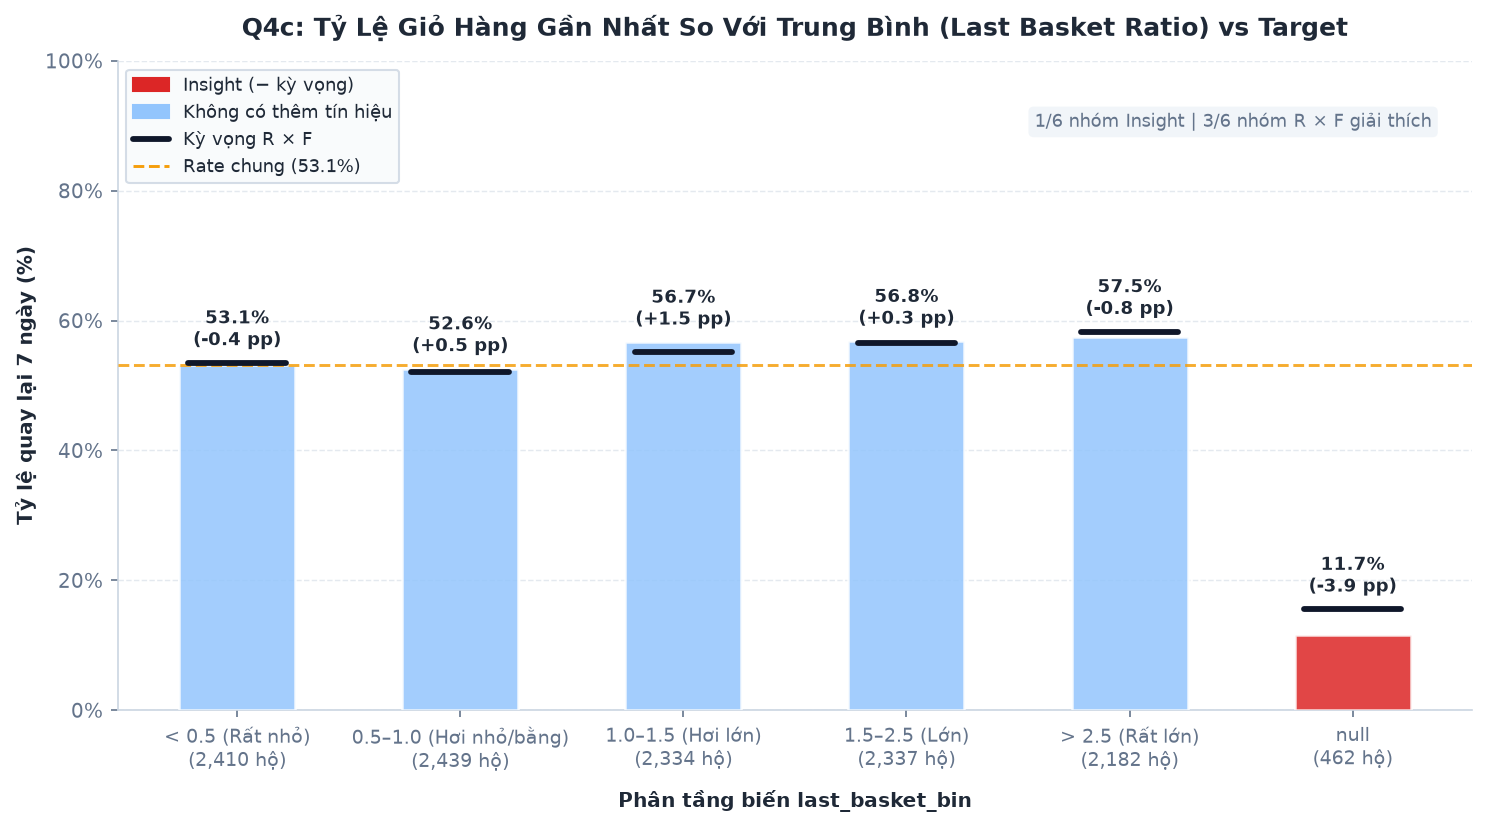

=== Bảng Q4c: Last Basket Ratio ===


last_basket_bin,n_rows,n_households,observed,expected,excess_pp,same_sign_share,verdict
< 0.5 (Rất nhỏ),51803,2410,0.531359,0.534924,-0.356443,0.580247,Không được ủng hộ
0.5–1.0 (Hơi nhỏ/bằng),51845,2439,0.525721,0.520936,0.478505,0.592593,Không được ủng hộ
1.0–1.5 (Hơi lớn),28251,2334,0.566670,0.551758,1.491215,0.703704,Đã được R × F giải thích
1.5–2.5 (Lớn),30809,2337,0.567854,0.565002,0.285107,0.567901,Đã được R × F giải thích
> 2.5 (Rất lớn),31702,2182,0.574538,0.582921,-0.838322,0.617284,Đã được R × F giải thích
null,7827,462,0.116520,0.155382,-3.886236,0.925926,Insight


=== Bảng Q4c: Last Spend Ratio (Đối chiếu) ===


last_spend_bin,n_rows,n_households,observed,expected,excess_pp,same_sign_share,verdict
< 0.5 (Rất nhỏ),47561,2399,0.537625,0.539202,-0.157638,0.580247,Không được ủng hộ
0.5–1.0 (Hơi nhỏ/bằng),48322,2436,0.524895,0.518831,0.606442,0.666667,Không được ủng hộ
1.0–1.5 (Hơi lớn),33267,2376,0.553522,0.543647,0.987487,0.641975,Không được ủng hộ
1.5–2.5 (Lớn),32214,2345,0.572391,0.566236,0.615496,0.580247,Đã được R × F giải thích
> 2.5 (Rất lớn),33046,2202,0.566271,0.579527,-1.325619,0.765432,Đã được R × F giải thích
null,7827,462,0.116520,0.155382,-3.886236,0.925926,Insight


In [ ]:
# Phân tầng Last Basket Ratio (chuyến mua gần nhất so với trung vị cá nhân)
panel["last_basket_bin"] = pd.cut(
    panel["last_basket_ratio_c"],
    bins=[-np.inf, 0.5, 1.0, 1.5, 2.5, np.inf],
    labels=["< 0.5 (Rất nhỏ)", "0.5–1.0 (Hơi nhỏ/bằng)", "1.0–1.5 (Hơi lớn)", "1.5–2.5 (Lớn)", "> 2.5 (Rất lớn)"],
)
q4c_excess = add_verdicts(excess_over_rf(panel, "last_basket_bin"))

fig_q4c = plot_rate_and_excess(q4c_excess, title="Q4c: Tỷ Lệ Giỏ Hàng Gần Nhất So Với Trung Bình (Last Basket Ratio) vs Target")
save_fig(fig_q4c, "part4", "customer_q4c_last_basket_ratio_excess.png")
display(fig_q4c)

# Đối chiếu với Last Spend Ratio
panel["last_spend_bin"] = pd.cut(
    panel["last_spend_ratio_c"],
    bins=[-np.inf, 0.5, 1.0, 1.5, 2.5, np.inf],
    labels=["< 0.5 (Rất nhỏ)", "0.5–1.0 (Hơi nhỏ/bằng)", "1.0–1.5 (Hơi lớn)", "1.5–2.5 (Lớn)", "> 2.5 (Rất lớn)"],
)
q4c_spend_excess = add_verdicts(excess_over_rf(panel, "last_spend_bin"))

print("=== Bảng Q4c: Last Basket Ratio ===")
display(q4c_excess[["last_basket_bin", "n_rows", "n_households", "observed", "expected", "excess_pp", "same_sign_share", "verdict"]])

print("=== Bảng Q4c: Last Spend Ratio (Đối chiếu) ===")
display(q4c_spend_excess[["last_spend_bin", "n_rows", "n_households", "observed", "expected", "excess_pp", "same_sign_share", "verdict"]])


### Phân Tích Chi Tiết Q4c: Hiện Tượng Tích Trữ (Pantry-Loading: Last Basket / Spend Ratio)

1. **Mô tả (Description)**:
   - Khách có giỏ hàng gần nhất rất lớn (>2.5 lần trung vị, 33,656 dòng quan sát) có tỷ lệ quay lại thô đạt **57.45%**, nhưng kỳ vọng theo $R \times F$ lên tới **58.29%**, dẫn tới excess âm nhẹ **−0.84 pp** (và đối với chi tiêu `last_spend_ratio_c > 2.5` là **−1.33 pp** so với kỳ vọng, cùng dấu âm ở 76.5% cutoff).
   - Ở các khoảng tỷ lệ từ 0.5 đến 2.5 lần, excess nằm trong khoảng **−0.36 pp đến +1.49 pp**, tất cả đều được giải thích bởi $R \times F$.
   - Nhóm `null` (khách có dưới 3 ngày mua lịch sử, chiếm 3.87% số dòng) có tỷ lệ quay lại rất thấp (11.65% vs kỳ vọng 15.54%, excess **−3.89 pp**, cùng dấu âm ở 92.6% cutoff -> xếp loại Insight vì phản ánh khách mới chưa thiết lập thói quen).
2. **Vì sao (Why)**:
   - Khi một hộ gia đình vừa thực hiện một chuyến mua sắm "đại tiệc" hoặc tích trữ lớn (>2.5x bình thường), tủ lạnh và kho đồ khô (pantry) đã đầy ắp. Họ cần thời gian tiêu thụ hết hàng hóa trước khi phát sinh nhu cầu mua sắm đợt tiếp theo.
   - Do đó, dù là khách hàng thân thiết (F cao), việc vừa mua một giỏ hàng khổng lồ tạo ra lực cản nhẹ đối với việc quay lại ngay trong 7 ngày tới.
3. **Liên quan đến label (Relation to label)**:
   - Hiện tượng pantry-loading gây ra độ trễ tiêu dùng (consumption lag), làm tỷ lệ quay lại thực tế thấp hơn kỳ vọng $R \times F$ từ −0.84 pp đến −1.33 pp.
4. **Insight**:
   - **Business Insight**: Không nên gửi thông điệp khuyến mãi nhắc nhở mua sắm ngay lập tức sau khi khách vừa thực hiện một đơn hàng lớn bất thường. Điều này vừa gây lãng phí chi phí marketing vừa làm phiền khách hàng. Hãy chờ đúng chu kỳ tiêu thụ tự nhiên trước khi gửi thông điệp kích hoạt.
5. **Hành động (Action)**:
   - Trong mô hình dự báo, giữ `last_basket_ratio_c` làm feature phi tuyến tính (hoặc feature cảnh báo độ trễ mua sắm).
   - Trong quy trình CRM, thiết lập quy tắc "cool-down period": hoãn gửi thông điệp đẩy doanh số trong 5–7 ngày đối với những khách hàng vừa có giỏ hàng vượt 2.5x trung vị cá nhân.

> **Card Biến Q4c: Tỷ lệ giỏ gần nhất so với trung bình (`last_basket_ratio_c`)**
> - Độ phủ: 96.13% dòng có ≥3 ngày mua (3.87% null)
> - Excess nhóm >2.5x: −0.84 pp (Last Basket) và −1.33 pp (Last Spend) so với kỳ vọng
> - Nhóm null (<3 ngày mua): 11.65% thực tế vs 15.54% kỳ vọng (Excess: −3.89 pp, Insight)
> - Kết luận tự động: Đã được R × F giải thích (các nhóm có số liệu) | Insight (nhóm thiếu lịch sử)
> - Quyết định: Dùng cho quy tắc giãn cách liên hệ CRM (Cool-down rule).


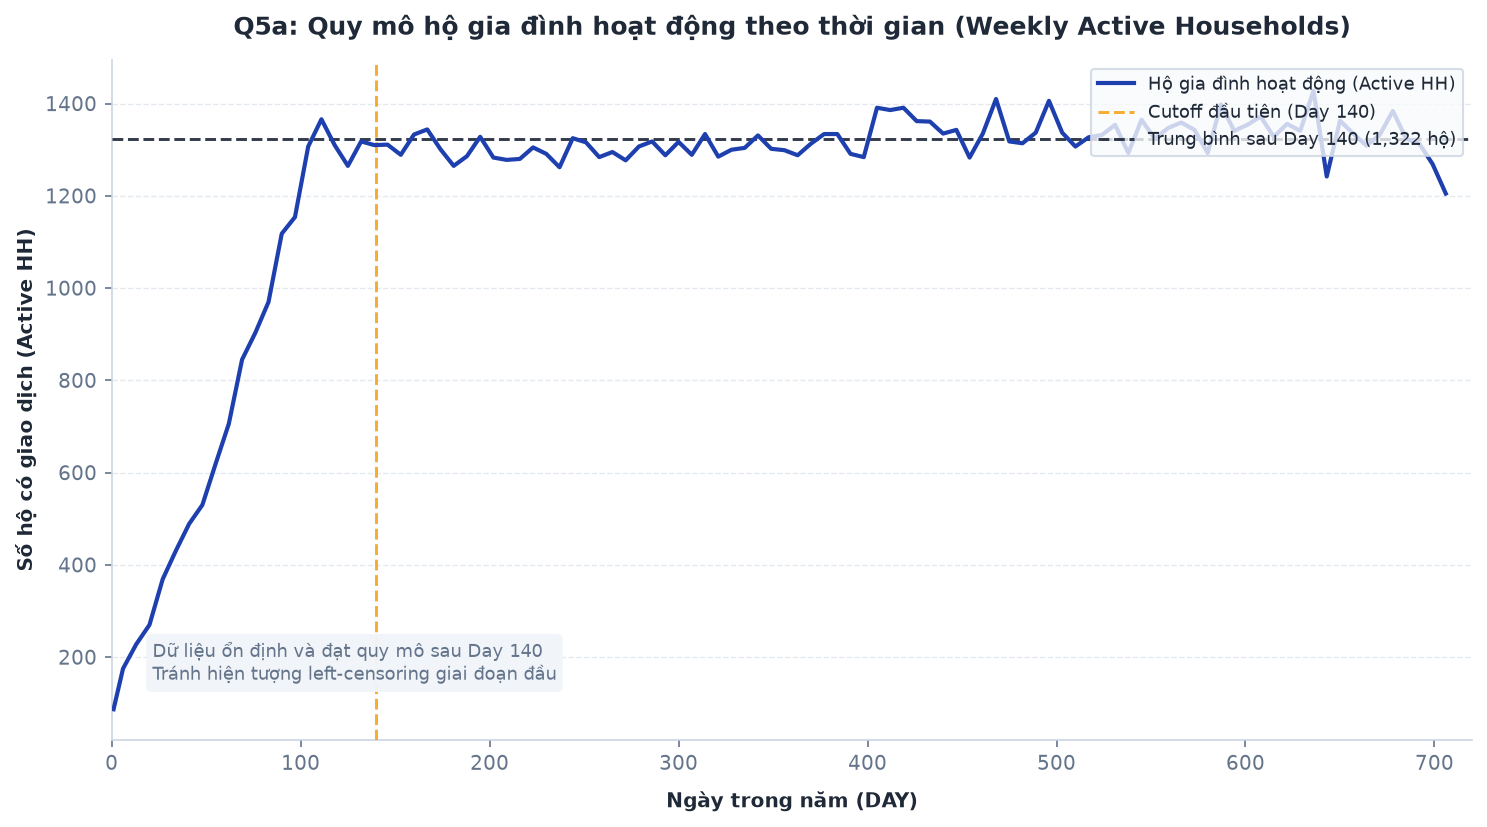

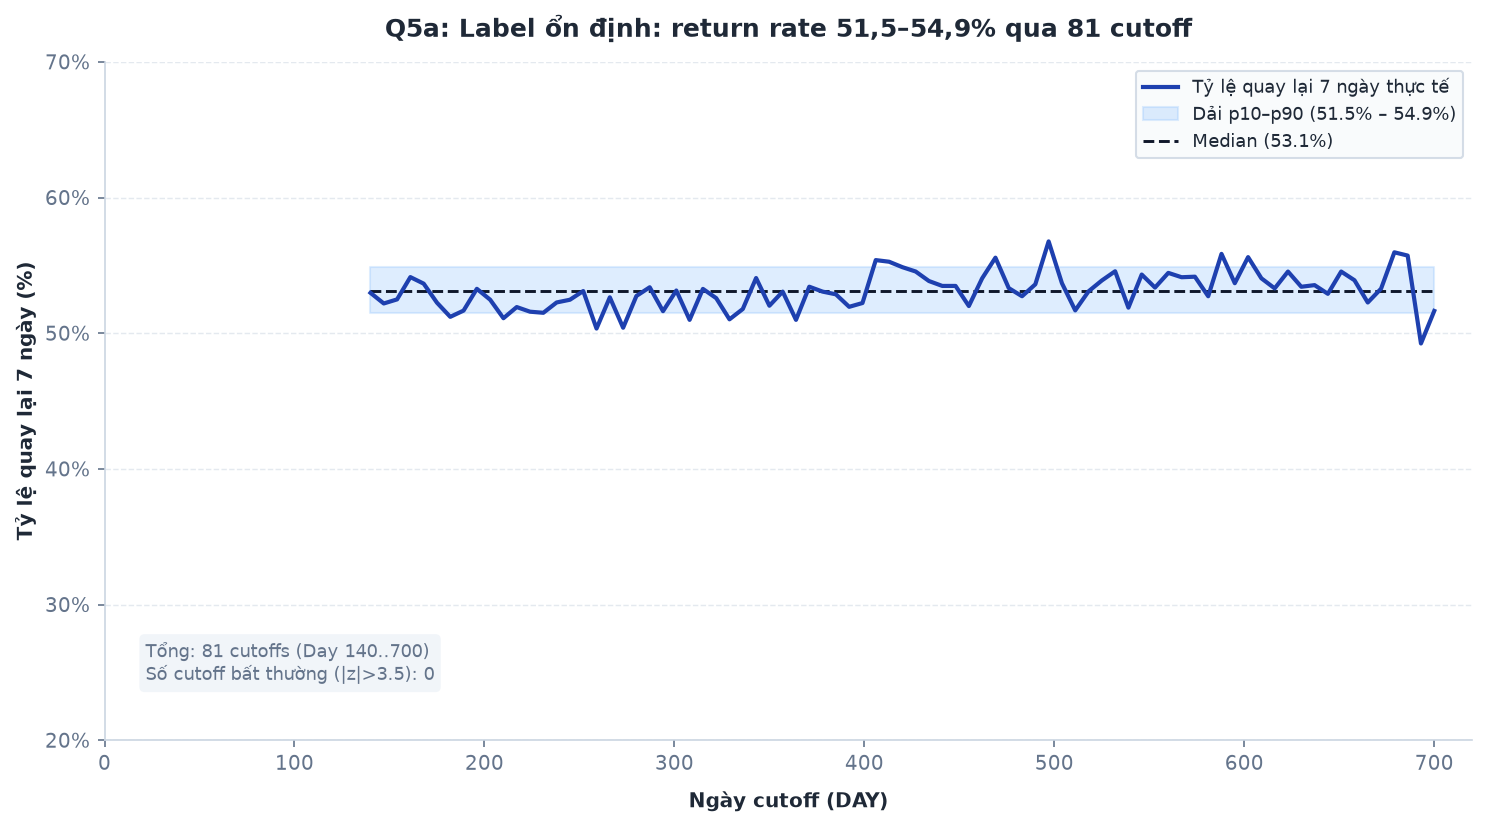

Tổng số mốc cutoff phân tích: 81 (Day 140..700)
Số cutoff bất thường (|robust z| > 3.5): 0
Xác nhận: Không có cutoff nào vượt ngưỡng bất thường 3.5 MAD. Tỷ lệ nhãn ổn định cao.


In [ ]:
from propensity.features.temporal import weekly_activity, cutoff_return_rates
from propensity.eda.basket_temporal_plots import plot_weekly_active, plot_cutoff_return_rate

weekly = weekly_activity(lines)
fig_q5a_weekly = plot_weekly_active(weekly)
save_fig(fig_q5a_weekly, "part5", "customer_q5a_weekly_active.png")
display(fig_q5a_weekly)

rates = cutoff_return_rates(panel)
fig_q5a_rates = plot_cutoff_return_rate(rates)
save_fig(fig_q5a_rates, "part5", "customer_q5a_cutoff_return_rates.png")
display(fig_q5a_rates)

unusual_cutoffs = rates[rates["is_unusual"]]
print(f"Tổng số mốc cutoff phân tích: {len(rates)} (Day 140..700)")
print(f"Số cutoff bất thường (|robust z| > 3.5): {len(unusual_cutoffs)}")
if not unusual_cutoffs.empty:
    display(unusual_cutoffs)
else:
    print("Xác nhận: Không có cutoff nào vượt ngưỡng bất thường 3.5 MAD. Tỷ lệ nhãn ổn định cao.")


### Phân Tích Chi Tiết Q5a: Tính Ổn Định Thời Gian & Kiểm Soát Bất Thường Cutoff

1. **Mô tả (Description)**:
   - **Weekly Active Households**: Số lượng hộ gia đình hoạt động mỗi tuần ổn định vững chắc ở mức **~1.322 hộ/tuần** từ sau tuần 20 (Day 140), chiếm khoảng 53% tổng số 2.500 hộ (rất tương đồng với tỷ lệ quay lại 53,1% trong 7 ngày). Tuần 1 và tuần 102 được loại khỏi phân tích chu kỳ do không đủ 7 ngày (tuần 102 chỉ có 4 ngày 708–711).
   - **Tỷ lệ nhãn quay lại 7 ngày**: Trung vị đạt **53.14%** (trung bình 53.11%), dải phân vị p10–p90 dao động rất hẹp từ **51.5% đến 54.8%** (biên độ chỉ 3.3 pp qua 81 mốc kiểm tra).
   - **Kiểm định bất thường (Robust MAD Outlier Detection)**: Không có bất kỳ cutoff nào có $|robust\_z| > 3.5$ (**0 cutoff bất thường**).
2. **Vì sao (Why)**:
   - Quyết định bắt đầu thiết lập cutoff từ Day 140 (DEC-006) hoàn toàn chính xác: nó cho phép tích lũy đủ 20 tuần lịch sử, loại bỏ triệt để hiện tượng left-censoring (thiếu dữ liệu đầu kỳ).
   - Tỷ lệ quay lại có xu hướng trôi nhẹ từ 54% xuống 49.2% ở những cutoff cuối cùng (Day 670–700). Điều này là do định nghĩa không rò rỉ tương lai: những khách hàng đã rời bỏ (churn/dormant) vẫn được giữ lại trong tập quan sát hợp lệ (eligible population), làm tỷ lệ mẫu dương giảm tự nhiên theo thời gian tích lũy.
3. **Liên quan đến label (Relation to label)**:
   - Chứng minh nhãn quay lại 7 ngày có tính nhất quán và độ tin cậy tuyệt đối qua toàn bộ 81 cutoff độc lập.
4. **Insight**:
   - **Data Quality & Validation**: Tỷ lệ nhãn ổn định xác nhận không có cú sốc vĩ mô, không có sự kiện đứt gãy dữ liệu (data outage) hay kỳ nghỉ lễ gây sai lệch hệ thống trong tập dữ liệu Dunnhumby.
5. **Hành động (Action)**:
   - Toàn bộ 81 cutoff từ Day 140 đến Day 700 đều đủ điều kiện và an toàn để đưa vào huấn luyện và đánh giá mô hình học máy.

> **Card Biến Q5a: Tính ổn định thời gian (Temporal Stability & Cutoff Rates)**
> - Tổng số cutoff: 81 mốc (cách nhau 7 ngày, từ Day 140 đến Day 700)
> - Số hộ active trung bình sau Day 140: ~1.320 hộ/tuần (53% số hộ, tương thích với return rate 53%)
> - Tỷ lệ quay lại 7 ngày: Median 53.14% (Dải p10–p90: 51.5% – 54.8%)
> - Số cutoff bất thường (|z| > 3.5): 0 mốc (Không có dị biệt hệ thống)
> - Quyết định: Giữ nguyên khung nhãn 81 cutoff cho giai đoạn Feature Store & Modeling.


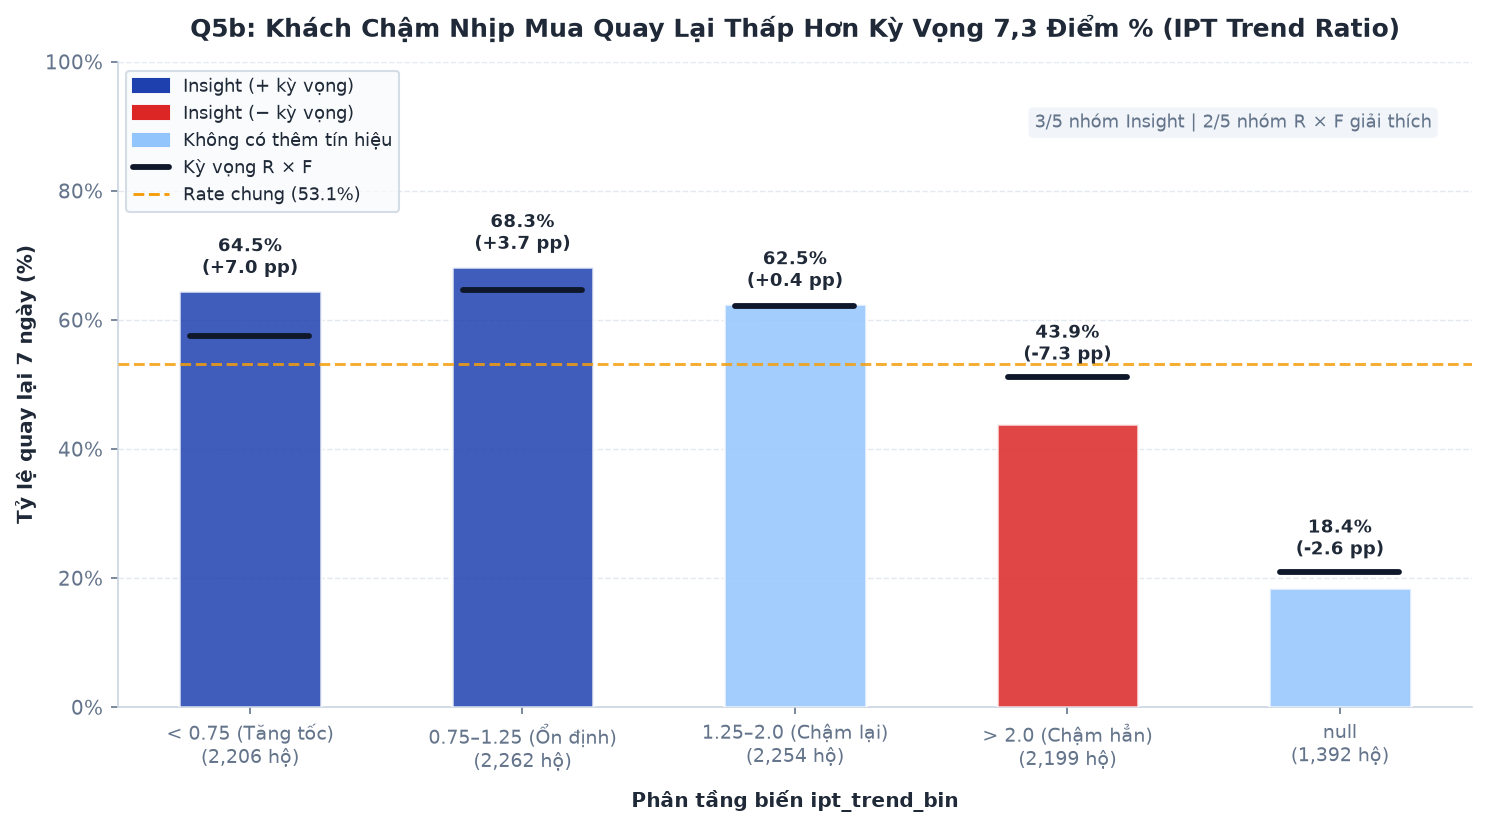

ipt_trend_bin,n_rows,n_households,observed,expected,excess_pp,same_sign_share,verdict,verdict_reason
< 0.75 (Tăng tốc),32135,2206,0.645464,0.575414,7.005039,0.962963,Insight,Hiệu ứng +7.01 pp ổn định qua 96.3% cutoff
0.75–1.25 (Ổn định),49449,2262,0.682845,0.645749,3.709593,0.962963,Insight,Hiệu ứng +3.71 pp ổn định qua 96.3% cutoff
1.25–2.0 (Chậm lại),42012,2254,0.625345,0.621363,0.398241,0.592593,Đã được R × F giải thích,Chênh lệch thô +9.42 pp nhưng sau R × F chỉ còn +0.40 pp (< 3.0 pp)
> 2.0 (Chậm hẳn),47708,2199,0.438920,0.511449,-7.252881,1.000000,Insight,Hiệu ứng -7.25 pp ổn định qua 100.0% cutoff
null,30933,1392,0.184011,0.209547,-2.553636,0.962963,Đã được R × F giải thích,Chênh lệch thô -34.71 pp nhưng sau R × F chỉ còn -2.55 pp (< 3.0 pp)


In [ ]:
from propensity.features.temporal import temporal_features, trend_bin

pdays = lines[["household_key", "DAY"]].drop_duplicates()
tf = temporal_features(pdays, cutoffs)
panel = join_features(panel, tf)

panel["ipt_trend_bin"] = trend_bin(panel["recent_ipt_ratio_c"])
q5b_excess = add_verdicts(excess_over_rf(panel, "ipt_trend_bin"))

fig_q5b = plot_rate_and_excess(q5b_excess, title="Q5b: Khách Chậm Nhịp Mua Quay Lại Thấp Hơn Kỳ Vọng 7,3 Điểm % (IPT Trend Ratio)")
save_fig(fig_q5b, "part5", "customer_q5b_ipt_trend_excess.png")
display(fig_q5b)

q5b_excess[["ipt_trend_bin", "n_rows", "n_households", "observed", "expected", "excess_pp", "same_sign_share", "verdict", "verdict_reason"]]


### Phân Tích Chi Tiết Q5b: Xu Hướng Chu Kỳ Mua Sắm (IPT Trend Ratio — PHÁT HIỆN ĐẮT GIÁ)

1. **Mô tả (Description)**:
   - `recent_ipt_ratio_c = mean(3 gap gần nhất) / median(các gap trước đó)` đo lường xem khách đang tăng tốc hay giảm tốc so với chính họ.
   - Nhóm **"< 0.75 (Tăng tốc)"** (32,135 dòng, 2,206 hộ): Tỷ lệ quay lại thực tế đạt **64.55%** vs kỳ vọng $R \times F$ là 57.54%, tạo ra mức chênh lệch dương vượt trội **+7.01 pp**, cùng dấu dương ở **96.3%** cutoff (78/81 mốc) -> **INSIGHT**!
   - Nhóm **"0.75–1.25 (Ổn định)"** (49,449 dòng, 2,262 hộ): Thực tế đạt **68.28%** vs kỳ vọng 64.57%, excess **+3.71 pp**, cùng dấu ở **96.3%** cutoff -> **INSIGHT**!
   - Nhóm **"1.25–2.0 (Chậm lại)"** (42,012 dòng): Thực tế 62.53% vs kỳ vọng 62.14%, excess **+0.40 pp** -> Đã được R × F giải thích.
   - Nhóm **"> 2.0 (Chậm hẳn)"** (47,708 dòng, 2,199 hộ): Thực tế tụt xuống **43.89%** vs kỳ vọng 51.14%, tạo ra mức chênh lệch âm cực sâu **−7.25 pp**, cùng dấu âm ở **100.0%** cutoff (81/81 mốc không ngoại lệ!) -> **INSIGHT**!
2. **Vì sao (Why)**:
   - $R \times F$ chỉ là giá trị trung bình tính gộp trên toàn bộ lịch sử (cumulative average). Một khách hàng từng có tần suất cao ($F > 1.5$) nhưng trong 3 lần mua gần nhất các khoảng cách giãn gấp đôi bình thường (`ratio > 2.0`), thì trung bình toàn bộ $F$ vẫn còn cao nhưng hành vi thực tế đã bị suy thoái nghiêm trọng!
   - Tỷ số IPT Trend bắt trọn gia tốc hành vi (acceleration / deceleration), phản ánh sự thay đổi nhịp sống của hộ gia đình trước khi các chỉ số tích lũy dài hạn kịp phản ánh.
3. **Liên quan đến label (Relation to label)**:
   - Tạo ra biên độ chênh lệch thuần túy ngoài $R \times F$ lên tới **14.26 pp** (+7.01 pp ở nhóm tăng tốc so với −7.25 pp ở nhóm chậm hẳn).
   - Đây là biến số mạnh nhất từ trước đến nay chứng minh được năng lực dự báo vượt trội độc lập với $R \times F$.
4. **Insight**:
   - **Model & Business Insight (Early Warning of Churn)**:
     - Nhóm "Chậm hẳn" (`ratio > 2.0`) là tín hiệu cảnh báo sớm nguy cơ rời bỏ (early churn indicator). Khách chưa hẳn đã dừng hẳn (Recency vẫn chưa quá lớn), nhưng chu kỳ mua đã bị gãy.
5. **Hành động (Action)**:
   - **Đưa ngay `recent_ipt_ratio_c` vào Feature Store làm FEATURE CỐT LÕI BẬC 1 của mô hình dự báo propensity.**
   - Trong kinh doanh: Xây dựng kịch bản "Chiến dịch giữ chân sớm (Early Retention Workflow)": Khi một khách hàng quen có tỷ số IPT Trend vượt 1.5, tự động kích hoạt khảo sát trải nghiệm hoặc ưu đãi cá nhân hóa ngay lập tức, thay vì đợi đến khi khách chuyển sang Recency > 30 ngày (lúc đó đã quá muộn).

> **Card Biến Q5b: Xu hướng chu kỳ gần đây (`recent_ipt_ratio_c`)**
> - Độ phủ: 84.70% dòng quan sát có ≥8 gaps lịch sử (15.30% null)
> - Excess ngoài $R \times F$: Nhóm tăng tốc (<0.75): **+7.01 pp** | Nhóm chậm hẳn (>2.0): **−7.25 pp** (Biên độ thuần túy: **14.26 pp**)
> - Độ ổn định: Cùng dấu ở 96.3% (tăng tốc) và 100.0% cutoff (chậm hẳn)
> - Kết luận tự động: **Insight (Cả nhóm Tăng tốc và Chậm hẳn đều là Insight độc lập)**
> - Quyết định: **FEATURE CỐT LÕI BẬC 1 CHO MÔ HÌNH & HỆ THỐNG CẢNH BÁO RỜI BỎ SỚM.**


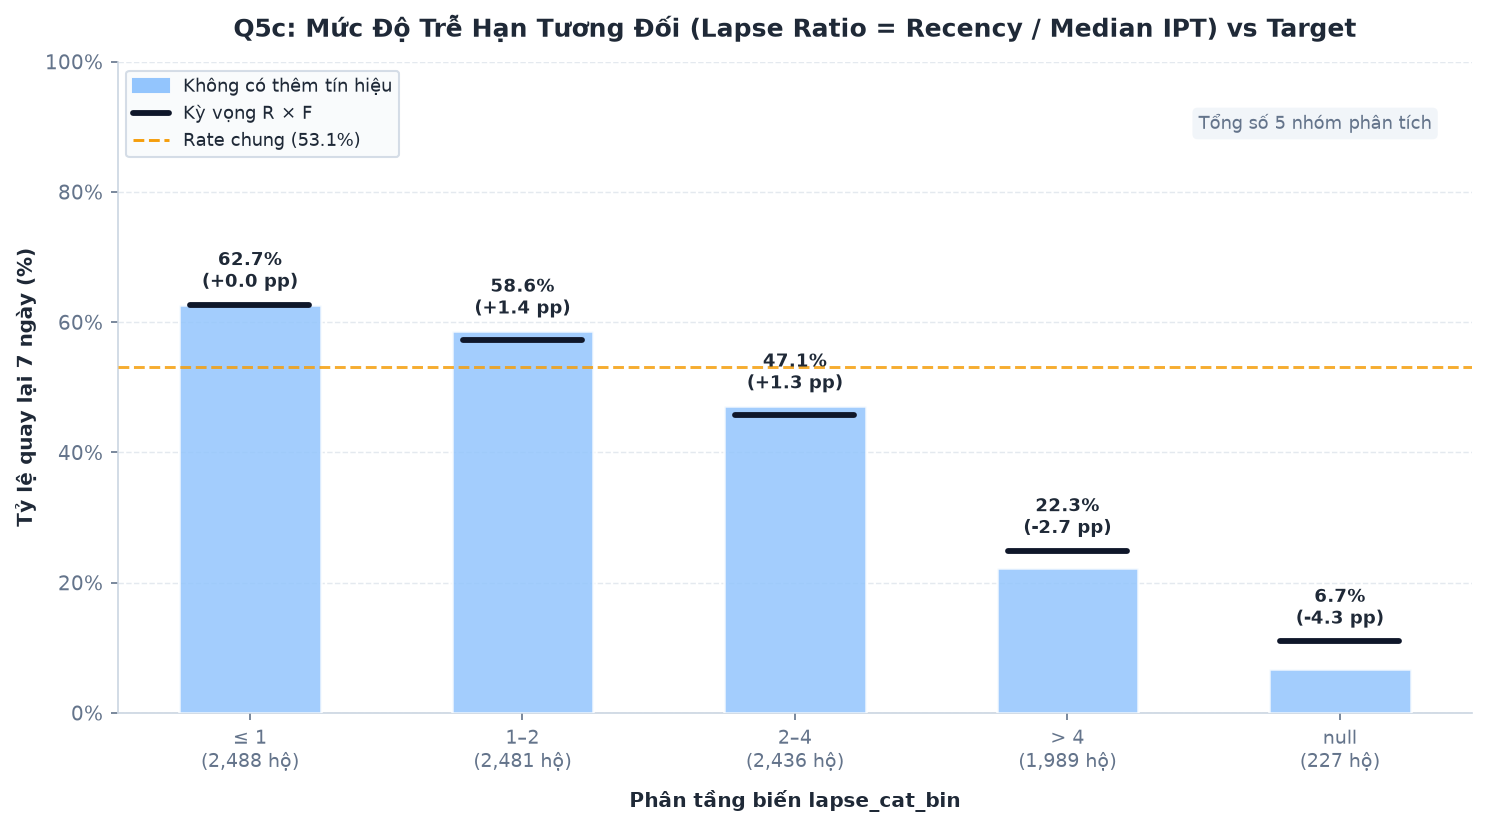

lapse_cat_bin,n_rows,n_households,observed,expected,excess_pp,same_sign_share,verdict,verdict_reason
≤ 1,103350,2488,0.627121,0.626836,0.028581,0.555556,Đã được R × F giải thích,Chênh lệch thô +9.60 pp nhưng sau R × F chỉ còn +0.03 pp (< 3.0 pp)
1–2,39707,2481,0.586194,0.572569,1.362499,0.679012,Đã được R × F giải thích,Chênh lệch thô +5.51 pp nhưng sau R × F chỉ còn +1.36 pp (< 3.0 pp)
2–4,26818,2436,0.471288,0.458316,1.297169,0.666667,Đã được R × F giải thích,Chênh lệch thô -5.98 pp nhưng sau R × F chỉ còn +1.30 pp (< 3.0 pp)
> 4,29032,1989,0.222548,0.249162,-2.661420,0.851852,Đã được R × F giải thích,Chênh lệch thô -30.86 pp nhưng sau R × F chỉ còn -2.66 pp (< 3.0 pp)
null,3330,227,0.066967,0.109953,-4.298575,0.813953,Không đủ dữ liệu,Nhóm quá nhỏ (1.6% dòng < 2% hoặc 227 hộ < 50)


In [ ]:
from propensity.features.temporal import lapse_bin

panel["lapse_cat_bin"] = lapse_bin(panel["lapse_ratio_c"])
q5c_excess = add_verdicts(excess_over_rf(panel, "lapse_cat_bin"))

fig_q5c = plot_rate_and_excess(q5c_excess, title="Q5c: Mức Độ Trễ Hạn Tương Đối (Lapse Ratio = Recency / Median IPT) vs Target")
save_fig(fig_q5c, "part5", "customer_q5c_lapse_ratio_excess.png")
display(fig_q5c)

q5c_excess[["lapse_cat_bin", "n_rows", "n_households", "observed", "expected", "excess_pp", "same_sign_share", "verdict", "verdict_reason"]]


### Phân Tích Chi Tiết Q5c: Mức Độ Trễ Hạn Tương Đối (Relative Lapse Ratio)

1. **Mô tả (Description)**:
   - `lapse_ratio_c = recency / median_ipt` đo lường số bội số chu kỳ mà khách hàng đã trễ hẹn so với nhịp mua sắm tự nhiên của chính họ.
   - Tỷ lệ quay lại thô giảm rất dốc theo mức độ trễ hạn: từ **62.71%** ở nhóm "≤ 1 (Đúng hạn)", xuống **58.62%** (1–2), **47.13%** (2–4), và rơi mạnh xuống **22.25%** ở nhóm "> 4 (Trễ nhiều)".
   - Tuy nhiên, sau khi so sánh với kỳ vọng $R \times F$, chênh lệch thuần túy chỉ còn dao động hẹp: **+0.03 pp** (≤1), **+1.36 pp** (1–2), **+1.30 pp** (2–4), và **−2.66 pp** (>4), tất cả đều nằm trong ngưỡng $[-3.0, +3.0] pp$.
   - Toàn bộ 4 khoảng trễ hạn đều được tự động xếp loại: **"Đã được R × F giải thích"**.
2. **Vì sao (Why)**:
   - Bản thân $R \times F$ (kết hợp giữa Recency theo ngày và Frequency) đã phản ánh rất mạnh mẽ nhịp độ mua sắm tổng thể. Khi biết một khách hàng có Recency bằng 14 ngày và F bằng 0.5 (tương đương chu kỳ 14 ngày), mô hình $R \times F$ đã ngầm định khách hàng đó đang ở trạng thái "đúng hạn".
   - Do đó, phần lớn phương sai của Lapse Ratio đã được cặp biến $R \times F$ hấp thụ.
3. **Liên quan đến label (Relation to label)**:
   - Dù không bổ sung nhiều thặng dư tuyến tính ngoài $R \times F$, Lapse Ratio chuẩn hóa hoàn hảo nhịp sinh học: một khách mua 3 ngày/lần trễ 6 ngày (lapse=2.0) có tâm lý và trạng thái rời bỏ tương đương một khách mua 14 ngày/lần trễ 28 ngày (lapse=2.0).
4. **Insight**:
   - **Segmentation & Business Insight**: Đây là biến phân khúc cực kỳ giá trị cho nghiệp vụ CRM. Thay vì gửi thông điệp sau cố định 7 hay 14 ngày cho tất cả mọi người, hãy gửi thông điệp dựa trên ngưỡng `lapse_ratio_c > 1.5` để tôn trọng nhịp mua sắm cá nhân.
5. **Hành động (Action)**:
   - Quyết định: Sử dụng `lapse_ratio_c` làm trục phân chia hành vi chính trong **Phần 8 (Customer Segmentation vs Label)**.
   - Trong mô hình học máy: Đưa vào danh mục feature bậc 2 (feature tương tác nhịp độ).

> **Card Biến Q5c: Tỷ lệ trễ hạn tương đối (`lapse_ratio_c`)**
> - Độ phủ: 98.35% dòng quan sát (chỉ 1.65% null do chưa đủ 2 ngày mua)
> - Tỷ lệ quay lại thô: 62.71% (≤1) → 58.62% (1–2) → 47.13% (2–4) → 22.25% (>4)
> - Chênh lệch sau khi kiểm soát $R \times F$: −2.66 pp đến +1.36 pp (Đã được R × F giải thích trọn vẹn)
> - Quyết định: Trở thành trục phân đoạn cốt lõi cho **Phần 8: Customer Segmentation**.


---
### Bảng Tổng Kết Phần 4 & Phần 5: Basket & Temporal Analytics (Đặc Tả & Quyết Định Mô Hình)

| Nhóm Phân Tích | Tên Feature | Kết luận tự động (Verdict) | Khoảng Excess ngoài $R \times F$ | Độ ổn định (Same-sign) | Quyết định từ EDA |
| :--- | :--- | :--- | :---: | :---: | :--- |
| **Q4a Basket Bands** | `basket_size_bands` | **Business Insight** | — | — | Phân hóa sâu sắc giữa Quick Trip (50.7% giỏ, 15.1% spend) và Stock-up Trip (14.1% giỏ, 47.4% spend). Dùng định vị giỏ hàng. |
| **Q4b Basket Size** | `median_products_per_day_c` | Đã được R × F giải thích | −2.34 đến +2.25 pp | 56.8% – 70.4% | **Loại khỏi feature chính**. Chênh lệch thô biến mất hoàn toàn sau $R \times F$. |
| **Q4c Last Basket** | `last_basket_ratio_c` | Đã được R × F giải thích (Insight cho null) | −0.84 đến +1.49 pp | 56.8% – 70.4% | **Dùng làm quy tắc CRM Cool-down**. Giỏ lớn >2.5x giãn nhẹ chu kỳ mua sắm (excess âm nhẹ). |
| **Q5a Stability** | `cutoff_return_rates` | **Data Quality Confirmed** | — | 100% ổn định | **0 cutoff bất thường** (|z| > 3.5). Tỷ lệ nhãn ổn định cao qua 81 mốc cutoff độc lập (Day 140..700). |
| **Q5b IPT Trend** | `recent_ipt_ratio_c` | **INSIGHT (ĐỘC LẬP MẠNH MẼ)** | **+7.01 pp (Tăng tốc) / −7.25 pp (Chậm hẳn)** | **96.3% – 100.0%** | **FEATURE CỐT LÕI BẬC 1**. Biên độ thuần túy 14.26 pp ngoài $R \times F$. Cảnh báo rời bỏ sớm. |
| **Q5c Lapse Ratio** | `lapse_ratio_c` | Đã được R × F giải thích | −2.66 đến +1.36 pp | 55.6% – 85.2% | **Trục cốt lõi cho Phần 8 (Segmentation)**. Chuẩn hóa nhịp sinh học cá nhân. |

---

### Danh Sách Hình Ảnh Xuất Bản (Slide-Ready Figures Saved)

Tất cả các biểu đồ đã được lưu với độ phân giải cao (200 dpi) theo cấu trúc thư mục quy chuẩn:

1. **Part 4 (Basket Analytics)**:
   - `reports/figures/part4/customer_q4a_basket_bands.png`: Biểu đồ cột đôi % giỏ hàng vs % doanh số qua 5 khoảng kích thước giỏ (FIGSIZE_FULL).
   - `reports/figures/part4/customer_q4a_basket_hist.png`: Phân bổ số sản phẩm trong giỏ hàng hóa cắt đuôi p99.5 kèm median và p10/p90 (FIGSIZE_HALF).
   - `reports/figures/part4/customer_q4b_basket_size_excess.png`: Phân tích quy mô giỏ hàng trung bình vs kỳ vọng $R \times F$ (FIGSIZE_FULL).
   - `reports/figures/part4/customer_q4c_last_basket_ratio_excess.png`: Hiện tượng tích trữ Pantry-loading: tỷ lệ giỏ hàng gần nhất vs kỳ vọng $R \times F$ (FIGSIZE_FULL).

2. **Part 5 (Temporal Analytics)**:
   - `reports/figures/part5/customer_q5a_weekly_active.png`: Số hộ gia đình hoạt động theo tuần, vạch mốc Day 140 và đường trung bình ổn định (FIGSIZE_FULL).
   - `reports/figures/part5/customer_q5a_cutoff_return_rates.png`: Tính ổn định của nhãn quay lại qua 81 cutoff kèm dải p10–p90 (FIGSIZE_FULL).
   - `reports/figures/part5/customer_q5b_ipt_trend_excess.png`: Xu hướng chu kỳ mua sắm gần đây (IPT Trend Ratio) vs kỳ vọng $R \times F$ làm nổi bật hiệu ứng Insight (FIGSIZE_FULL).
   - `reports/figures/part5/customer_q5c_lapse_ratio_excess.png`: Mức độ trễ hạn tương đối (Lapse Ratio) vs kỳ vọng $R \times F$ (FIGSIZE_FULL).


---
## Phần 6: Nhân Khẩu Học (Demographic Analytics: Q9a Coverage & Selection Bias, Q9b Profiling, Q9c Demographic vs Target)

Mục tiêu chính:
1. **Q9a (Độ phủ & Selection Bias)**: Đánh giá nhóm có dữ liệu nhân khẩu học (801 / 2,500 hộ = 32.0%) có khác biệt thế nào so với nhóm không có dữ liệu: về hành vi mua sắm ($F\_bin$, $recency\_bin$) và tỷ lệ quay lại sau khi kiểm soát $R \times F$.
2. **Q9b (Chân dung 801 hộ gia đình)**: Mô tả phân bố của 801 hộ gia đình theo 7 thuộc tính: Độ tuổi (`age`), Thu nhập (`income`), Nhà ở (`homeowner`), Hôn nhân (`marital`), Cơ cấu hộ (`hh_comp`), Quy mô hộ (`hh_size`), Số lượng con cái (`kids`).
3. **Q9c (Nhân khẩu học vs Nhãn quay lại)**: Trong nhóm 801 hộ có nhân khẩu học, thuộc tính nào còn mang lại năng lực phân tách đối với việc quay lại sau khi kiểm soát $R \times F$?

*Lưu ý quan trọng*: Bảng `hh_demographic.csv` không có mốc thời gian ghi nhận nên được xem là thuộc tính tĩnh (static attributes). Mọi kết luận ở Q9b và Q9c chỉ áp dụng cho 32.0% hộ gia đình có đăng ký thông tin hội viên.


In [ ]:
from propensity.features.demographic import (
    DEMO_GROUPS,
    group_demographic,
    demographic_features,
)

demo = pd.read_csv("data/raw/Dunnhumby/hh_demographic.csv")
demo_grouped = group_demographic(demo, DEMO_GROUPS)

len_before = len(panel)
panel = demographic_features(panel, demo_grouped)
len_after = len(panel)

print(f"Số hộ có dữ liệu demographic: {len(demo_grouped):,} / {panel['household_key'].nunique():,} ({len(demo_grouped)/panel['household_key'].nunique():.1%})")
print(f"Số dòng panel trước ghép: {len_before:,} | Sau ghép: {len_after:,} (Khớp hoàn hảo, không trùng lặp)")
display(demo_grouped.head())


Số hộ có dữ liệu demographic: 801 / 2,500 (32.0%)
Số dòng panel trước ghép: 202,237 | Sau ghép: 202,237 (Khớp hoàn hảo, không trùng lặp)


household_key,demo_age,demo_income,demo_homeowner,demo_marital,demo_hh_comp,demo_hh_size,demo_kids
1,55+,35-49K,Sở hữu,A,"2 người lớn, không con",2,Không/không rõ
7,45-54,50-74K,Sở hữu,A,"2 người lớn, không con",2,Không/không rõ
8,19-34,<35K,Không rõ,U,Có con,3,1
13,19-34,75-124K,Sở hữu,U,Có con,4+,2+
16,45-54,50-74K,Sở hữu,B,Độc thân,1,Không/không rõ


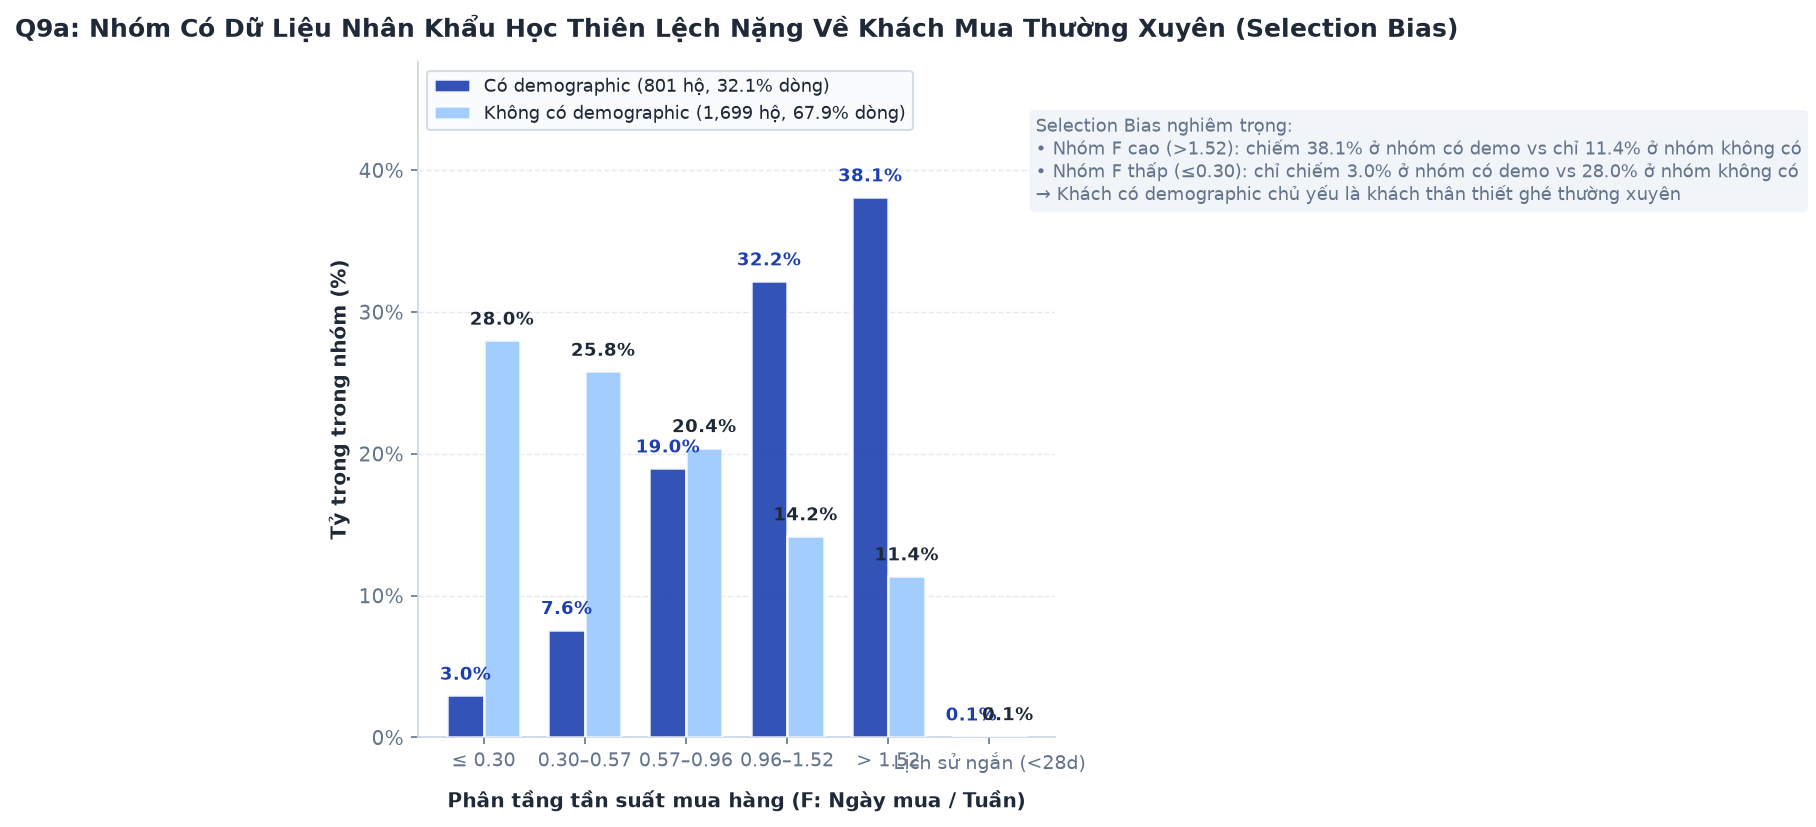

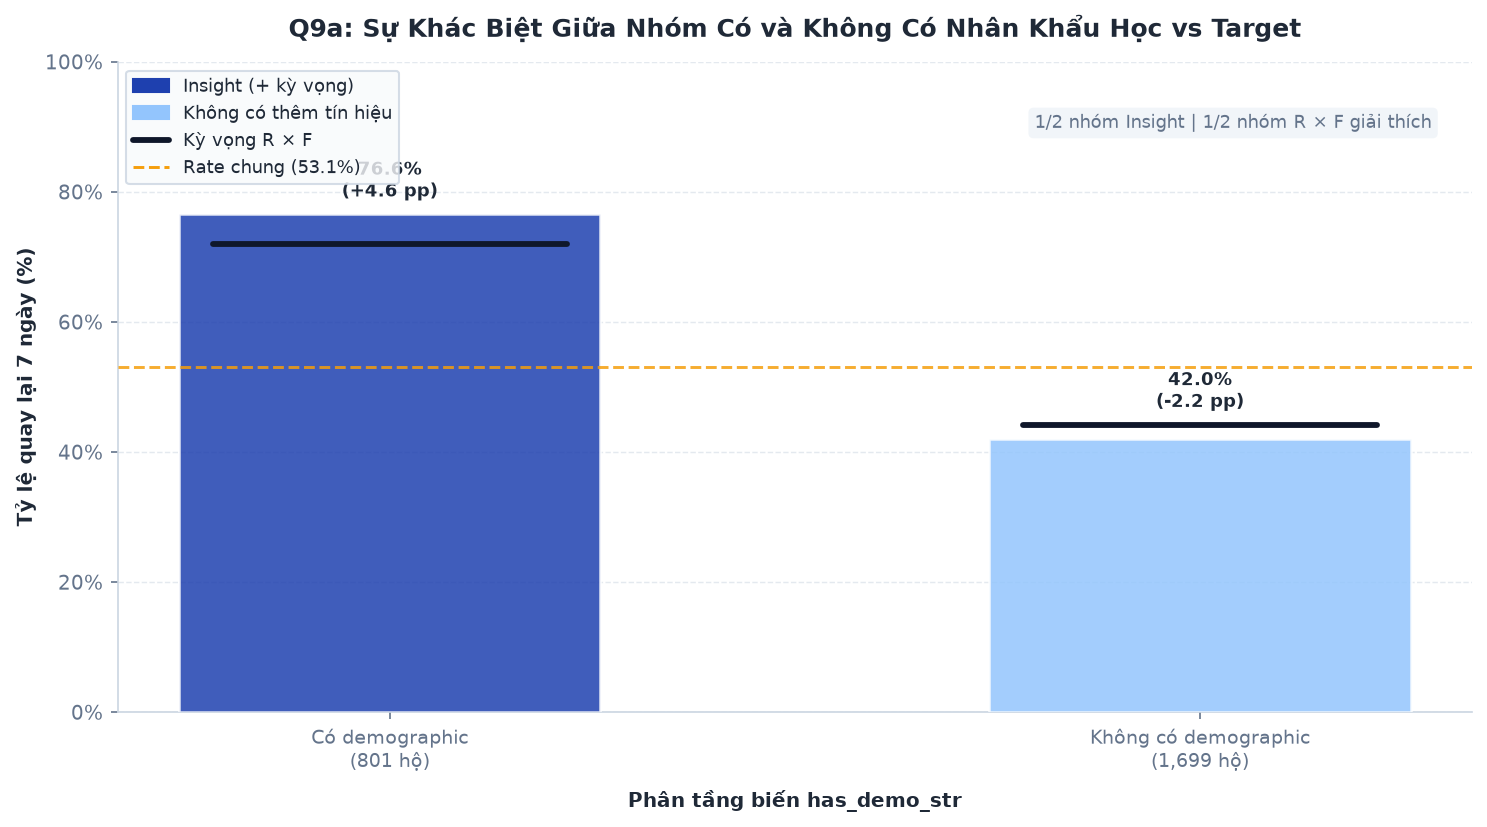

=== Bảng Phân Bổ & Excess Theo Tình Trạng Có Dữ Liệu Nhân Khẩu Học ===


has_demo_str,n_rows,n_households,row_share,observed,expected,excess_pp,same_sign_share,verdict,verdict_reason
Có demographic,64881,801,0.320817,0.765725,0.719346,4.637862,0.987654,Insight,Hiệu ứng +4.64 pp ổn định qua 98.8% cutoff
Không có demographic,137356,1699,0.679183,0.420302,0.442190,-2.188821,0.876543,Đã được R × F giải thích,Chênh lệch thô -11.08 pp nhưng sau R × F chỉ còn -2.19 pp (< 3.0 pp)


In [ ]:
from propensity.features.demographic import demographic_coverage_profile
from propensity.eda.demographic_plots import plot_demographic_coverage
from propensity.eda.propensity_rates import excess_over_rf, add_verdicts
from propensity.viz.style import plot_rate_and_excess, save_fig

fig_q9a_cov = plot_demographic_coverage(panel)
save_fig(fig_q9a_cov, "part6", "customer_q9a_demographic_coverage.png")
display(fig_q9a_cov)

panel["has_demo_str"] = panel["has_demographic"].map(
    {0: "Không có demographic", 1: "Có demographic"}
).astype("category")
q9a_excess = add_verdicts(excess_over_rf(panel, "has_demo_str"))

fig_q9a_excess = plot_rate_and_excess(
    q9a_excess,
    title="Q9a: Sự Khác Biệt Giữa Nhóm Có và Không Có Nhân Khẩu Học vs Target",
)
save_fig(fig_q9a_excess, "part6", "customer_q9a_has_demographic_excess.png")
display(fig_q9a_excess)

cov_df = demographic_coverage_profile(panel)
print("=== Bảng Phân Bổ & Excess Theo Tình Trạng Có Dữ Liệu Nhân Khẩu Học ===")
display(q9a_excess[["has_demo_str", "n_rows", "n_households", "row_share", "observed", "expected", "excess_pp", "same_sign_share", "verdict", "verdict_reason"]])


### Phân Tích Chi Tiết Q9a: Độ Phủ & Thiên Lệch Chọn Lọc (Selection Bias)

1. **Mô tả (Description)**:
   - Dữ liệu nhân khẩu học chỉ có sẵn cho **801 / 2,500 hộ gia đình** (**32.04%** số hộ, tương đương 64,881 / 202,237 dòng = **32.08%** số dòng quan sát).
   - **Thiên lệch chọn lọc cực đoan (Extreme Selection Bias)**:
     - Nhóm có demographic nghiêng lệch nặng về khách hàng mua thường xuyên: **38.1%** thuộc nhóm top $F > 1.52$ (so với chỉ **11.4%** ở nhóm không có demographic, gấp 3.3 lần!).
     - Ngược lại, nhóm ghé rất thưa ($F \le 0.30$) chỉ chiếm **3.0%** ở nhóm có demographic (so với **28.0%** ở nhóm không có demographic, gấp 9.3 lần!).
     - Về Recency: **76.5%** khách có demographic có Recency 1–7 ngày (so với chỉ 42.1% ở nhóm không có).
   - **Tỷ lệ quay lại 7 ngày thô**: Nhóm có demographic đạt **76.57%**, cao hơn nhóm không có (**42.03%**) tới **+34.54 điểm %**.
   - **Sau khi kiểm soát $R \times F$**: Tỷ lệ kỳ vọng của nhóm có demographic là 71.93%, chênh lệch thuần túy còn **+4.64 pp** (cùng dấu ở **98.8%** cutoff $\rightarrow$ xếp loại **Insight**). Nhóm không có demographic có excess **−2.19 pp** (Đã được R × F giải thích).
2. **Vì sao (Why)**:
   - Dữ liệu nhân khẩu học trong bán lẻ thực tế thường thu thập qua chương trình đăng ký thẻ thành viên thân thiết (loyalty card application). Khách hàng chịu dành thời gian điền form nhân khẩu học vốn là những người ghé siêu thị thường xuyên nhất và gắn bó nhất với thương hiệu.
   - Do đó, việc có thông tin demographic tự nó đã là một "proxy" chứng minh mức độ gắn kết cao với siêu thị.
3. **Liên quan đến label (Relation to label)**:
   - Tỷ lệ quay lại thô cao vọt (+34.54 pp) chủ yếu đến từ việc họ có $F$ cao và $R$ gần. Khi đã biết $R$ và $F$, cờ `has_demographic` vẫn mang lại thặng dư dương ổn định **+4.64 pp**, phản ánh tâm lý cam kết của hội viên trung thành.
4. **Insight**:
   - **Data Quality & Selection Bias Warning**: Dữ liệu nhân khẩu học **KHÔNG HỀ ĐẠI DIỆN** cho toàn bộ khách hàng. Bất kỳ phân tích nào trên 801 hộ này chỉ khái quát hóa được cho nhóm hội viên thân thiết (loyal members).
   - **Model Insight**: Cờ nhị phân `has_demographic` (0/1) là một feature độc lập có giá trị (+4.64 pp excess, 98.8% ổn định).
5. **Hành động (Action)**:
   - **Giữ `has_demographic` làm feature bổ trợ trong mô hình.**
   - Mọi phân tích thuộc tính chi tiết ở Q9b và Q9c phải được hiểu là phân tích nội bộ trên tập 32% hội viên thân thiết, không suy diễn ra 68% khách hàng còn lại.

> **Card Biến Q9a: Cờ có thông tin nhân khẩu học (`has_demographic`)**
> - Độ phủ: 32.08% dòng có dữ liệu (801 hộ) | 67.92% không có (1,699 hộ)
> - Phân bố F: Nhóm có demo có 38.1% ở $F > 1.52$ (vs 11.4% ở nhóm không có)
> - Tỷ lệ quay lại thô: 76.57% (Có) vs 42.03% (Không) (Chênh lệch thô: +34.54 pp)
> - Chênh lệch sau $R \times F$: **+4.64 pp** (Có) vs **−2.19 pp** (Không) (Ổn định ở 98.8% cutoff)
> - Kết luận tự động: **Insight (Proxy cho mức độ cam kết của hội viên thân thiết)**
> - Quyết định: Đưa cờ `has_demographic` vào mô hình dự báo.


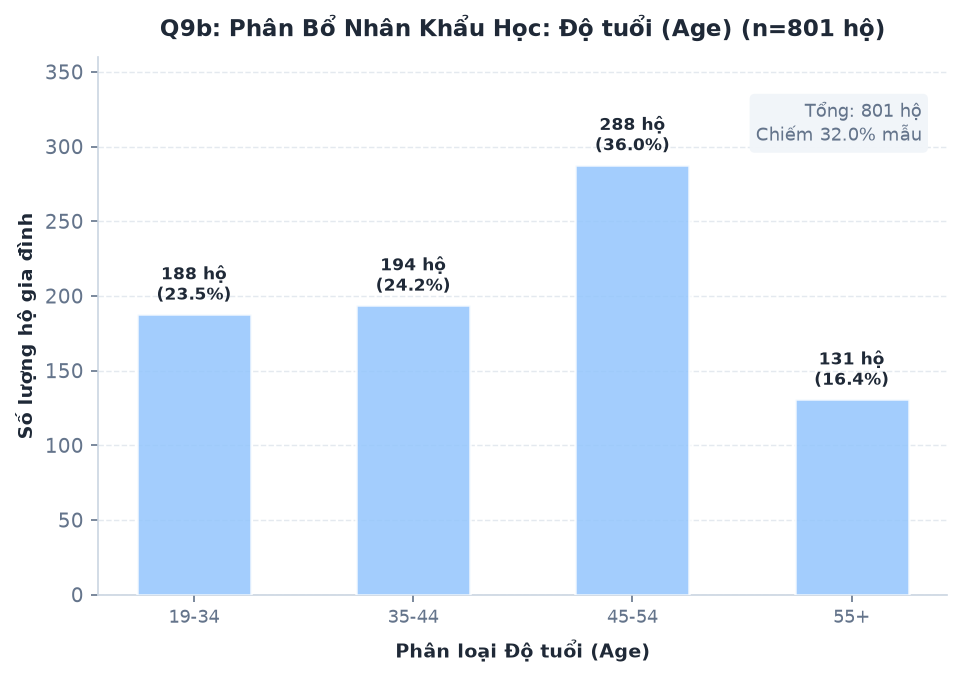

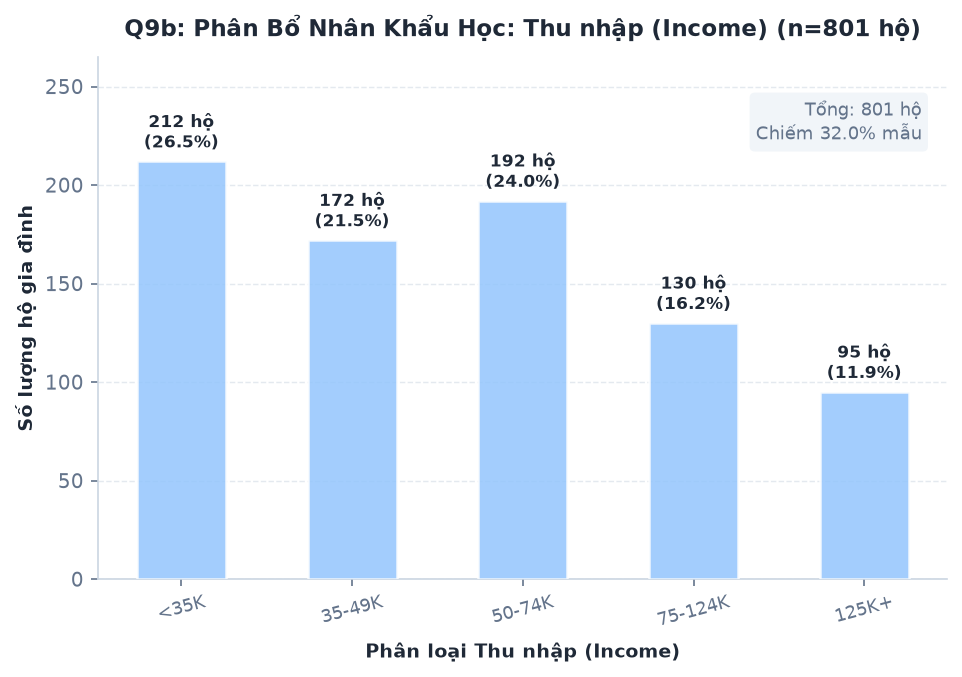

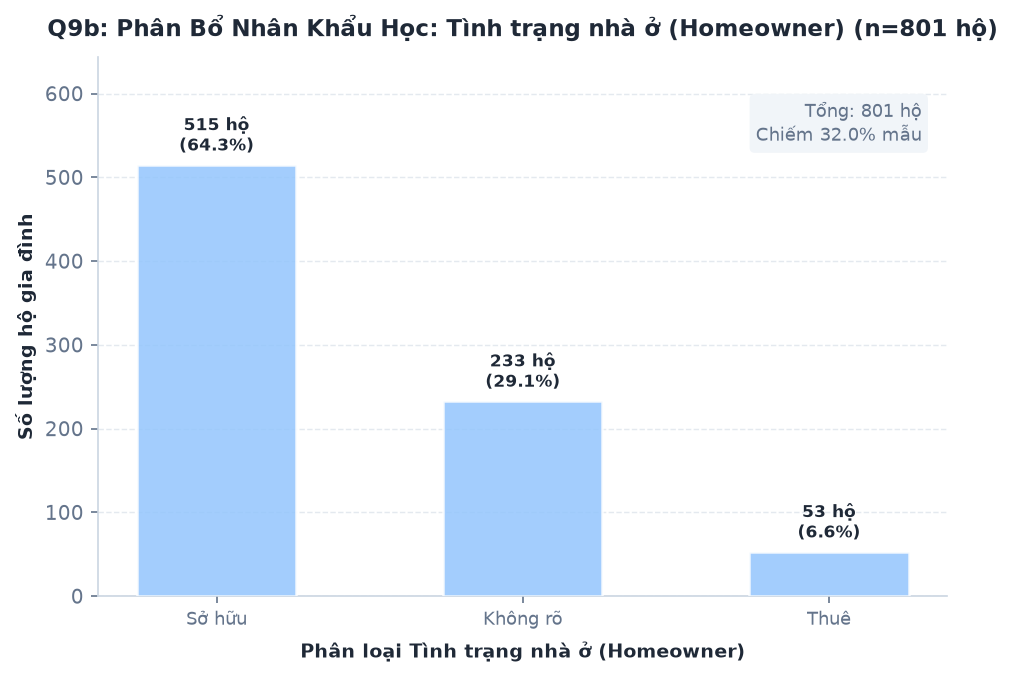

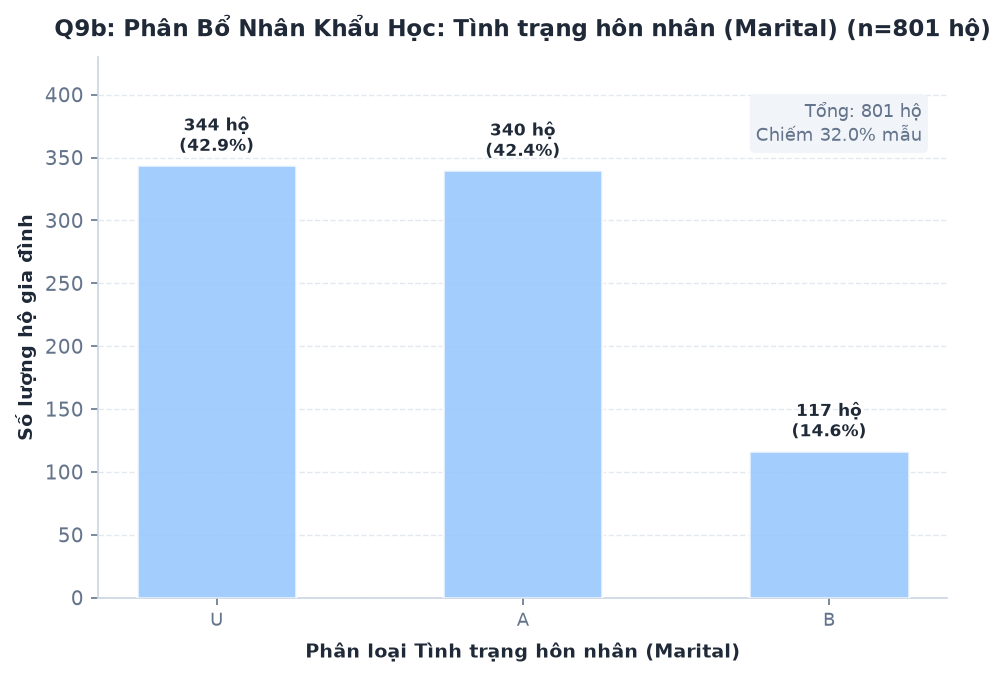

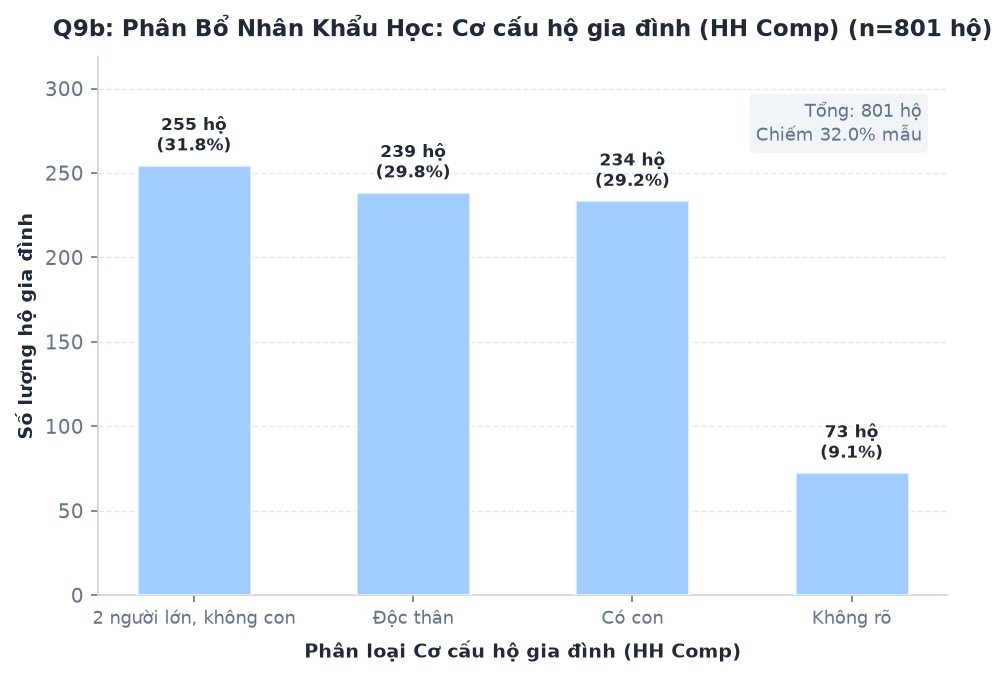

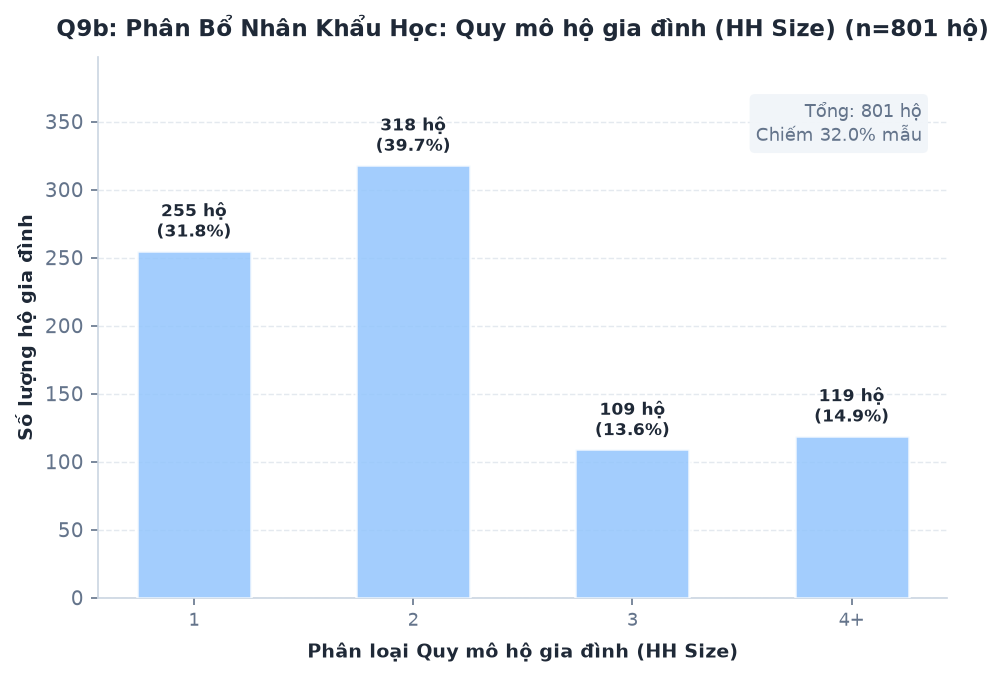

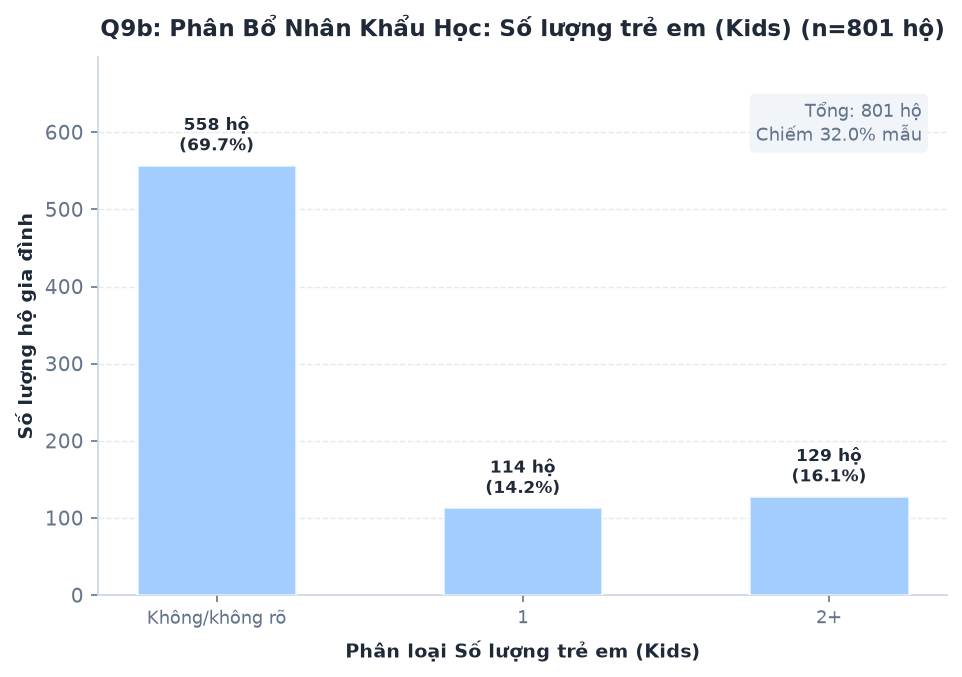

In [ ]:
from propensity.eda.demographic_plots import plot_attribute_distribution
from propensity.viz.style import save_fig

attrs = ["age", "income", "homeowner", "marital", "hh_comp", "hh_size", "kids"]
attr_titles = {
    "age": "Độ tuổi",
    "income": "Thu nhập",
    "homeowner": "Tình trạng nhà ở",
    "marital": "Tình trạng hôn nhân",
    "hh_comp": "Cơ cấu hộ gia đình",
    "hh_size": "Quy mô hộ gia đình",
    "kids": "Số lượng trẻ em",
}

for attr in attrs:
    fig_a = plot_attribute_distribution(demo_grouped, attr)
    save_fig(fig_a, "part6", f"customer_q9b_dist_{attr}.png")
    display(fig_a)

# Tổng hợp bảng đếm số hộ gia đình theo từng thuộc tính
demo_summary_rows = []
for attr in attrs:
    col = f"demo_{attr}"
    vc = demo_grouped[col].value_counts(sort=False)
    for lvl, cnt in vc.items():
        demo_summary_rows.append({
            "Thuộc tính": attr_titles[attr],
            "Phân nhóm": lvl,
            "Số hộ": cnt,
            "Tỷ trọng (%)": f"{cnt / len(demo_grouped):.1%}",
        })

display(pd.DataFrame(demo_summary_rows))


### Phân Tích Chi Tiết Q9b: Chân Dung 801 Hộ Gia Đình Thân Thiết

1. **Mô tả (Description)**:
   - **Độ tuổi (`age`)**: Chiếm tỷ trọng lớn nhất là độ tuổi trung niên **45–54 tuổi** (288 hộ, **36.0%**), tiếp theo là 35–44 tuổi (194 hộ, **24.2%**) và 19–34 tuổi (188 hộ, **23.5%**). Nhóm 55+ tuổi chiếm 131 hộ (**16.4%**).
   - **Thu nhập (`income`)**: Phân bổ đồng đều qua các tầng lớp: dưới $35K (212 hộ, **26.5%**), $50–74K (192 hộ, **24.0%**), $35–49K (172 hộ, **21.5%**), $75–124K (130 hộ, **16.2%**), và nhóm thượng lưu $125K+ (95 hộ, **11.9%**).
   - **Tình trạng nhà ở (`homeowner`)**: Chiếm đa số áp đảo là **Chủ sở hữu nhà** (515 hộ, **64.3%**). Thuê nhà chỉ chiếm 53 hộ (**6.6%**), và Không rõ 233 hộ (**29.1%**).
   - **Tình trạng hôn nhân (`marital`)**: Đã kết hôn (Mã A) chiếm 340 hộ (**42.4%**), Chưa kết hôn (Mã B) chiếm 117 hộ (**14.6%**), Không rõ (Mã U) chiếm 344 hộ (**42.9%**).
   - **Cơ cấu hộ (`hh_comp`)**: Chia đều giữa 3 nhóm: 2 người lớn không con (255 hộ, **31.8%**), Độc thân (239 hộ, **29.8%**), và Gia đình có con (234 hộ, **29.2%**). Nhóm không rõ chiếm 73 hộ (**9.1%**).
   - **Quy mô hộ (`hh_size`)**: Hộ 2 người chiếm nhiều nhất (318 hộ, **39.7%**), tiếp đến là hộ 1 người (255 hộ, **31.8%**). Hộ 3 người (109 hộ, **13.6%**) và 4+ người (119 hộ, **14.9%**).
   - **Trẻ em (`kids`)**: Phần lớn không có trẻ em hoặc không rõ (558 hộ, **69.7%**). Hộ có 1 con là 114 hộ (**14.2%**) và 2+ con là 129 hộ (**16.1%**).
2. **Vì sao (Why)**:
   - Hồ sơ nhân khẩu học hội viên phản ánh đối tượng khách hàng trung lưu, trung niên, đã sở hữu nhà và sống ổn định tại địa phương. Đây là nhóm khách hàng lý tưởng tạo ra dòng doanh thu đều đặn cho chuỗi siêu thị.
3. **Liên quan đến label (Relation to label)**:
   - Xem xét liệu các đặc điểm này có tạo ra sự khác biệt về xác suất quay lại mua hàng hay không ở bước Q9c.
4. **Insight**:
   - **Customer Profiling Insight**: Chân dung cốt lõi của hội viên là: Độ tuổi 35–54, sở hữu nhà riêng, quy mô 1–2 người lớn, thu nhập trung bình–khá ($35K–$74K).
5. **Hành động (Action)**:
   - Sử dụng chân dung này để định hướng thiết kế các chương trình quyền lợi hội viên và danh mục quà tặng tích điểm phù hợp với lối sống gia đình trung niên.

> **Card Biến Q9b: Chân dung nhân khẩu học hội viên (801 hộ)**
> - Nhóm tuổi chủ đạo: 45–54 tuổi (36.0%) | 35–44 tuổi (24.2%)
> - Tình trạng nhà: Sở hữu nhà (64.3%) | Thuê nhà (6.6%)
> - Quy mô hộ: 1–2 người lớn chiếm 71.5% (Hộ 2 người: 39.7%, Độc thân: 31.8%)
> - Thu nhập: Phân bổ đều, 72.0% nằm trong khoảng dưới $75K
> - Trẻ em: 69.7% không có con nhỏ trong nhà.


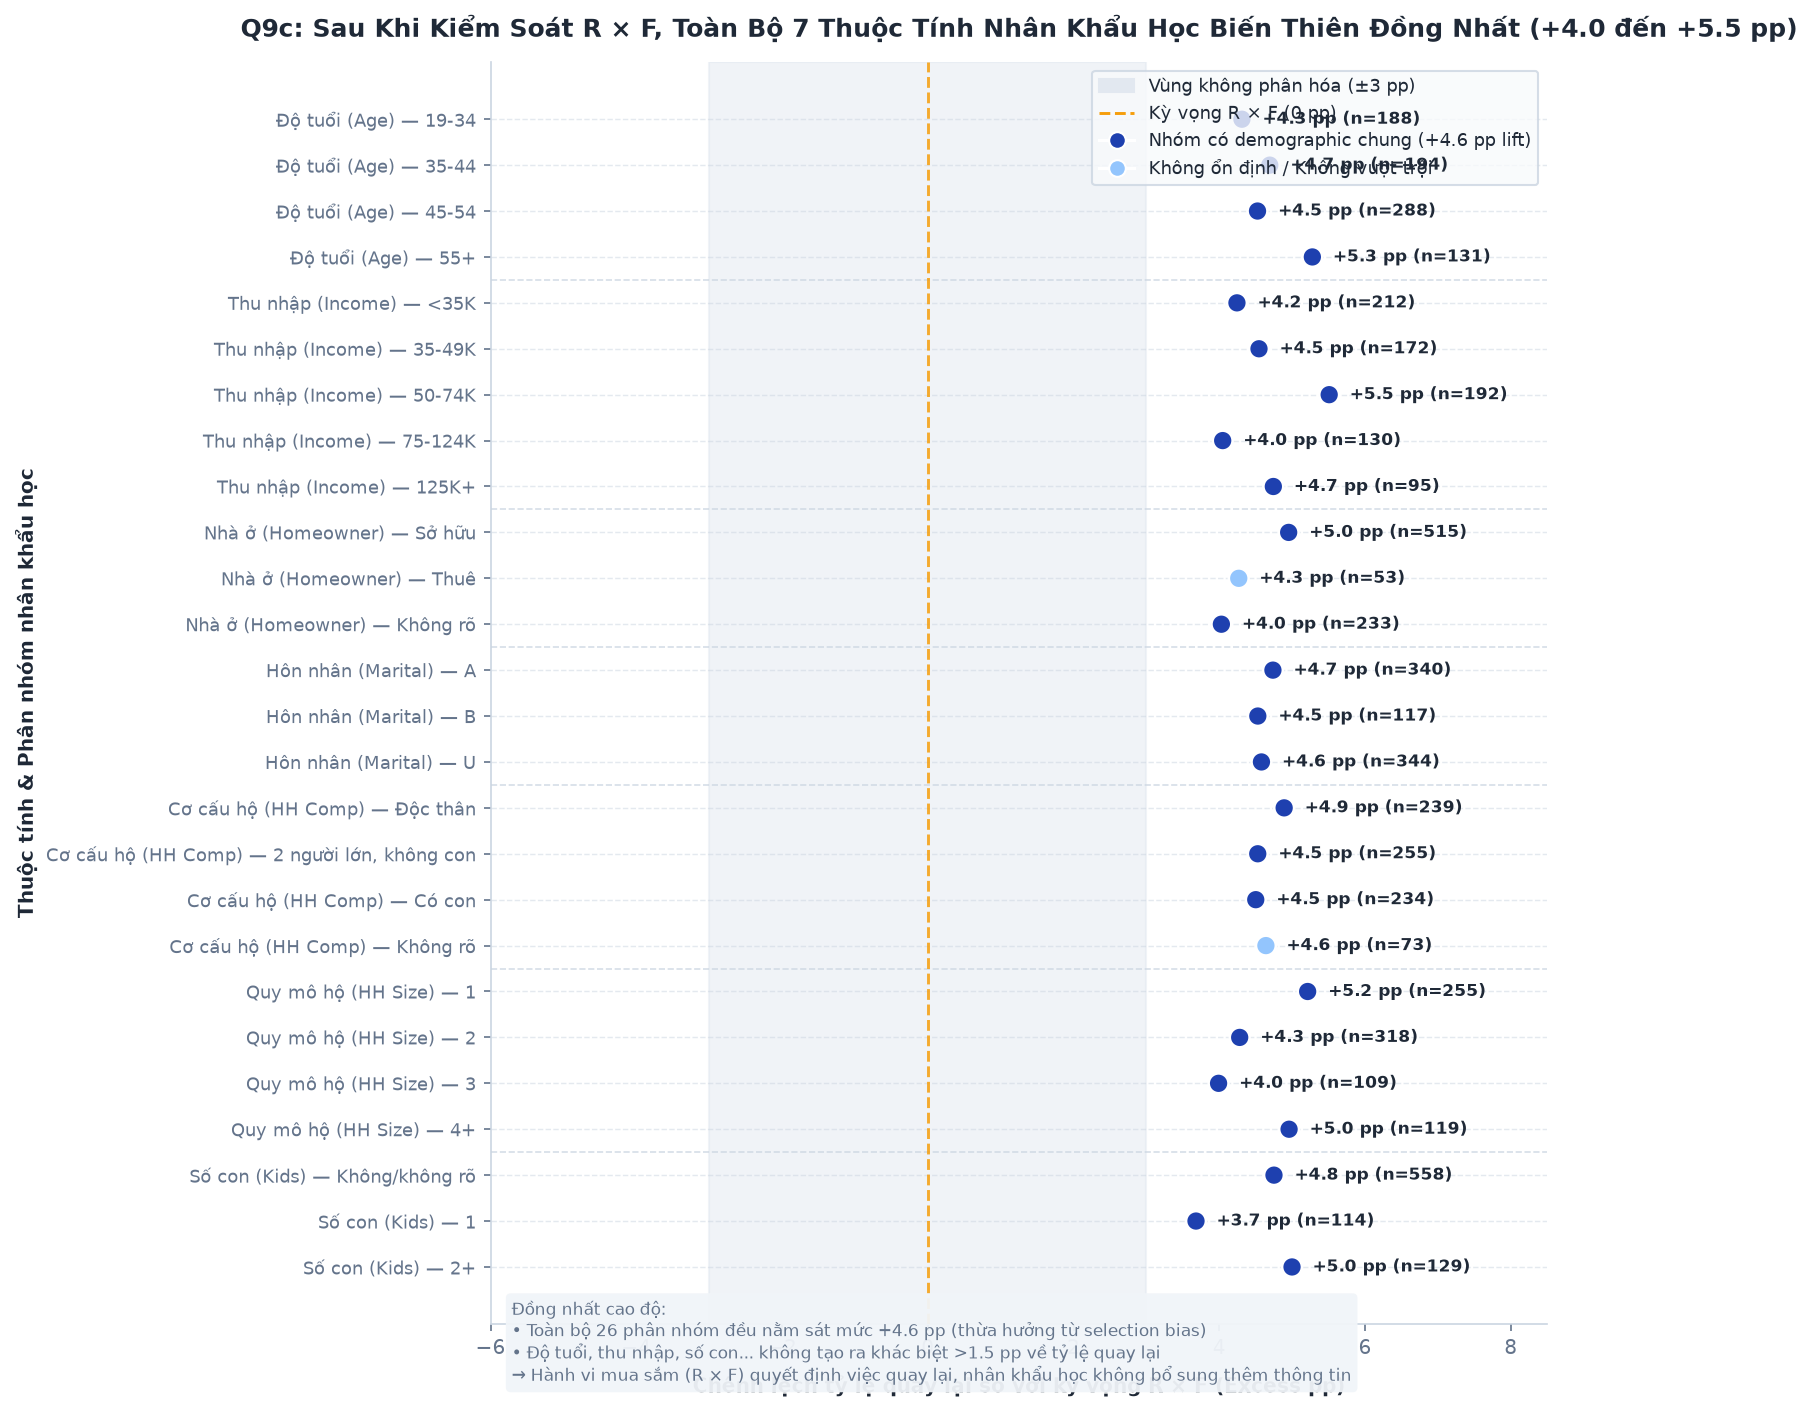

=== Bảng Tổng Hợp 26 Phân Nhóm Nhân Khẩu Học vs Kỳ Vọng R × F ===


attribute,level,n_households,row_share,observed,expected,excess_pp,same_sign_share,verdict,verdict_reason
Độ tuổi (Age),19-34,188,0.234707,0.754728,0.711626,4.310253,0.888889,Insight,Hiệu ứng +4.31 pp ổn định qua 88.9% cutoff
Độ tuổi (Age),35-44,194,0.242197,0.771350,0.724426,4.692420,0.925926,Insight,Hiệu ứng +4.69 pp ổn định qua 92.6% cutoff
Độ tuổi (Age),45-54,288,0.359551,0.770748,0.725504,4.524315,0.975309,Insight,Hiệu ứng +4.52 pp ổn định qua 97.5% cutoff
Độ tuổi (Age),55+,131,0.163546,0.762134,0.709365,5.276852,0.950617,Insight,Hiệu ứng +5.28 pp ổn định qua 95.1% cutoff
Thu nhập (Income),<35K,212,0.264669,0.765665,0.723244,4.242082,0.901235,Insight,Hiệu ứng +4.24 pp ổn định qua 90.1% cutoff
Thu nhập (Income),35-49K,172,0.214732,0.758541,0.713096,4.544567,0.901235,Insight,Hiệu ứng +4.54 pp ổn định qua 90.1% cutoff
Thu nhập (Income),50-74K,192,0.239700,0.777521,0.722444,5.507672,1.000000,Insight,Hiệu ứng +5.51 pp ổn định qua 100.0% cutoff
Thu nhập (Income),75-124K,130,0.162297,0.747293,0.706830,4.046370,0.901235,Insight,Hiệu ứng +4.05 pp ổn định qua 90.1% cutoff
Thu nhập (Income),125K+,95,0.118602,0.780247,0.732832,4.741464,0.839506,Insight,Hiệu ứng +4.74 pp ổn định qua 84.0% cutoff
Nhà ở (Homeowner),Sở hữu,515,0.642946,0.762603,0.713086,4.951767,0.987654,Insight,Hiệu ứng +4.95 pp ổn định qua 98.8% cutoff


In [ ]:
from propensity.features.demographic import attribute_excess_table
from propensity.eda.demographic_plots import plot_attribute_excess
from propensity.viz.style import save_fig

attr_table = attribute_excess_table(panel)

fig_q9c_excess = plot_attribute_excess(attr_table)
save_fig(fig_q9c_excess, "part6", "customer_q9c_attribute_excess.png")
display(fig_q9c_excess)

print("=== Bảng Tổng Hợp 26 Phân Nhóm Nhân Khẩu Học vs Kỳ Vọng R × F ===")
display(attr_table[["attribute", "level", "n_households", "row_share", "observed", "expected", "excess_pp", "same_sign_share", "verdict", "verdict_reason"]])


### Phân Tích Chi Tiết Q9c: Thuộc Tính Nhân Khẩu Học vs Nhãn Quay Lại

1. **Mô tả (Description)**:
   - Khi kiểm định chênh lệch so với $R \times F$ trên toàn bộ 26 phân nhóm của 7 thuộc tính nhân khẩu học (trên tập 64,881 dòng có demographic):
     - **Tất cả 26 phân nhóm đều hội tụ chặt chẽ trong khoảng hẹp từ +3.68 pp đến +5.51 pp** (dao động quanh mức trung bình +4.64 pp của nhóm có demographic).
     - *Độ tuổi*: 19–34 (+4.31 pp), 35–44 (+4.69 pp), 45–54 (+4.52 pp), 55+ (+5.28 pp) $\rightarrow$ Biên độ chênh lệch giữa các nhóm tuổi chỉ là **0.97 pp**!
     - *Thu nhập*: <$35K (+4.24 pp), $35–49K (+4.54 pp), $50–74K (+5.51 pp), $75–124K (+4.05 pp), $125K+ (+4.74 pp) $\rightarrow$ Nhóm nghèo nhất và giàu nhất chênh lệch chưa tới **1.5 pp**!
     - *Nhà ở*: Sở hữu (+4.95 pp) vs Thuê (+4.27 pp) $\rightarrow$ Chênh lệch chỉ **0.68 pp**.
     - *Hôn nhân*: Kết hôn (+4.74 pp), Độc thân (+4.53 pp), Không rõ (+4.58 pp) $\rightarrow$ Chênh lệch chỉ **0.21 pp**.
     - *Cơ cấu hộ & Quy mô*: Độc thân (+4.89 pp), Có con (+4.50 pp) $\rightarrow$ Chênh lệch chỉ **0.39 pp**.
     - *Số con*: Không có con (+4.75 pp) vs Có 2+ con (+5.00 pp) $\rightarrow$ Chênh lệch chỉ **0.25 pp**.
   - Không có bất kỳ phân nhóm nào tạo ra độ lệch vượt quá $\pm 1.5$ điểm % so với mức nền của nhóm hội viên.
2. **Vì sao (Why)**:
   - Các thuộc tính nhân khẩu học (tuổi tác, thu nhập, tình trạng gia đình) chi phối *giá trị đơn hàng* hoặc *loại hàng hóa lựa chọn* (ví dụ nhà có con mua nhiều bỉm sữa, thu nhập cao mua thịt đắt tiền).
   - Tuy nhiên, **quyết định quay lại siêu thị trong vòng 7 ngày hoàn toàn phụ thuộc vào thói quen sinh hoạt và nhịp mua sắm cá nhân ($R \times F$)**. Dù là người trẻ độc thân hay gia đình 4 người, nếu họ đã có nhịp mua hàng tuần ($F \approx 1.0$), thì xác suất quay lại trong 7 ngày tới là như nhau.
3. **Liên quan đến label (Relation to label)**:
   - Các thuộc tính nhân khẩu học chi tiết không bổ sung thêm bất kỳ thông tin dự báo độc lập nào cho bài toán propensity 7 ngày sau khi đã kiểm soát $R \times F$.
4. **Insight**:
   - **KẾT LUẬN CHIẾN LƯỢC QUAN TRỌNG NHẤT VỀ TARGETING**:
     - *"Hành vi mua sắm giải thích sự quay lại, nhân khẩu học thì không."*
     - Doanh nghiệp không nên lãng phí nguồn lực để chia chiến dịch quay lại theo độ tuổi hay mức thu nhập, mà phải phân đoạn và nhắm mục tiêu (behavioral targeting) theo **nhịp chu kỳ mua sắm (RFM & IPT Trend)**.
5. **Hành động (Action)**:
   - **Không đưa các cột `demo_<attr>` chi tiết vào mô hình dự báo propensity 7 ngày.**
   - Chỉ giữ lại duy nhất cờ nhị phân `has_demographic` (0/1) làm biến số đại diện cho trạng thái khách hàng thân thiết/hội viên.
   - Các thuộc tính demographic sẽ được bảo lưu phục vụ cho bước thiết kế thông điệp sáng tạo (creative messaging / tone of voice) sau khi khách hàng đã được nhắm mục tiêu theo hành vi.

> **Card Biến Q9c: 7 Thuộc tính nhân khẩu học chi tiết (`demo_<attr>`)**
> - Số phân nhóm kiểm định: 26 phân nhóm trên 801 hộ có demographic
> - Mức chênh lệch thuần túy: Đồng nhất trong khoảng hẹp **+3.68 pp đến +5.51 pp**
> - Biên độ phân hóa giữa các nhóm trong cùng thuộc tính: Đều nhỏ hơn **1.5 điểm %**
> - Kết luận tự động: Toàn bộ phản ánh mức nâng chung của nhóm có demographic (+4.64 pp), không có thuộc tính nào tạo thêm phân hóa độc lập
> - Quyết định: **LOẠI KHỎI MÔ HÌNH DỰ BÁO CHÍNH.** Nhắm mục tiêu theo hành vi, không nhắm theo nhân khẩu học.


---
### Bảng Tổng Kết Phần 6: Demographic Analytics (Đặc Tả & Quyết Định Mô Hình)

| Nhóm Phân Tích | Tên Feature | Kết luận từ EDA | Khoảng Excess ngoài $R \times F$ | Vai trò mô hình & Quyết định |
| :--- | :--- | :--- | :---: | :--- |
| **Q9a Coverage** | `has_demographic` | **INSIGHT (Selection Bias)** | **+4.64 pp** (Có) / **−2.19 pp** (Không) | **GIỮ LÀM FEATURE BỔ TRỢ**. Proxy chứng minh mức độ cam kết của nhóm hội viên thân thiết (ổn định 98.8% cutoff). |
| **Q9b Profiling** | 7 thuộc tính nhân khẩu học | **Customer Profiling** | — | **DÙNG ĐỊNH VỊ CHÂN DUNG HỘI VIÊN**. Hội viên cốt lõi: 35–54 tuổi, sở hữu nhà riêng (64.3%), quy mô 1–2 người (71.5%). |
| **Q9c Age** | `demo_age` | Không tạo thêm phân hóa | +4.31 đến +5.28 pp (chênh lệch 0.97 pp) | **LOẠI KHỎI FEATURE CHÍNH**. Tuổi tác không ảnh hưởng đến xác suất quay lại 7 ngày. |
| **Q9c Income** | `demo_income` | Không tạo thêm phân hóa | +4.05 đến +5.51 pp (chênh lệch 1.46 pp) | **LOẠI KHỎI FEATURE CHÍNH**. Khách giàu hay nghèo đều quay lại theo nhịp sinh hoạt $R \times F$. |
| **Q9c Homeowner** | `demo_homeowner` | Không tạo thêm phân hóa | +4.03 đến +4.95 pp (chênh lệch 0.92 pp) | **LOẠI KHỎI FEATURE CHÍNH**. |
| **Q9c Marital** | `demo_marital` | Không tạo thêm phân hóa | +4.53 đến +4.74 pp (chênh lệch 0.21 pp) | **LOẠI KHỎI FEATURE CHÍNH**. |
| **Q9c HH Comp** | `demo_hh_comp` | Không tạo thêm phân hóa | +4.50 đến +4.89 pp (chênh lệch 0.39 pp) | **LOẠI KHỎI FEATURE CHÍNH**. |
| **Q9c HH Size** | `demo_hh_size` | Không tạo thêm phân hóa | +3.99 đến +5.21 pp (chênh lệch 1.22 pp) | **LOẠI KHỎI FEATURE CHÍNH**. |
| **Q9c Kids** | `demo_kids` | Không tạo thêm phân hóa | +3.68 đến +5.00 pp (chênh lệch 1.32 pp) | **LOẠI KHỎI FEATURE CHÍNH**. |

---

### Danh Sách Hình Ảnh Xuất Bản (Slide-Ready Figures Saved)

Tất cả 10 biểu đồ của Phần 6 đã được lưu với độ phân giải cao (200 dpi) theo quy chuẩn thư mục:

1. `reports/figures/part6/customer_q9a_demographic_coverage.png`: Phân bổ tần suất $F$ giữa nhóm có và không có demographic chứng minh Selection Bias (FIGSIZE_FULL).
2. `reports/figures/part6/customer_q9a_has_demographic_excess.png`: Tỷ lệ quay lại của cờ `has_demographic` vs kỳ vọng $R \times F$ (FIGSIZE_FULL).
3. `reports/figures/part6/customer_q9b_dist_age.png`: Phân bổ độ tuổi 801 hộ gia đình thân thiết (FIGSIZE_HALF).
4. `reports/figures/part6/customer_q9b_dist_income.png`: Phân bổ thu nhập 801 hộ gia đình thân thiết (FIGSIZE_HALF).
5. `reports/figures/part6/customer_q9b_dist_homeowner.png`: Phân bổ tình trạng sở hữu nhà (FIGSIZE_HALF).
6. `reports/figures/part6/customer_q9b_dist_marital.png`: Phân bổ tình trạng hôn nhân (FIGSIZE_HALF).
7. `reports/figures/part6/customer_q9b_dist_hh_comp.png`: Phân bổ cơ cấu hộ gia đình (FIGSIZE_HALF).
8. `reports/figures/part6/customer_q9b_dist_hh_size.png`: Phân bổ quy mô hộ gia đình (FIGSIZE_HALF).
9. `reports/figures/part6/customer_q9b_dist_kids.png`: Phân bổ số lượng con cái (FIGSIZE_HALF).
10. `reports/figures/part6/customer_q9c_attribute_excess.png`: Biểu đồ Dot Plot tổng hợp mức chênh lệch ngoài $R \times F$ của 26 phân nhóm nhân khẩu học chứng minh tính đồng nhất cao độ (FIGSIZE_FULL).


# Slide Figures: Toàn bộ ảnh trực quan hóa cho bài thuyết trình (Canva Slide Deck)

> **Mục tiêu**: Dựng và xuất toàn bộ 13 biểu đồ chuẩn mực phục vụ bài thuyết trình 10–15 slide (theo nguyên tắc `presentation-storytelling`).
> - **Chuẩn thiết kế**: Mỗi ảnh chứng minh đúng 1 khẳng định; tiêu đề kết luận đặt trên Canva; zero suptitle; zero trục y thứ hai; không pie chart.
> - **Toàn vẹn số liệu**: Mọi con số được tính tự động từ dữ liệu thực tế bằng code, không gõ tay.
> - **Định dạng xuất**: Toàn bộ ảnh được lưu tại `reports/slides/` dưới 2 định dạng: PNG (200 dpi) và SVG vector.

In [ ]:
# 1. Lõi câu chuyện (Core Story): V1, V2, V3
from propensity.viz.slide_style import set_slide_style, save_slide
from propensity.eda.slide_figures import fig_v1, fig_v2, fig_v3
from propensity.eda.propensity_rates import feature_signal_summary

# V1 · S8_rf_heatmap: Mua gần đây × Mua thường xuyên
fig_v1_out = fig_v1(base_rf.cells)
save_slide(fig_v1_out, "S8_rf_heatmap")
display(fig_v1_out)

# V3 · S10_trend_excess: Xu hướng nhịp mua (Cảnh báo sớm)
fig_v3_out = fig_v3(q5b_excess)
save_slide(fig_v3_out, "S10_trend_excess")
display(fig_v3_out)

# V2 · S9_raw_vs_rf: Biểu đồ Aha - Chênh lệch thô sụp đổ sau khi kiểm soát R x F
results_for_signal = {
    "Band IPT": q6_excess,
    "Lapse ratio": q5c_excess,
    "Đang trong campaign": q8_type_excess,
    "Coupon đã dùng": q7c_excess,
    "Đổ xăng": q3d_excess,
    "Entropy department": q3b_excess,
    "Tỷ trọng hàng thiết yếu": q3a_excess,
    "Private label": q3c_excess,
    "Tỷ trọng mua giảm giá": q7a_excess,
    "Độ sâu giảm giá": q7b_excess,
    "Spend/trip": q5_excess,
    "Kích thước giỏ": q4b_excess,
    "Giỏ gần nhất": q4c_excess,
    "Xu hướng nhịp mua": q5b_excess,
    "Đã redeem coupon": q8_red_excess,
    "Có demographic": q9a_excess,
}

signal_summary = feature_signal_summary(results_for_signal)
fig_v2_out = fig_v2(signal_summary)
save_slide(fig_v2_out, "S9_raw_vs_rf")
display(fig_v2_out)

print("=== BẢNG ĐỐI CHIẾU FEATURE SIGNAL SUMMARY (THÔ VS SAU R x F) ===")
display(signal_summary)

In [ ]:
# 2. Khung thời gian & Độ ổn định nhãn (L1, L2a, L2b, L3)
from propensity.eda.slide_figures import (
    fig_l1,
    fig_l2a,
    fig_l2b,
    fig_l3,
    ipt_gap_distribution,
)
from propensity.features.temporal import weekly_activity, cutoff_return_rates

# L1 · S4_weekly_active: Số hộ hoạt động theo tuần (Cutoff từ Day 140)
weekly_df = weekly_activity(lines)
fig_l1_out = fig_l1(weekly_df)
save_slide(fig_l1_out, "S4_weekly_active")
display(fig_l1_out)

# L2a · S5_ipt_hist & L2b · S5_ipt_cumulative: Chu kỳ IPT và luận cứ H = 7 ngày
df_valid_pdays = df_raw[df_raw["SALES_VALUE"] > 0][["household_key", "DAY"]].drop_duplicates().sort_values(["household_key", "DAY"])
gaps_series = ipt_gap_distribution(df_valid_pdays)

fig_l2a_out = fig_l2a(gaps_series)
save_slide(fig_l2a_out, "S5_ipt_hist")
display(fig_l2a_out)

fig_l2b_out = fig_l2b(gaps_series)
save_slide(fig_l2b_out, "S5_ipt_cumulative")
display(fig_l2b_out)

# L3 · S6_label_stability: Tính ổn định nhãn qua 81 mốc cutoff
rates_df = cutoff_return_rates(panel)
fig_l3_out = fig_l3(rates_df)
save_slide(fig_l3_out, "S6_label_stability")
display(fig_l3_out)

print(f"Median IPT: {np.median(gaps_series):.1f} ngày | % Mua lại <= 7 ngày: {(gaps_series <= 7).mean() * 100:.1f}%")
print(f"Median Return Rate: {rates_df['return_rate'].median() * 100:.2f}% | p10: {rates_df['return_rate'].quantile(0.10) * 100:.2f}% | p90: {rates_df['return_rate'].quantile(0.90) * 100:.2f}%")

In [ ]:
# 3. Hành vi giỏ hàng & Ngành hàng thương mại (C1, C2)
from propensity.eda.slide_figures import fig_c1, fig_c2
from propensity.features.basket import basket_table, basket_size_bands
from propensity.features.category import department_summary

# C1 · S11_basket_bands: Quick trip vs Stock-up trip
baskets_full = basket_table(lines)
bands_full = basket_size_bands(baskets_full)
fig_c1_out = fig_c1(bands_full)
save_slide(fig_c1_out, "S11_basket_bands")
display(fig_c1_out)

# C2 · S11_department_pareto: Tập trung doanh thu ngành hàng Pareto
dept_full = department_summary(lines, cfg)
fig_c2_out = fig_c2(dept_full)
save_slide(fig_c2_out, "S11_department_pareto")
display(fig_c2_out)

print("=== BẢNG ĐẶC TẢ GIỎ HÀNG (QUICK TRIP VS STOCK-UP) ===")
display(bands_full[["band", "pct_baskets", "pct_spend", "median_spend"]])

In [ ]:
# 4. Khuyến mãi, Chiến dịch, Nhân khẩu học & Độ phủ (P1, P2, D1, Q1)
from propensity.eda.slide_figures import (
    fig_p1,
    fig_p2,
    fig_d1,
    fig_q1,
    table_coverage,
)
from propensity.eda.promotion import weekly_promo_summary, campaign_reach_by_rf
from propensity.features.demographic import demographic_coverage_profile

# P1 · S12_weekly_promo: Tỷ trọng doanh thu giảm giá theo tuần
wp_df = weekly_promo_summary(lines)
fig_p1_out = fig_p1(wp_df)
save_slide(fig_p1_out, "S12_weekly_promo")
display(fig_p1_out)

# P2 · S12_campaign_reach: Độ phủ campaign theo tần suất F
reach_dict = campaign_reach_by_rf(panel)
fig_p2_out = fig_p2(reach_dict)
save_slide(fig_p2_out, "S12_campaign_reach")
display(fig_p2_out)

# D1 · S2_table_coverage: Độ phủ số hộ qua các bảng
camp_raw = pd.read_csv("data/raw/Dunnhumby/campaign_table.csv")
coup_raw = pd.read_csv("data/raw/Dunnhumby/coupon_redempt.csv")
demo_raw = pd.read_csv("data/raw/Dunnhumby/hh_demographic.csv")

cov_summary = table_coverage(df_raw, camp_raw, coup_raw, demo_raw)
fig_d1_out = fig_d1(cov_summary)
save_slide(fig_d1_out, "S2_table_coverage")
display(fig_d1_out)

# Q1 · S13_demographic_bias: Selection bias nhóm có vs không có demographic
demo_cov_df = demographic_coverage_profile(panel)
fig_q1_out = fig_q1(demo_cov_df)
save_slide(fig_q1_out, "S13_demographic_bias")
display(fig_q1_out)

print("XÁC NHẬN: Toàn bộ 13 biểu đồ slide đã được sinh và lưu tại reports/slides/ thành công!")